In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_experiments import *
import os
from tqdm import tqdm

In [2]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])


notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)



notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'



poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'


IR_spectra_amb = pd.read_csv('processed_data_new/data_ir_amb_rebecca.csv')
del IR_spectra_amb['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_amb.columns = list(np.float64(IR_spectra_amb.columns[:-8])) + list(IR_spectra_amb.columns[-8:])
IR_spectra_amb_rest = IR_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)

#IR_spectra_amb = IR_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
#IR_spectra_amb = IR_spectra_amb.loc[[x in ['AMB','LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)

IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'AMB','polymer'] = 'z_AMB'

IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'LOW','polymer'] = 'z_LOW'
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'MIX','polymer'] = 'z_MIX'
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'UNS','polymer'] = 'z_UNS'

Raman_spectra_amb = pd.read_csv('processed_data_new/data_raman_amb_rebecca_specy.csv')
del Raman_spectra_amb['Unnamed: 0']
Raman_spectra_amb.columns = list(np.float64(Raman_spectra_amb.columns[:-7])) + list(Raman_spectra_amb.columns[-7:])
Raman_spectra_amb_rest = Raman_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
#Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL', 'AMB'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
#Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['AMB','LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)


Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'AMB','polymer'] = 'z_AMB'

Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'LOW','polymer'] = 'z_LOW'
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'MIX','polymer'] = 'z_MIX'
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'UNS','polymer'] = 'z_UNS'


poly_list_amb = poly_list+['z_AMB']+['AMB']
ids_ideal_set = [(x in poly_list_amb) and (y in poly_list_amb) and (z in poly_list_amb) for x, y, z in zip(Raman_spectra_amb['polymer_raman'], Raman_spectra_amb['polymer_ir'], Raman_spectra_amb['polymer'])]

IR_spectra_amb = IR_spectra_amb.iloc[:,list(range(IR_spectra_amb.shape[1]-8))+[-8,-7,-5,-4,-3,-6,-2,-1]]
Raman_spectra_amb = Raman_spectra_amb.iloc[:,list(range(Raman_spectra_amb.shape[1]-4))+[-1]]
idx_nan_raman = np.isnan(Raman_spectra_amb.iloc[:,:-4]).sum(1)>0

Raman_spectra_amb = Raman_spectra_amb.loc[~idx_nan_raman,:].reset_index(drop=True)
IR_spectra_amb = IR_spectra_amb.loc[~idx_nan_raman,:].reset_index(drop=True)


Raman_spectra_amb['id'] = ["amb_"+str(x) for x in Raman_spectra_amb['id']]
IR_spectra_amb['id'] = ["amb_"+str(x) for x in IR_spectra_amb['id']]

IR_spectra_amb.to_csv('results_final/data_fig_5_ir_amb_processed_.csv')
Raman_spectra_amb.to_csv('results_final/data_fig_5_raman_amb_processed.csv')

rebecca_data_ir = rebecca_data_ir.query('polymer in ["PE", "PP", "PSL"]').reset_index(drop=True)
rebecca_data_raman = rebecca_data_raman.query('polymer in ["PE", "PP", "PSL"]').reset_index(drop=True)
IR_spectra_all = pd.concat([IR_spectra_mix_std.query('polymer in ["PE", "PP", "PSL"]'), 
                            IR_spectra_mix], axis=0).reset_index(drop=True)

Raman_spectra_all = pd.concat([Raman_spectra_mix_std.query('polymer in ["PE", "PP", "PSL"]'), 
                               Raman_spectra_mix], axis=0).reset_index(drop=True)


wn_raman = np.float64(rebecca_data_raman.columns[:-4])

lower_range_raman_1 = 1250
upper_range_raman_1 = 2000
lower_range_raman_2 = 2350
upper_range_raman_2 = 3200

idx_raman = list(np.logical_or(np.logical_and(wn_raman >lower_range_raman_1,
                           wn_raman <upper_range_raman_1
                           ),
                 np.logical_and(wn_raman >lower_range_raman_2,
                           wn_raman <upper_range_raman_2
                           ))) + [True]*4

(x_train_ir, 
 x_train_raman, 
 label_train_IR, 
 label_train_Raman, 
 x_ir, x_raman, label_ir, label_raman, 
 label_table, ids_cal) = process_data(rebecca_data_ir,
                                      rebecca_data_raman,#.loc[:, idx_raman],
                                      IR_spectra_all,
                                      Raman_spectra_all#.loc[:, idx_raman]
                                      )

                                      
(_, _, _, _, 
 x_amb_ir, x_amb_raman, label_amb_ir, 
 label_amb_raman, 
 label_amb_table, ids_test) = process_data(rebecca_data_ir,
                                           rebecca_data_raman,#.loc[:, idx_raman],
                                           IR_spectra_amb,
                                           Raman_spectra_amb#.loc[:, idx_raman] 
                                           )
                                           

smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman, tau=1.4427),1)

smx_all_IR_test = 1-np.power(smx_nn(x_train_ir, x_amb_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman_test = 1-np.power(smx_nn(x_train_raman, x_amb_raman, label_train_Raman, tau=1.4427),1)

smx_all_IR_test_all = 1-np.power(smx_nn_all(x_train_ir, x_amb_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman_test_all = 1-np.power(smx_nn_all(x_train_raman, x_amb_raman, label_train_Raman, tau=1.4427),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]
score_all_list = [smx_all_IR_test_all, smx_all_Raman_test_all]

In [5]:
Raman_spectra_amb.groupby('polymer').count()['id']

polymer
PE        32
PP         6
PSL       33
z_AMB     51
z_LOW    119
z_MIX     11
z_UNS      1
Name: id, dtype: int64

In [ ]:
IR_spectra_all.groupby('polymer').count()['id']

In [116]:
TPR = defaultdict(list)
FPR = defaultdict(list)
F_1 = defaultdict(list)
U_quant_env_list = defaultdict(list)
prediction_sets_list = defaultdict(list)

N_sim = 10
N_alpha = 99
for i in tqdm(range(N_sim)):
    seed = i
    K = 2
    quant_smx_list = []
    rest_smx_list = []
    cal_smx_list = []
    val_smx_list = []
    U_list = gen_u(K, seed=0)

    
    label_cal_ir = label_ir
    val_labels = None

    for i in range(K):
        quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.2, seed=seed)

        val_smx, _ = score_list_test[i], None

        quant_smx_list.append(quant_smx)
        cal_smx_list.append(cal_smx)
        val_smx_list.append(val_smx)

    n = cal_labels.shape[0]

    for alpha in (np.linspace(0.01,.99,N_alpha)):

        prediction_sets, U_quant_env = mvcp_2(quant_smx_list, 
                                                     quant_labels,   
                                                     cal_smx_list,   
                                                     cal_labels,   
                                                     val_smx_list,   
                                                     alpha,     
                                                     val_labels,                 
                                                     U=U_list[0])

        U_quant_env_list[round(alpha*100)].append(U_quant_env)
        prediction_sets_n_mvcp = [list(label_table.loc[ps,'polymer']) for ps in prediction_sets]
        prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])
        
        prediction_sets_list[round(alpha*100)].append(prediction_sets.sum(1).mean())
            
        TPR[round(alpha*100)].append(np.mean(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), 
                                                                     label_amb_ir[label_amb_ir<3]]))

        FPR[round(alpha*100)].append(np.sum(label_amb_ir[prediction_sets_size>0] >= 3) / sum(label_amb_ir >= 3))
        
        Precision = np.sum(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), 
                                                                     label_amb_ir[label_amb_ir<3]]) / sum(prediction_sets.sum(1)>0)
        
        Recall = np.mean(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]), 
                                                                     label_amb_ir[label_amb_ir<3]])
        
        F_1[round(alpha*100)].append(
        2 * (Precision * Recall) / (Precision + Recall)
        )

  0%|                                                    | 0/10 [00:00<?, ?it/s]/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_23595/4145098444.py:55: RuntimeWarning: invalid value encountered in scalar divide
  Precision = np.sum(prediction_sets[label_amb_ir<3,:][np.arange(label_amb_ir[label_amb_ir<3].shape[0]),
100%|███████████████████████████████████████████| 10/10 [03:00<00:00, 18.08s/it]


Int64Index([99, 98, 97, 96, 95, 94, 93, 92, 91, 90, 89, 88, 87, 86, 85, 84, 83,
            82, 81, 80, 79, 78, 77, 76, 75, 74, 73, 72, 71, 70, 69, 68, 67, 66,
            65, 64, 63, 62, 61, 60, 59, 58, 57, 56, 55, 54, 53, 52, 51, 50, 49,
            48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 33, 32,
            31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15,
            14, 13, 12, 11, 10,  9,  8,  7,  6,  5,  4,  3,  2,  1],
           dtype='int64')

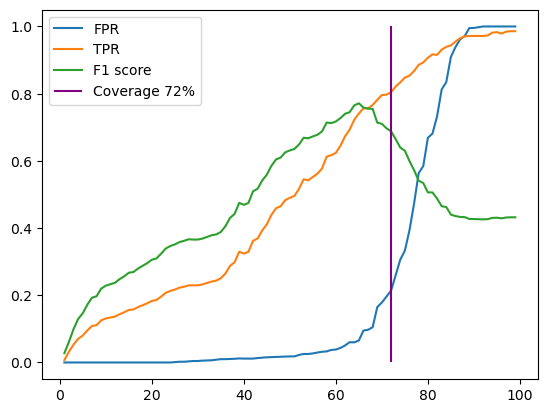

In [142]:
plt.plot(100-pd.DataFrame(FPR).mean().index,
         pd.DataFrame(FPR).mean(), label='FPR')
plt.plot(100-pd.DataFrame(FPR).mean().index,
         pd.DataFrame(TPR).mean(), label='TPR')
plt.plot(100-pd.DataFrame(FPR).mean().index,
         pd.DataFrame(F_1).mean(), label='F1 score')
plt.vlines(72,0,1, color='purple', label='Coverage 72%')
plt.legend()

In [129]:
(pd.DataFrame(FPR).mean()[35],
 pd.DataFrame(TPR).mean()[35],
 pd.DataFrame(F_1).mean()[35])

(0.06538461538461539, 0.7408450704225351, 0.7713449403752154)

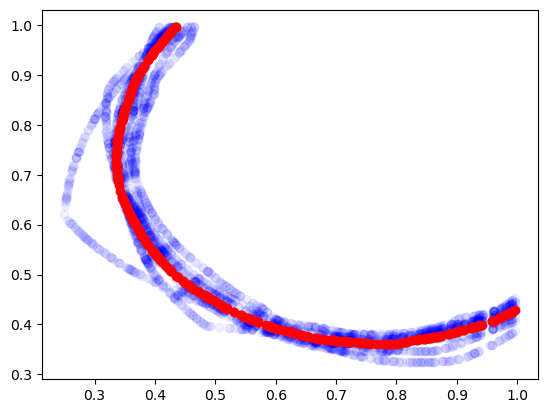

In [107]:
df_calibration = pd.DataFrame({
    'IR':1-score_list[0][range(label_cal_ir.shape[0]), label_cal_ir],
    'Raman':1-score_list[1][range(label_cal_ir.shape[0]), label_cal_ir]})

#df_calibration.to_csv(directory_name+'/data_fig_5_calibration.csv')

for x in U_quant_env_list[10]:
    plt.scatter(1-x[:,0],
                1-x[:,1], color='blue', alpha=.05)

_ = plt.scatter(
    1-np.array(U_quant_env_list[10]).mean(0)[:,0],
    1-np.array(U_quant_env_list[10]).mean(0)[:,1], color='red')



for i, alpha in enumerate(U_quant_env_list.keys()):#[2, 5, 10, 20, 40]:#enumerate(U_quant_env_list.keys()):
    if i == 0:
        df_envelopes = pd.DataFrame({
            'x - '+str(100-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,0],
            'y - '+str(100-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,1]
                      })
    else:
        df_envelopes = pd.concat([df_envelopes,
                        pd.DataFrame({
                            'x - '+str(100-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,0],
                            'y - '+str(100-alpha) + ' (mean)':1-np.array(U_quant_env_list[alpha]).mean(0)[:,1]
                      })], axis=1)
for i, alpha in enumerate(U_quant_env_list.keys()):#[2, 5, 10, 20, 40]:#enumerate(U_quant_env_list.keys()):
    df_envelopes = pd.concat([
        df_envelopes,
        pd.DataFrame({
                            'x - '+str(100-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,0],
                            'y - '+str(100-alpha) + ' (standard deviation)':1-np.array(U_quant_env_list[alpha]).std(0)[:,1]
                      })], axis=1)


100%|███████████████████████████████████████████| 99/99 [02:49<00:00,  1.72s/it]


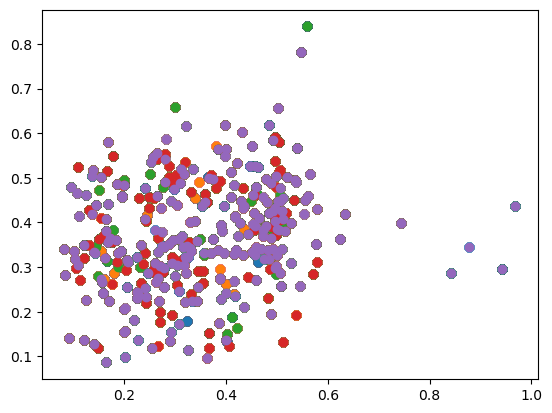

In [108]:
id_ = 20
score_example = [score_list_test[0][id_:id_+1], 
                 score_list_test[1][id_:id_+1]] 

(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list) = envelop(score_list, 
                         label_ir, 
                         score_example,
                         alphas=list(np.round(np.linspace(0.01,.99,N_alpha), 2)),
                         label_table=label_table,
                         N_sim=5, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0, 
                         plot=False)

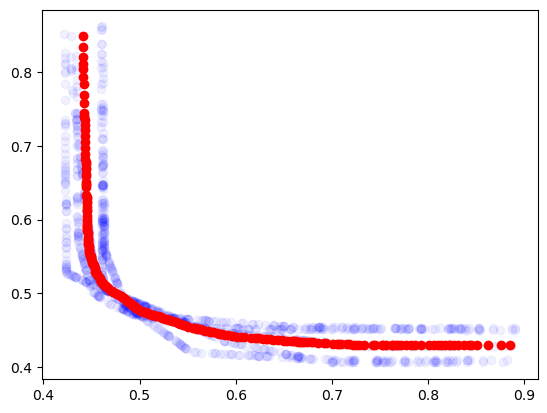

In [109]:
for x in env_list[10]:
    plt.scatter(1-x[0],
                1-x[1], color='blue', alpha=.05)

_ = plt.scatter(
    1-np.mean(env_list[10], 0)[0],
    1-np.mean(env_list[10], 0)[1], color='red')

In [110]:
for i, alpha in enumerate(env_list.keys()):#[2, 5, 10, 20, 40]:#enumerate(U_quant_env_list.keys()):
    if i == 0:
        df_envelopes = pd.DataFrame({
            'x - '+str(100-alpha) + ' (mean)':1-np.mean(env_list[alpha],0)[0],
            'y - '+str(100-alpha) + ' (mean)':1-np.mean(env_list[alpha],0)[1]
                      })
    else:
        df_envelopes = pd.concat([df_envelopes,
                        pd.DataFrame({
                            'x - '+str(100-alpha) + ' (mean)':1-np.mean(env_list[alpha],0)[0],
                            'y - '+str(100-alpha) + ' (mean)':1-np.mean(env_list[alpha],0)[1]
                      })], axis=1)
for i, alpha in enumerate(env_list.keys()):#[2, 5, 10, 20, 40]:#enumerate(U_quant_env_list.keys()):
    df_envelopes = pd.concat([
        df_envelopes,
        pd.DataFrame({
                            'x - '+str(100-alpha) + ' (standard deviation)':np.std(env_list[alpha],0)[0],
                            'y - '+str(100-alpha) + ' (standard deviation)':np.std(env_list[alpha],0)[1]
                      })], axis=1)


In [111]:
df_envelopes

,x - 99 (mean),y - 99 (mean),x - 98 (mean),y - 98 (mean),x - 97 (mean),y - 97 (mean),x - 96 (mean),y - 96 (mean),x - 95 (mean),y - 95 (mean),...,x - 5 (standard deviation),y - 5 (standard deviation),x - 4 (standard deviation),y - 4 (standard deviation),x - 3 (standard deviation),y - 3 (standard deviation),x - 2 (standard deviation),y - 2 (standard deviation),x - 1 (standard deviation),y - 1 (standard deviation)
0,0.816822,0.089697,0.841204,0.210810,0.855858,0.283836,0.867551,0.342196,0.873943,0.373848,...,0.001458,0.009288,0.001400,0.008780,0.002473,0.013437,0.006309,0.031235,0.003326,0.014901
1,0.800383,0.089794,0.826764,0.210895,0.842894,0.283912,0.856030,0.342264,0.863475,0.373910,...,0.002730,0.009302,0.002974,0.008792,0.002783,0.013448,0.006016,0.031241,0.004788,0.014896
2,0.779627,0.089916,0.808931,0.211000,0.826576,0.284008,0.840633,0.342354,0.848553,0.373998,...,0.002876,0.009299,0.002676,0.008793,0.003610,0.013442,0.007533,0.031232,0.005722,0.014889
3,0.761136,0.090025,0.792858,0.211094,0.812135,0.284093,0.827508,0.342432,0.836140,0.374071,...,0.003982,0.009298,0.003505,0.008794,0.004580,0.013440,0.007852,0.031232,0.006297,0.014886
4,0.751892,0.090079,0.784934,0.211141,0.804701,0.284137,0.820422,0.342473,0.829185,0.374112,...,0.002002,0.009294,0.001973,0.008787,0.003366,0.013437,0.008695,0.031223,0.005695,0.014888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,-0.043631,0.633175,0.102621,0.684366,0.175625,0.710368,0.223764,0.727154,0.203786,0.720592,...,0.020965,0.007314,0.020749,0.006699,0.014557,0.003664,0.016177,0.004251,0.010112,0.003470
227,-0.043698,0.645576,0.102562,0.695282,0.175570,0.720533,0.223711,0.736956,0.201085,0.729634,...,0.020964,0.007552,0.020747,0.006986,0.014552,0.004700,0.016172,0.005392,0.010106,0.004247
228,-0.043798,0.663992,0.102476,0.711183,0.175491,0.735316,0.223633,0.751282,0.199919,0.743925,...,0.020965,0.007439,0.020748,0.006989,0.014548,0.005615,0.016165,0.006600,0.010100,0.005211
229,-0.043928,0.688222,0.102361,0.732480,0.175384,0.755043,0.223533,0.769822,0.199815,0.763172,...,0.020964,0.008791,0.020749,0.008230,0.014547,0.007051,0.016165,0.007558,0.010099,0.006203


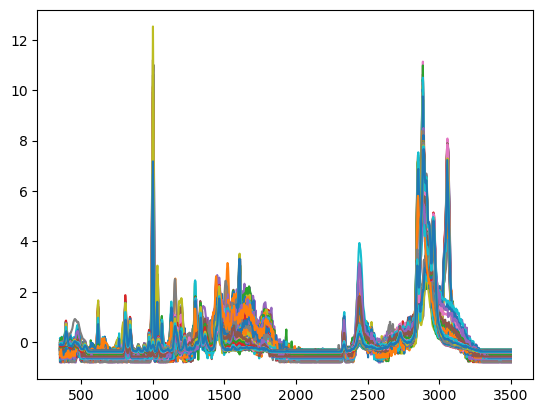

In [117]:
_ = plt.plot(rebecca_data_raman.iloc[:,:-4].T)

In [4]:
[np.mean(np.argmin(smx_all_IR, 1) == label_ir),
np.mean(np.argmin(smx_all_Raman, 1) == label_raman)]

[0.8670360110803325, 0.8227146814404432]

In [5]:
[np.mean(np.argmin(smx_all_IR_test[label_amb_ir<3], 1) == label_amb_ir[label_amb_ir<3]),
 np.mean(np.argmin(smx_all_Raman_test[label_amb_ir<3], 1) == label_amb_raman[label_amb_ir<3])]

[0.9436619718309859, 0.8591549295774648]

In [6]:
from scipy.stats import entropy

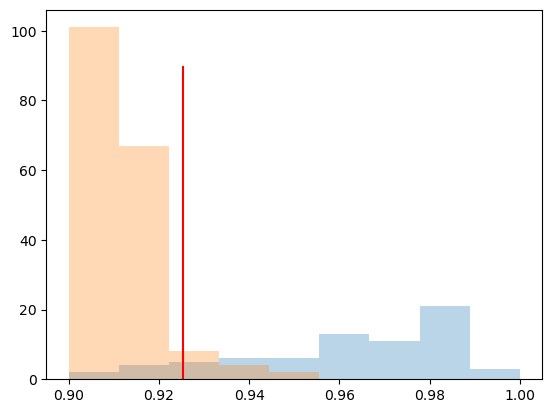

In [7]:
hist_test_mp = plt.hist(1-np.min(smx_all_IR_test[label_amb_ir<3], 1), 
                        alpha=.3, density=False, bins=np.linspace(.9,1,10))

hist_test_amb = plt.hist(1-np.min(smx_all_IR_test[label_amb_ir>=3], 1), 
                         alpha=.3, density=False, bins=np.linspace(.9,1,10))

_ = plt.vlines(np.quantile(1-np.min(smx_all_IR_test[label_amb_ir<3], 1),.1),0,90,color='red')

In [8]:
entropy(hist_test_amb[0] / hist_test_amb[0].sum(),
        hist_test_mp[0] / hist_test_mp[0].sum())

2.272370631133596

0 1.2659983317771895


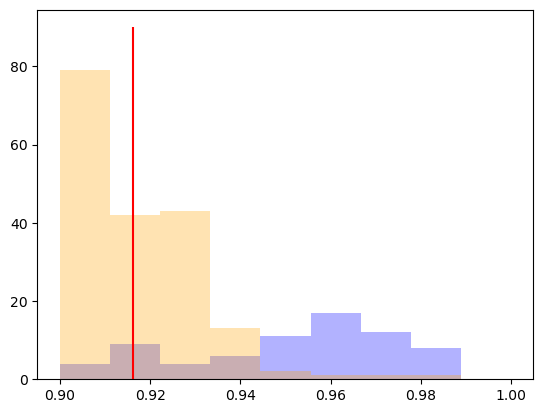

In [9]:
for x in [0]:
    lower_range_raman_1 = 1250
    upper_range_raman_1 = 2000
    lower_range_raman_2 = 2350
    upper_range_raman_2 = 3200

    idx_raman = list(np.logical_or(np.logical_and(wn_raman >lower_range_raman_1,
                               wn_raman <upper_range_raman_1
                               ),
                     np.logical_and(wn_raman >lower_range_raman_2,
                               wn_raman <upper_range_raman_2
                               ))) + [True]*4

    (x_train_ir, 
     x_train_raman, 
     label_train_IR, 
     label_train_Raman, 
     x_ir, x_raman, label_ir, label_raman, 
     label_table, ids_cal) = process_data(rebecca_data_ir,
                                          rebecca_data_raman.loc[:, idx_raman],
                                          IR_spectra_all,
                                          Raman_spectra_all.loc[:, idx_raman]
                                          )


    (_, _, _, _, 
     x_amb_ir, x_amb_raman, label_amb_ir, 
     label_amb_raman, 
     label_amb_table, ids_test) = process_data(rebecca_data_ir,
                                               rebecca_data_raman.loc[:, idx_raman],
                                               IR_spectra_amb,
                                               Raman_spectra_amb.loc[:, idx_raman] 
                                               )


    smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
    smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)

    smx_all_IR_test = 1-np.power(smx_nn(x_train_ir, x_amb_ir, label_train_IR),1)
    smx_all_Raman_test = 1-np.power(smx_nn(x_train_raman, x_amb_raman, label_train_Raman),1)

    smx_all_IR_test_all = 1-np.power(smx_nn_all(x_train_ir, x_amb_ir, label_train_IR),1)
    smx_all_Raman_test_all = 1-np.power(smx_nn_all(x_train_raman, x_amb_raman, label_train_Raman),1)


    score_list = [smx_all_IR, smx_all_Raman]
    score_list_test = [smx_all_IR_test, smx_all_Raman_test]
    score_all_list = [smx_all_IR_test_all, smx_all_Raman_test_all]

    hist_test_mp = plt.hist(1-np.min(smx_all_Raman_test[label_amb_ir<3], 1), 
                            alpha=.3, density=False, bins=np.linspace(.9,1,10), color='blue')

    hist_test_amb = plt.hist(1-np.min(smx_all_Raman_test[label_amb_ir>=3], 1), 
                             alpha=.3, density=False, bins=np.linspace(.9,1,10), color='orange')

    _ = plt.vlines(np.quantile(1-np.min(smx_all_Raman_test[label_amb_ir<3], 1),.1),0,90,color='red')
    
    print(x, entropy(hist_test_amb[0] / hist_test_amb[0].sum(),
            hist_test_mp[0] / hist_test_mp[0].sum())    )

In [10]:
label_amb_table

,label,polymer
0,0,PE
1,1,PP
2,2,PSL
3,3,z_AMB
4,4,z_LOW
5,5,z_MIX
6,6,z_UNS


In [131]:
data_fig_5_envelopes = pd.read_csv('results_final/20250923/data_fig_5_envelopes.csv')
data_fig_5_top_hqi_values = pd.read_csv('results_final/20250923/data_fig_5_top_hqi_values.csv')

del data_fig_5_envelopes['Unnamed: 0']
del data_fig_5_top_hqi_values['Unnamed: 0']

In [132]:
data_fig_5_envelopes

,x - 99 (mean),y - 99 (mean),x - 98 (mean),y - 98 (mean),x - 97 (mean),y - 97 (mean),x - 96 (mean),y - 96 (mean),x - 95 (mean),y - 95 (mean),...,x - 5 (standard deviation),y - 5 (standard deviation),x - 4 (standard deviation),y - 4 (standard deviation),x - 3 (standard deviation),y - 3 (standard deviation),x - 2 (standard deviation),y - 2 (standard deviation),x - 1 (standard deviation),y - 1 (standard deviation)
0,0.819205,-0.049108,0.848548,0.122712,0.859388,0.186732,0.875142,0.279724,0.885892,0.340099,...,0.003720,0.009206,0.002808,0.008698,0.004099,0.007266,0.005210,0.021152,0.005210,0.014828
1,0.776067,-0.048855,0.812459,0.122924,0.825758,0.186929,0.845145,0.279901,0.858436,0.340261,...,0.005674,0.009208,0.004620,0.008702,0.006094,0.007262,0.007331,0.021144,0.007295,0.014816
2,0.748671,-0.048694,0.789127,0.123062,0.804627,0.187054,0.827114,0.280007,0.842707,0.340353,...,0.006157,0.009220,0.005744,0.008703,0.007268,0.007254,0.007733,0.021147,0.008100,0.014812
3,0.720801,-0.048530,0.765983,0.123198,0.783113,0.187180,0.807976,0.280119,0.824903,0.340458,...,0.004647,0.009212,0.004223,0.008697,0.006009,0.007256,0.007249,0.021143,0.007504,0.014814
4,0.703508,-0.048428,0.751708,0.123282,0.769848,0.187258,0.796187,0.280188,0.813813,0.340523,...,0.003062,0.009204,0.002668,0.008689,0.004485,0.007259,0.006684,0.021141,0.006534,0.014819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,-0.094567,0.645893,0.101877,0.709876,0.152143,0.725932,0.231516,0.751577,0.208669,0.744414,...,0.013470,0.003900,0.008720,0.002897,0.014532,0.002650,0.013496,0.003719,0.010621,0.003158
227,-0.095668,0.649979,0.101051,0.713287,0.151334,0.729203,0.230772,0.754563,0.207999,0.747629,...,0.013471,0.003556,0.008721,0.002616,0.014531,0.002891,0.013495,0.003807,0.010620,0.003344
228,-0.099618,0.681160,0.098074,0.740255,0.148417,0.755395,0.228088,0.778739,0.207795,0.774200,...,0.013489,0.006184,0.008730,0.006720,0.014530,0.007131,0.013489,0.007521,0.010601,0.007557
229,-0.100095,0.702453,0.097716,0.756337,0.148070,0.770428,0.227768,0.792864,0.206584,0.787516,...,0.013496,0.004825,0.008741,0.005490,0.014545,0.004858,0.013487,0.007426,0.010612,0.006566


In [133]:
data_fig_5_top_hqi_values

,PE (IR),PP (IR),PSL (IR),PE (Raman),PP (Raman),PSL (Raman),polymer_raman,polymer_ir,comments,polymer,id
0,0.887355,0.006073,0.017950,0.564260,0.431885,0.264042,LDPE,LDPE,NaN,PE,amb_166
1,0.848372,0.037438,0.053837,0.685374,0.280344,0.079358,LDPE,LDPE,NaN,PE,amb_243
2,0.768081,0.143139,0.161888,0.527642,0.471667,0.353590,LDPE,LDPE,NaN,PE,amb_193
3,0.496632,0.481666,0.503360,0.809216,0.103354,0.014143,LDPE,LOW,NaN,PE,amb_24
4,0.723821,0.182702,0.226165,0.471521,0.479488,0.520149,LOW,LDPE,NaN,PE,amb_116
...,...,...,...,...,...,...,...,...,...,...,...
248,0.288836,0.320828,0.655331,0.462749,0.470824,0.528444,LOW,MIX,AMB AND PSL?,z_MIX,amb_47
249,0.405612,0.413935,0.580017,0.444911,0.537283,0.461448,UNS,MIX,PSL AND AMB? FLUORESCENCE,z_MIX,amb_41
250,0.429575,0.451654,0.546368,0.290662,0.579764,0.414226,UNS,MIX,PSL AND AMB? FLUORESCENCE,z_MIX,amb_157
251,0.682592,0.270840,0.284169,0.576486,0.418002,0.147508,MIX,MIX,PSL AND LDPE?,z_MIX,amb_56


In [27]:
np.where(label_amb_ir==3)[0]
label_amb_ir.shape

(253,)

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


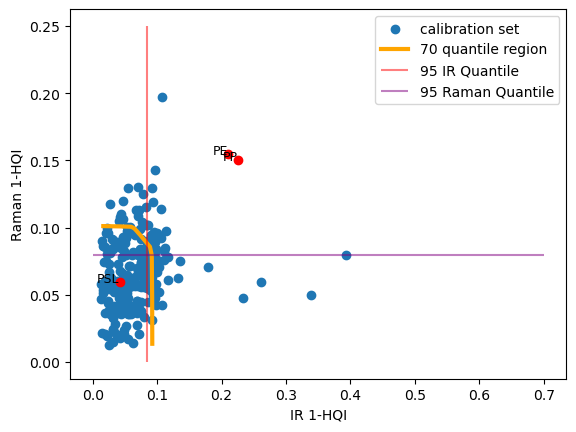

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


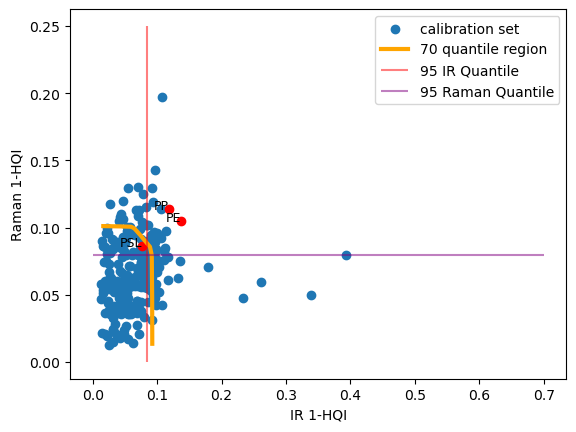

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


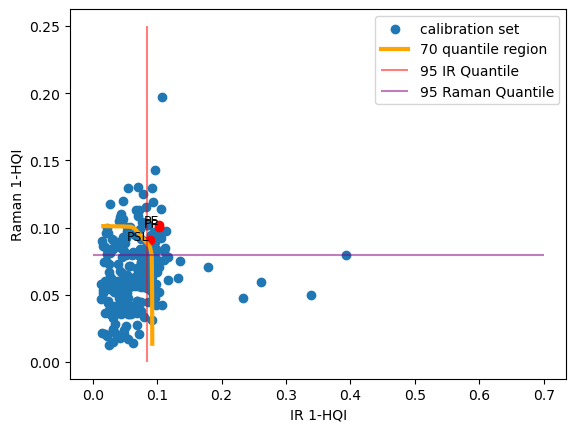

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


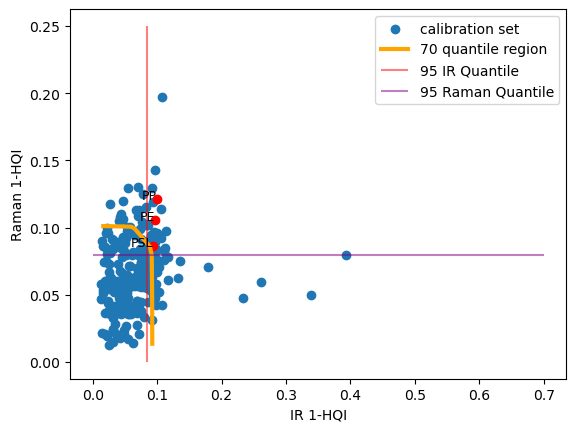

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


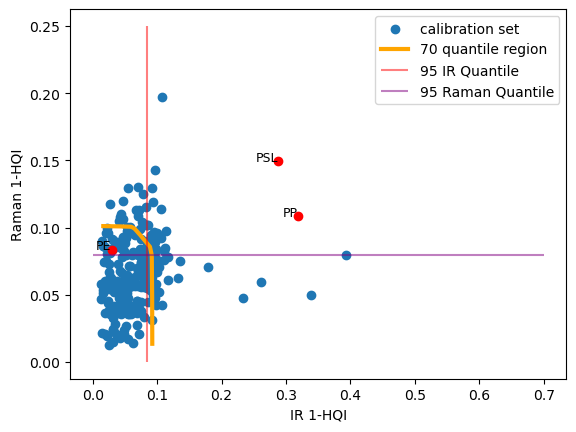

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


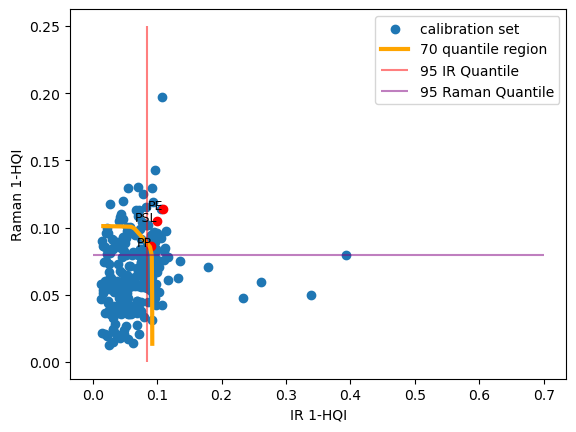

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


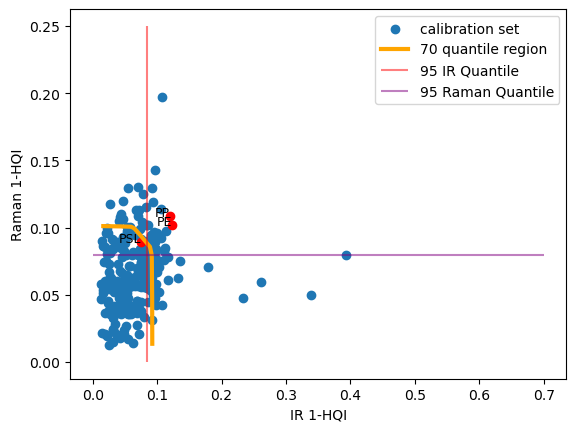

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman []


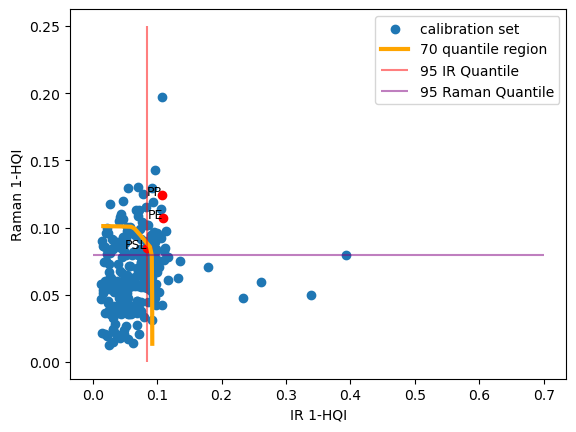

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


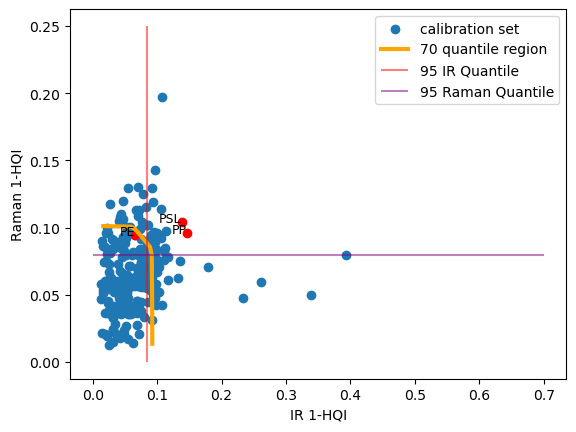

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


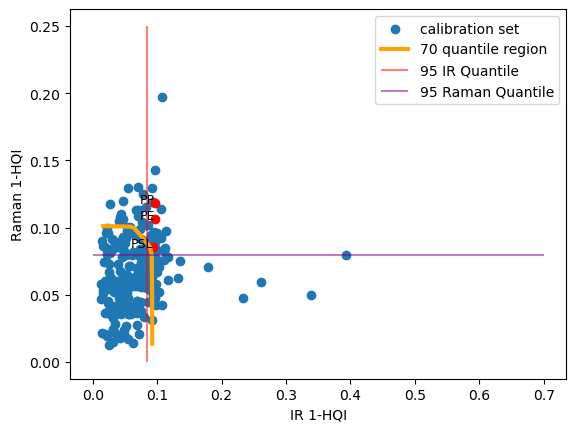

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


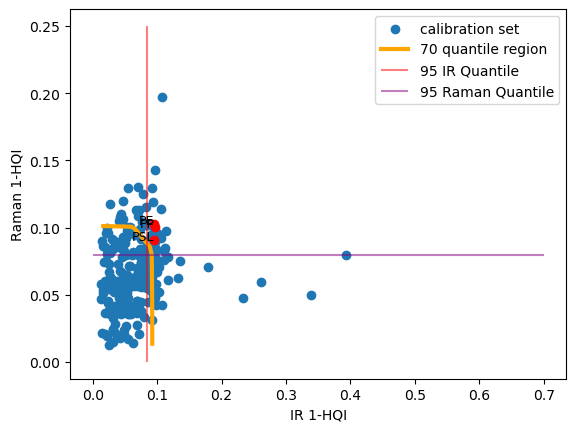

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


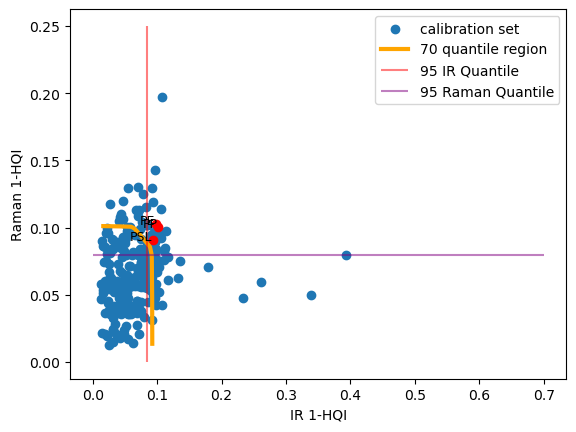

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


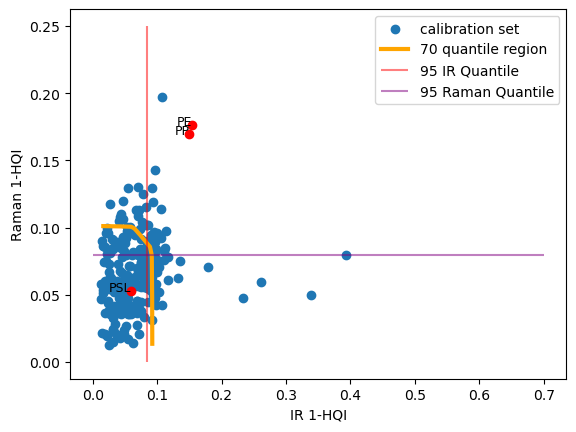

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


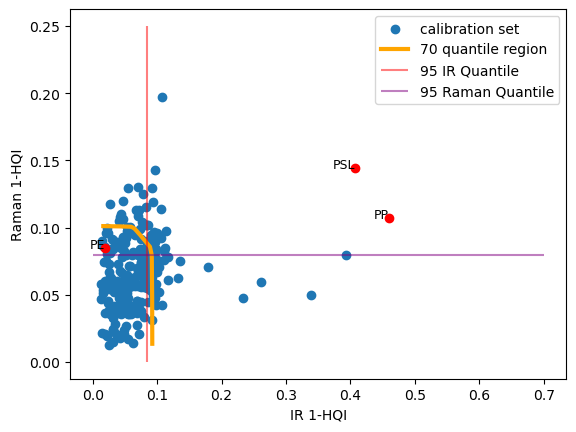

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


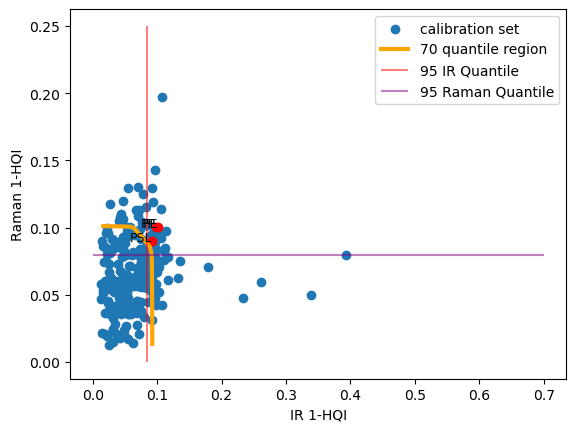

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman ['PSL']


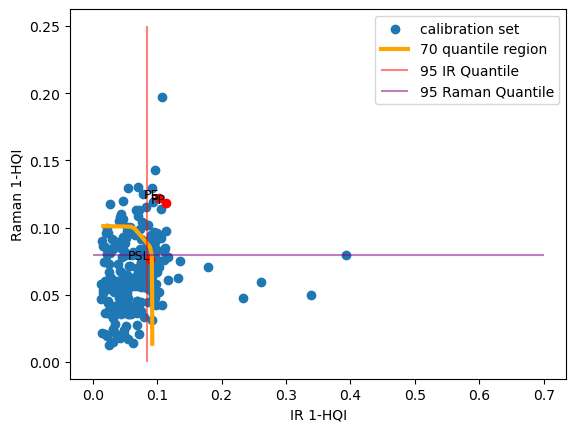

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


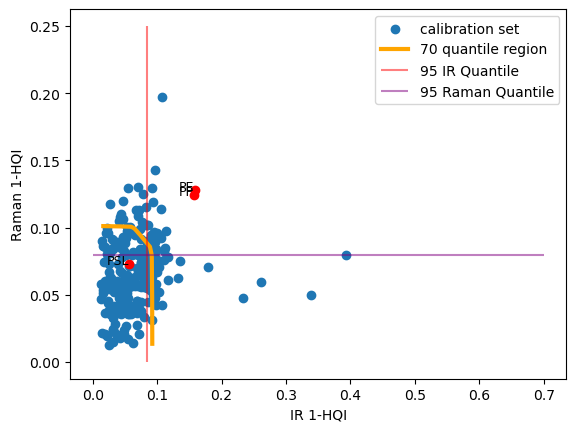

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


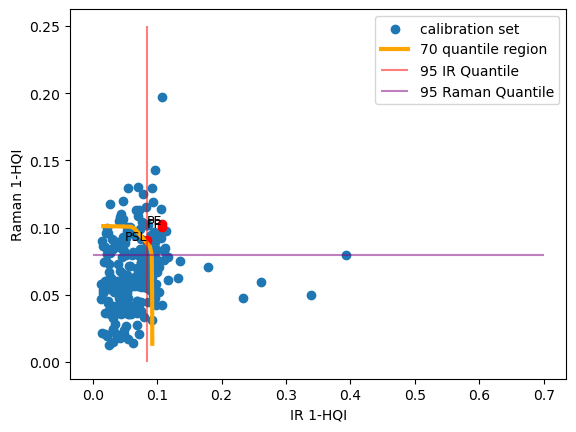

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


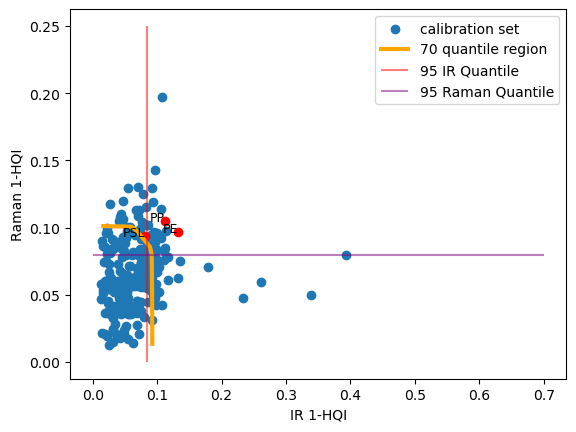

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


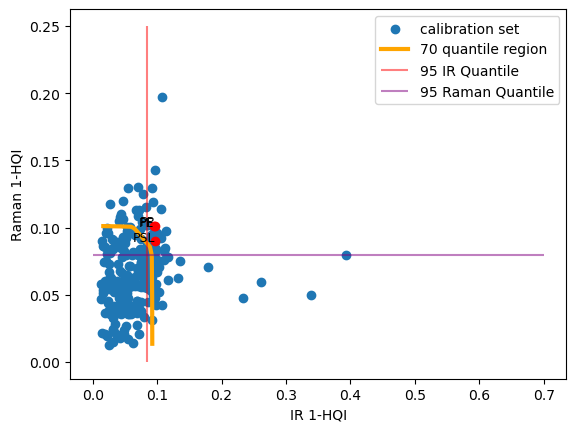

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


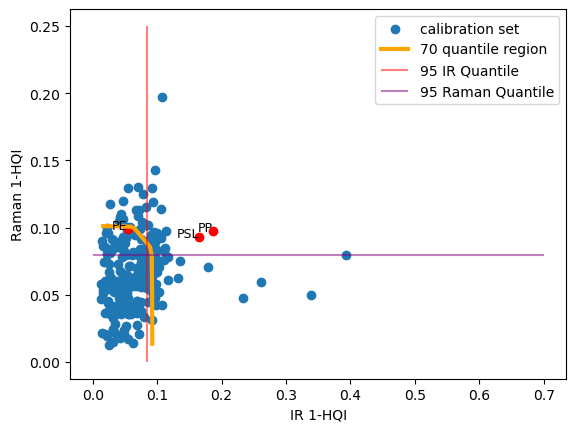

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


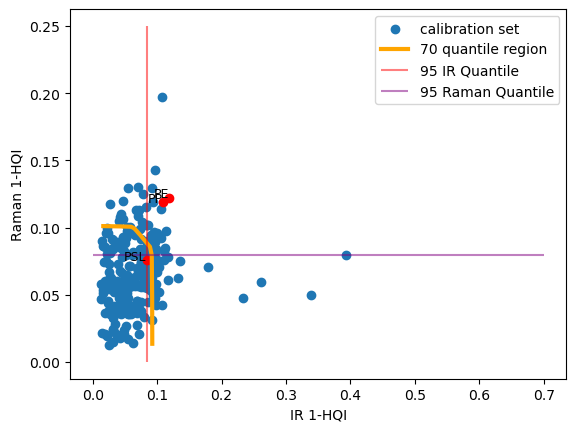

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


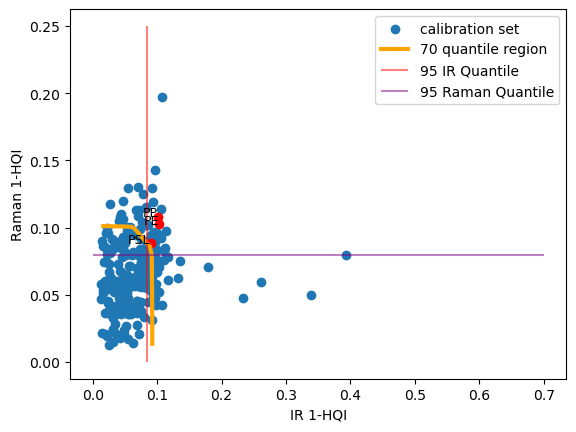

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman ['PE']


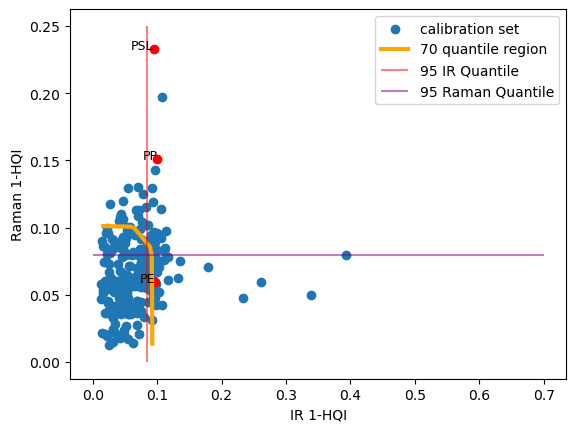

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


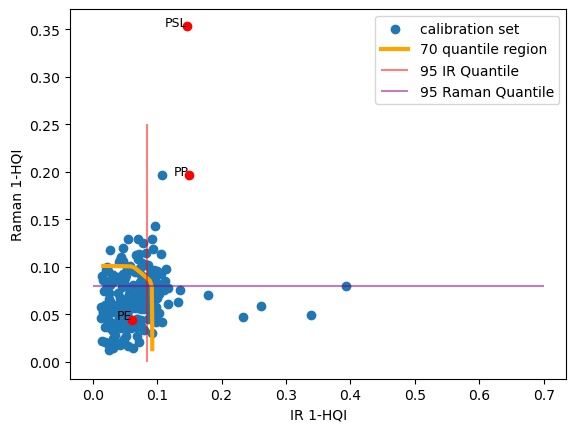

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


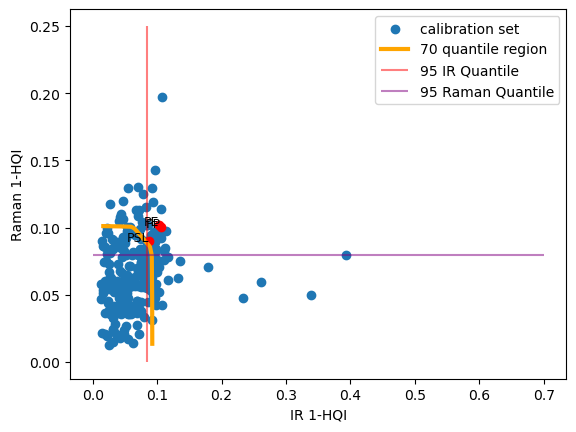

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


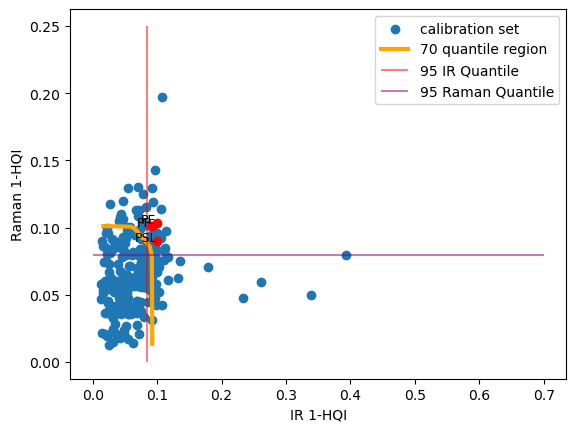

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman []


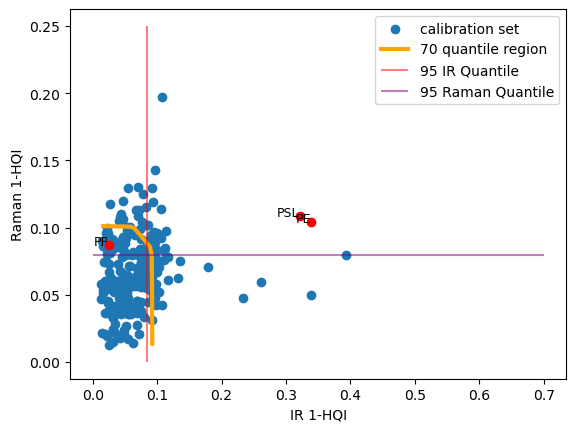

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman ['PP']


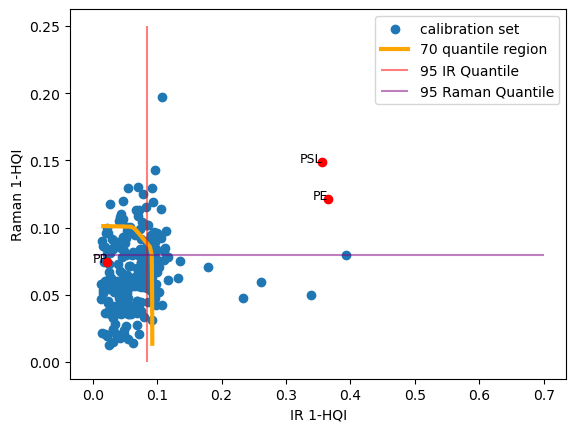

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


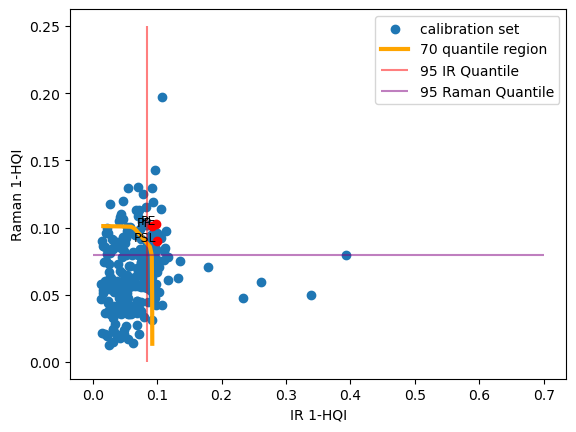

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


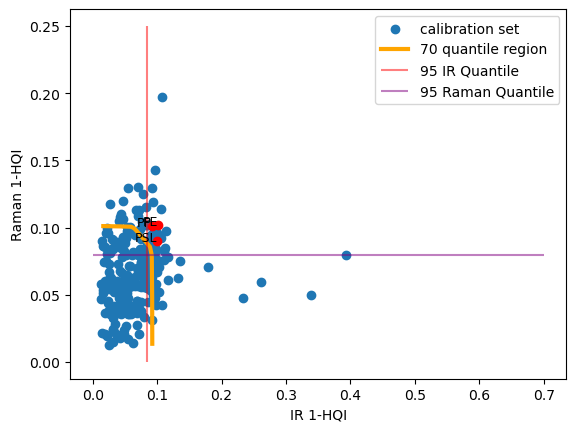

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


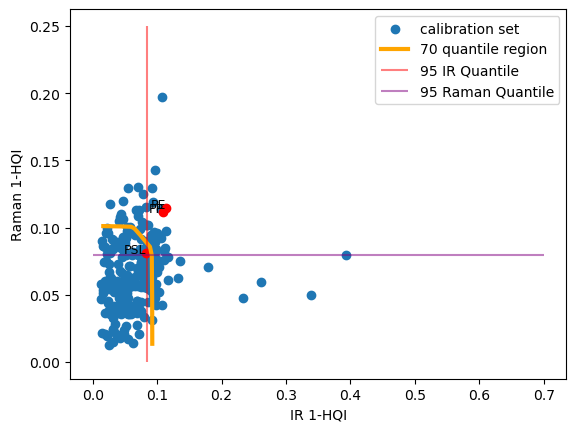

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


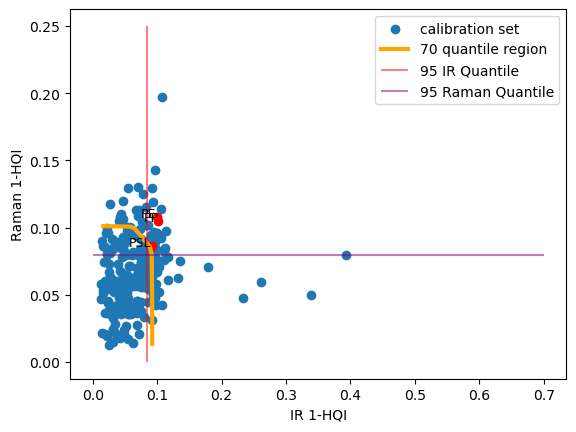

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


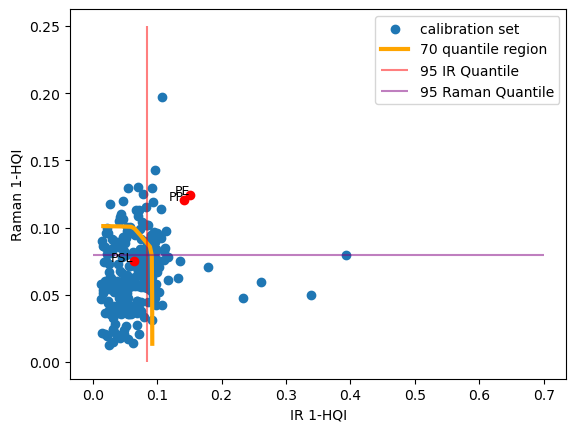

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


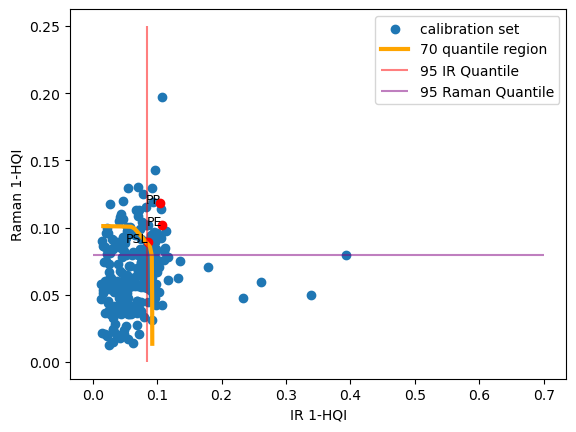

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


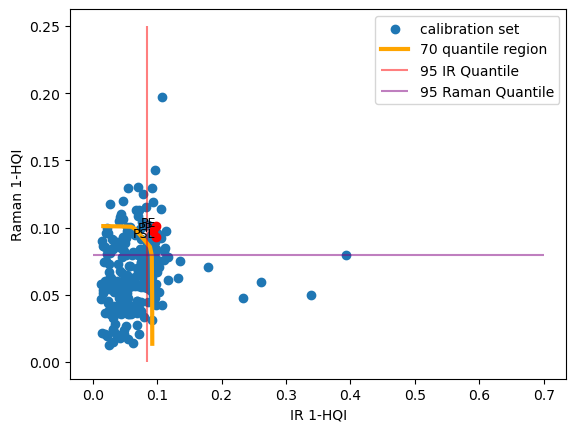

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


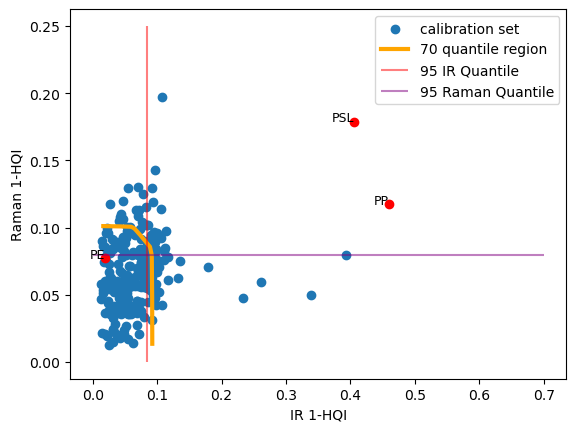

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


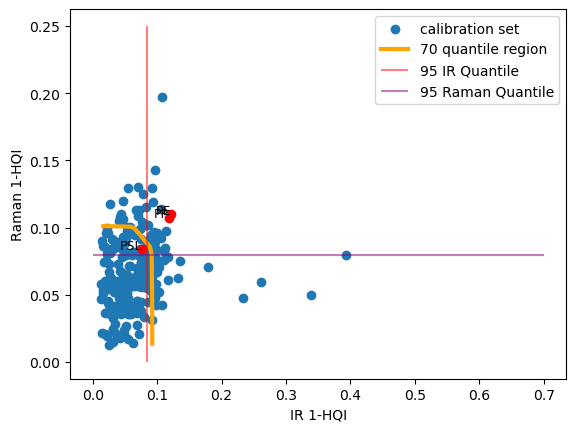

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


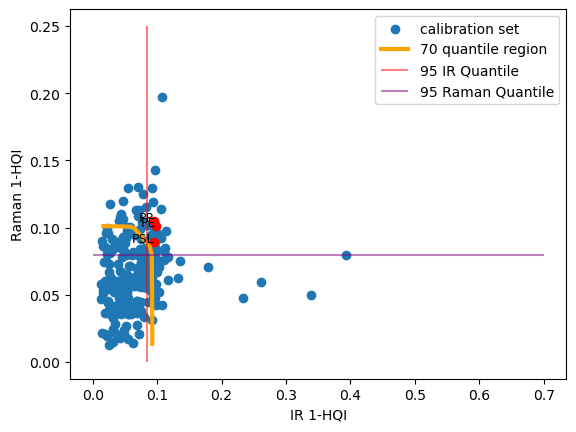

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


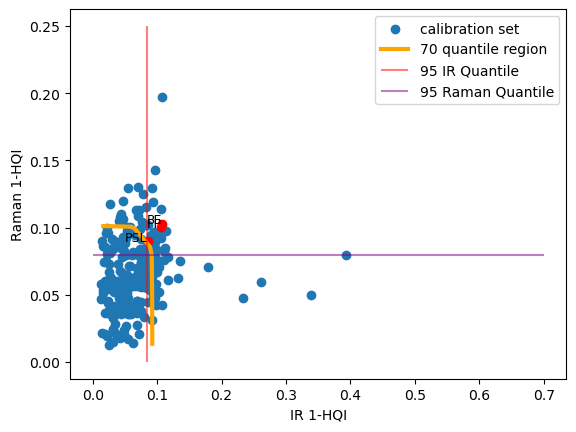

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


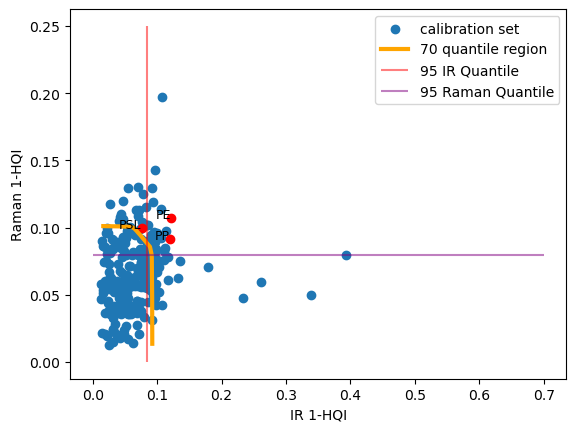

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


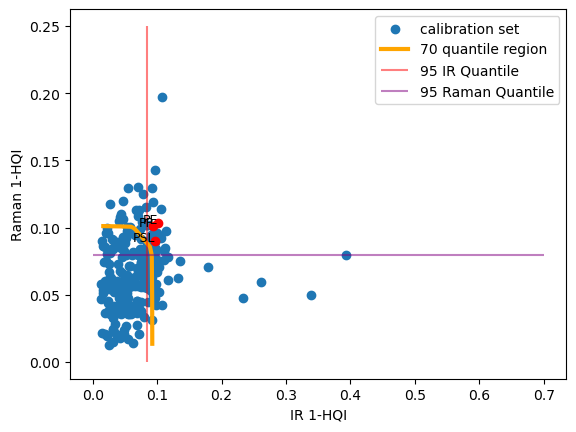

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


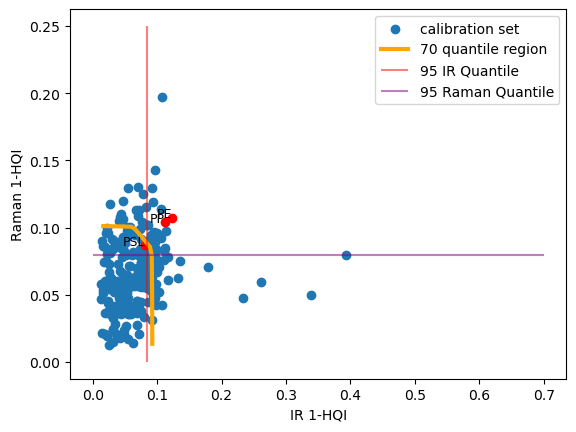

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


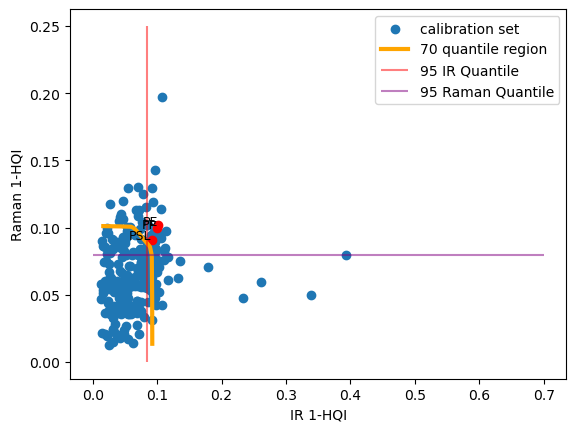

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


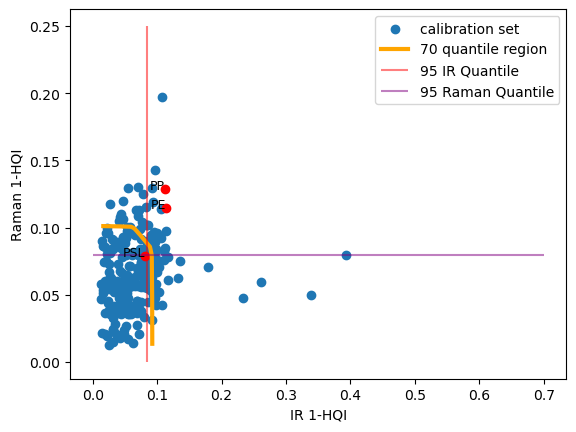

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


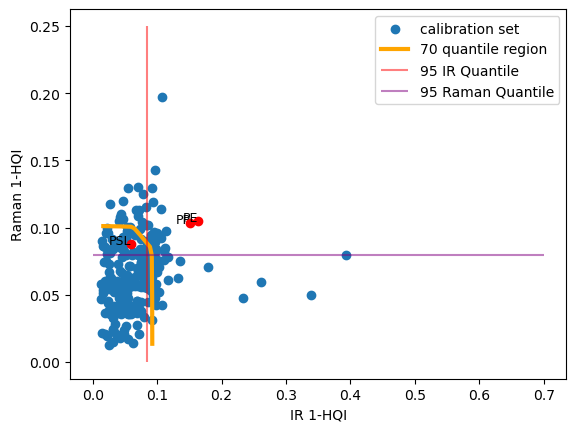

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


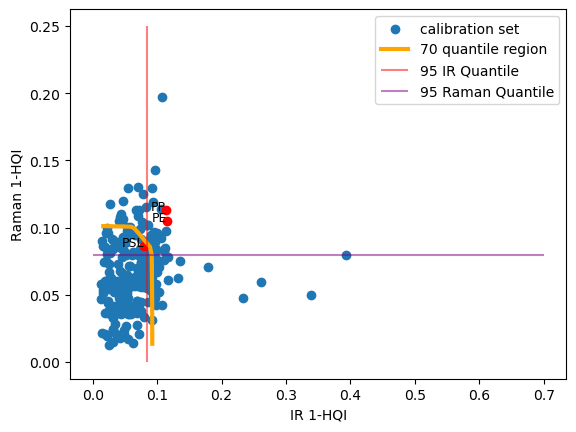

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


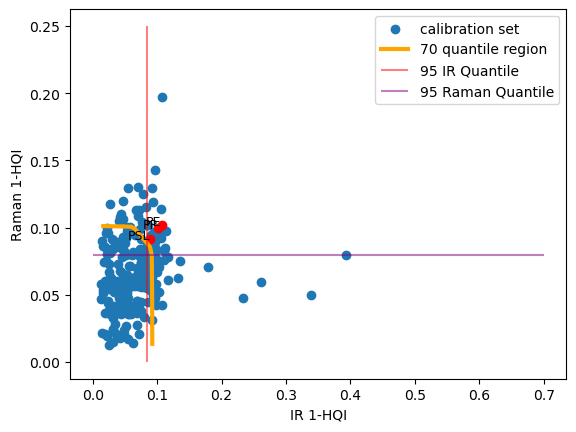

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman ['PP']


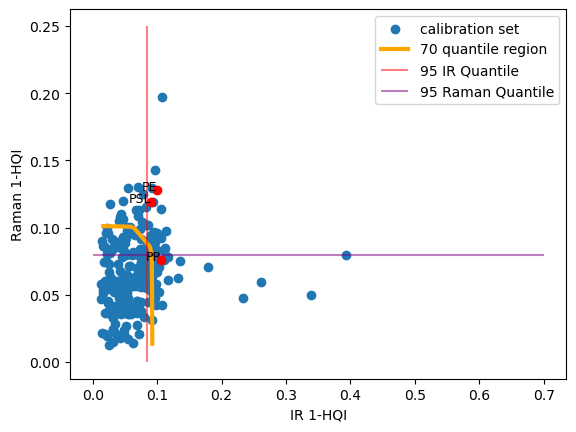

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


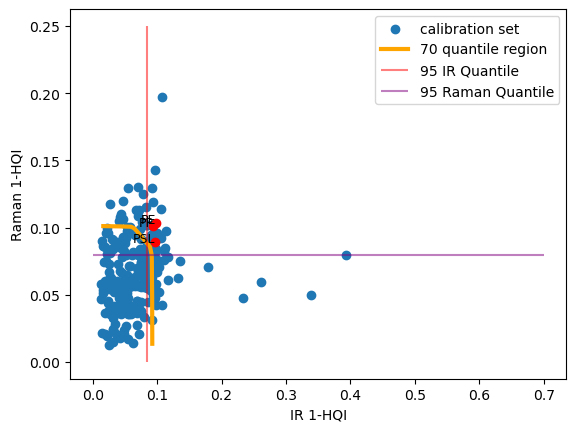

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


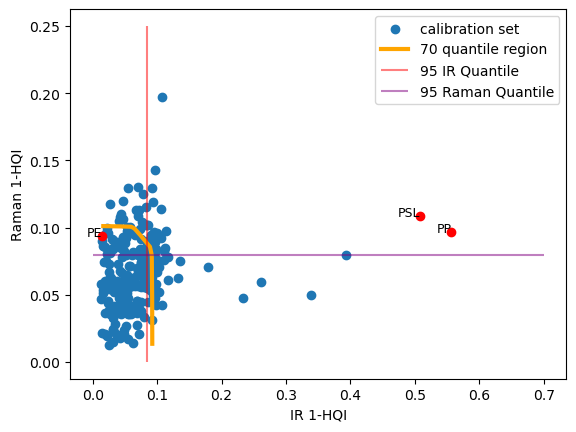

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


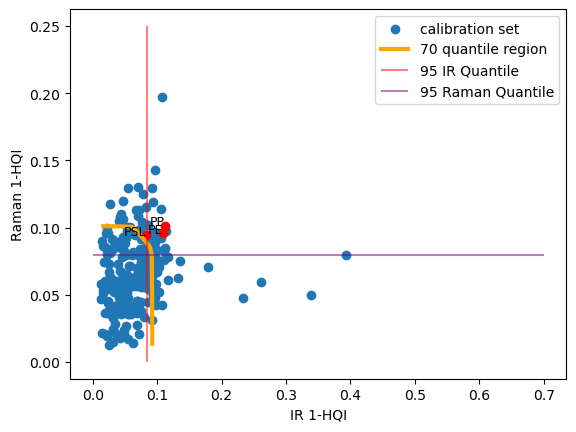

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


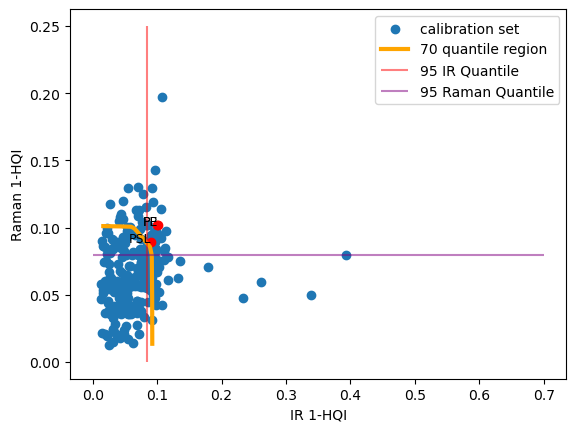

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


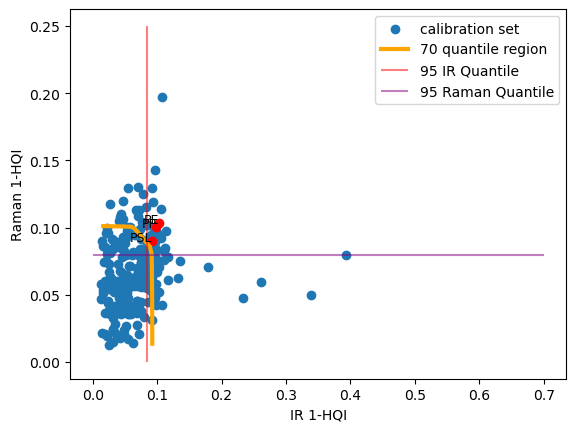

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


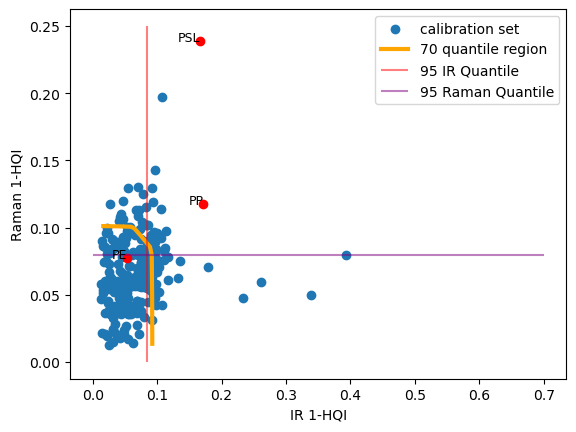

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


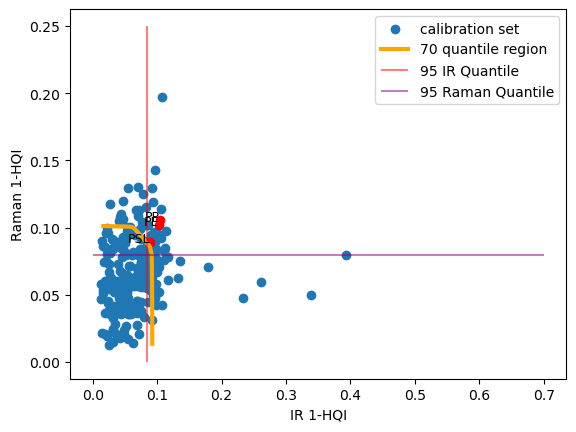

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


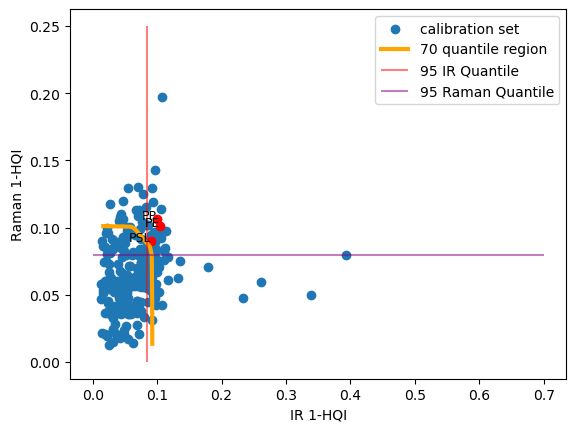

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


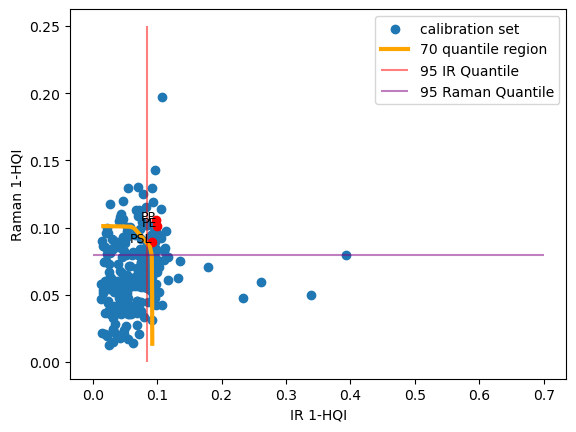

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


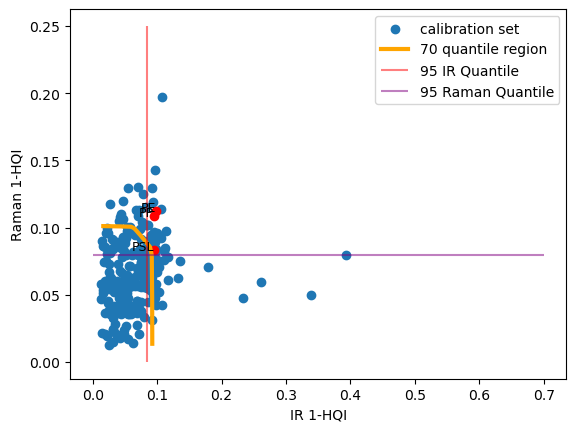

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


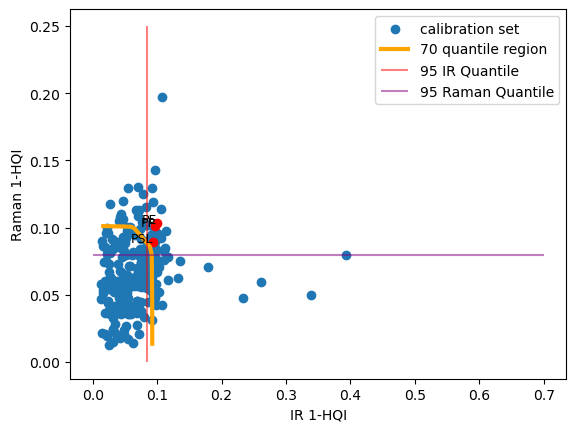

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


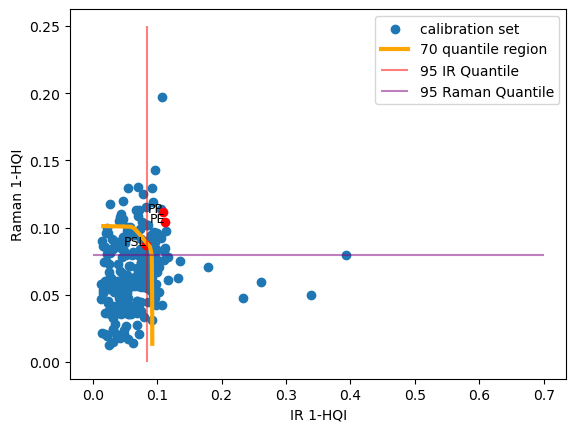

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


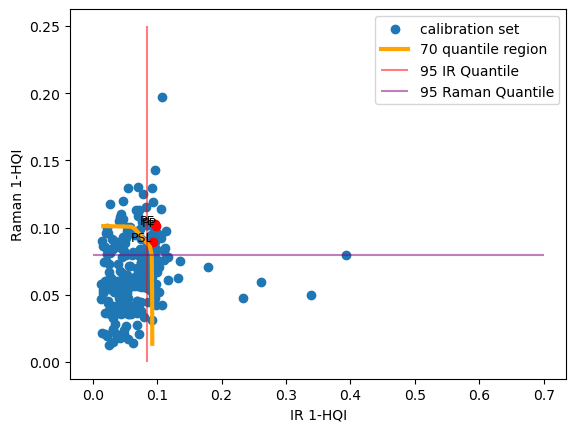

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


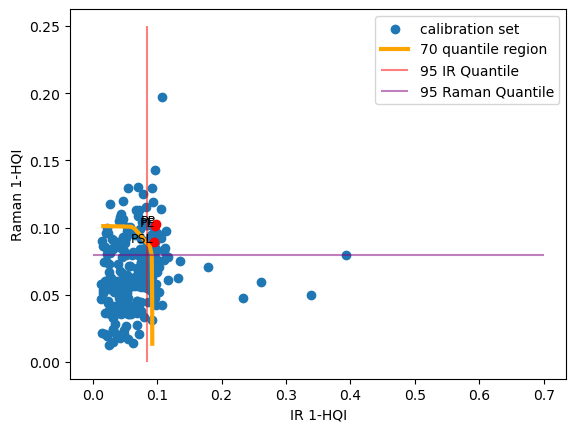

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


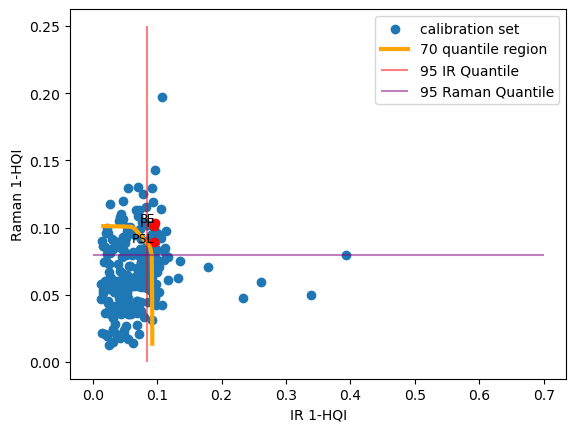

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman []


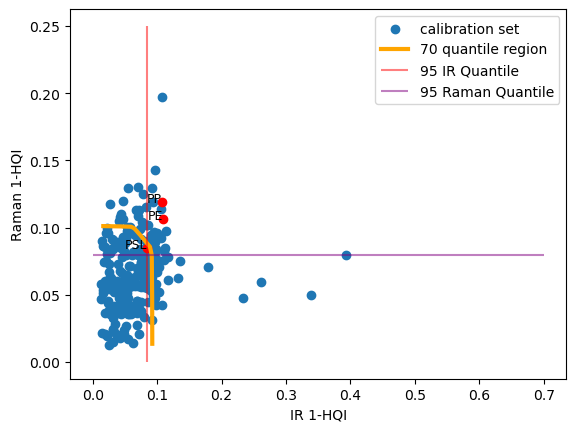

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PP']
Raman []


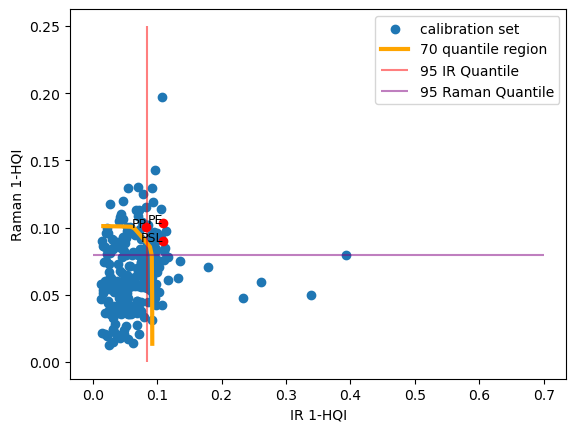

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PP']
Raman []


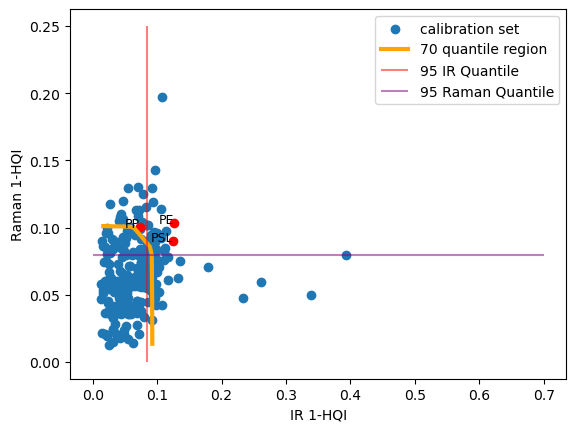

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


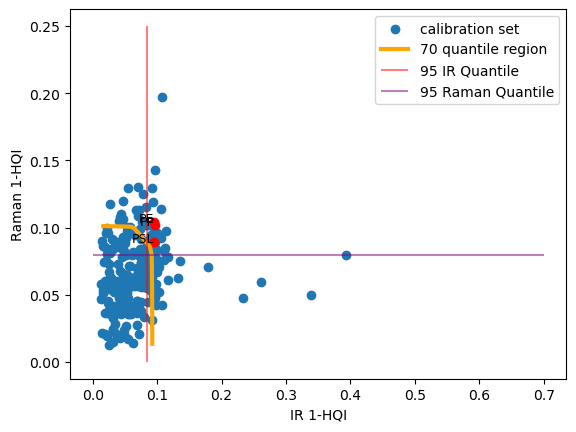

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


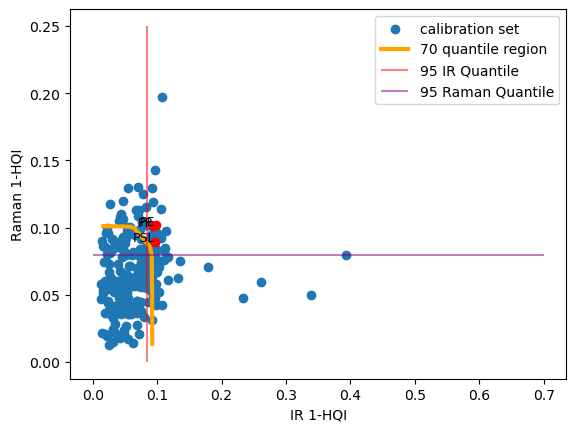

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


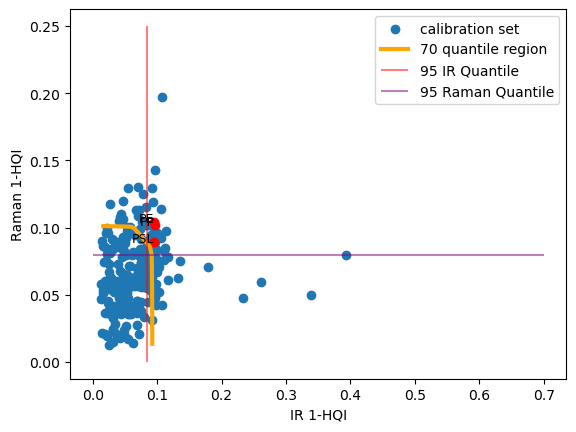

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


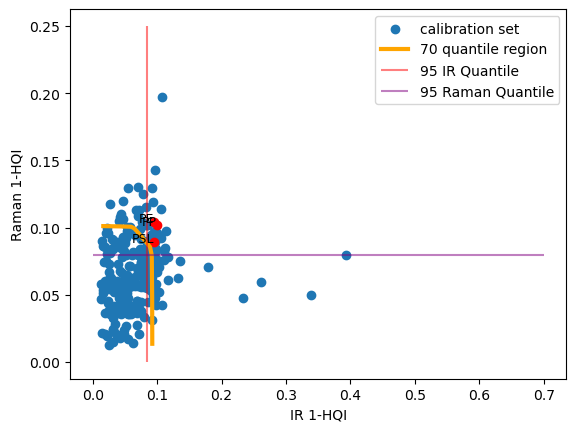

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


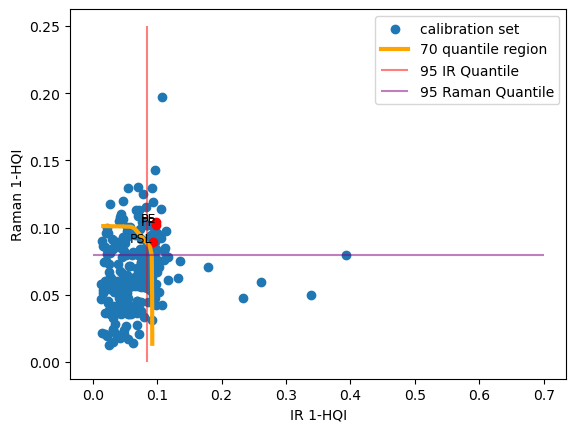

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


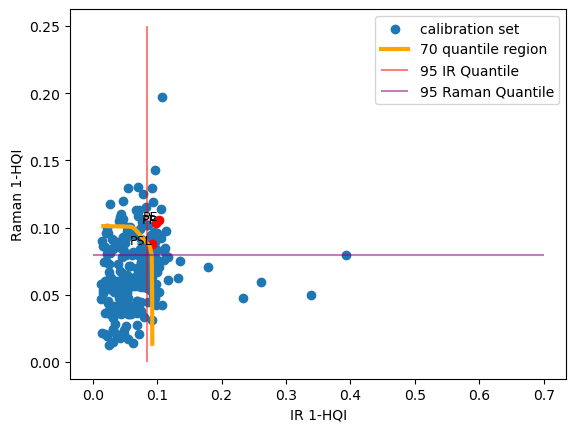

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


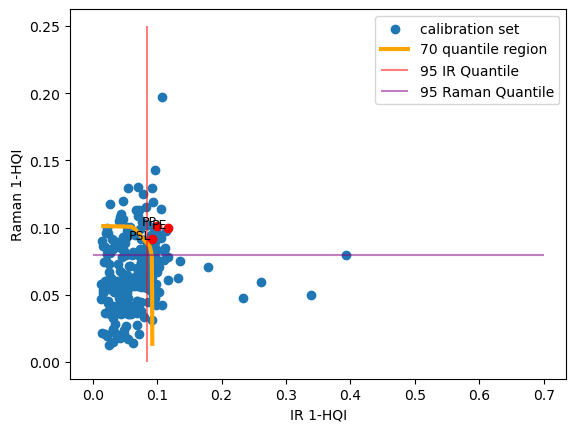

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


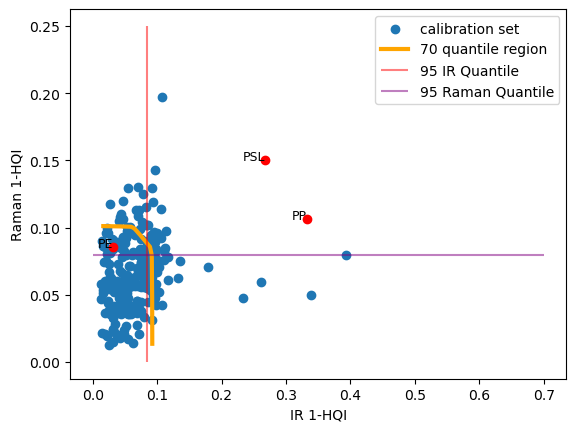

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


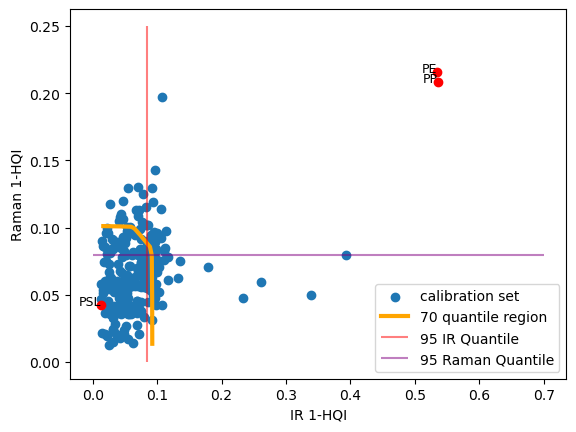

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


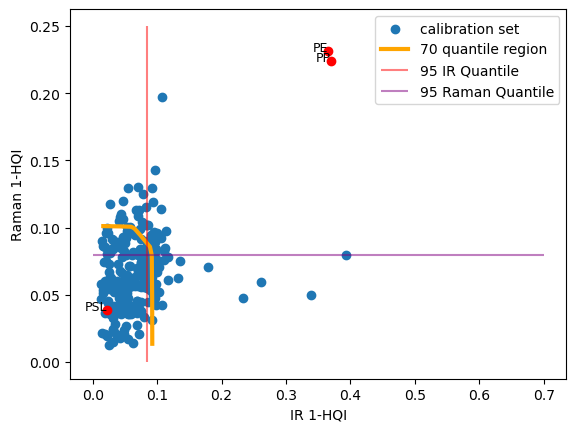

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


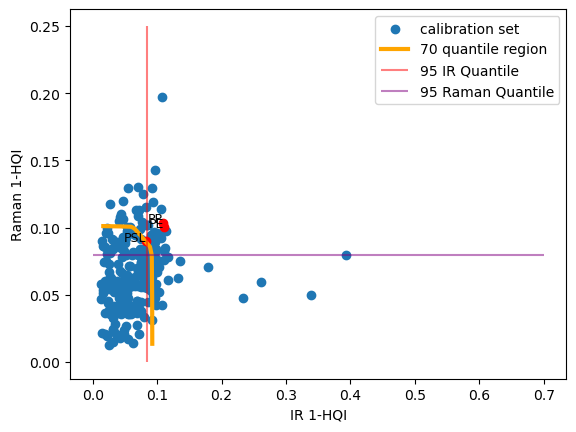

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


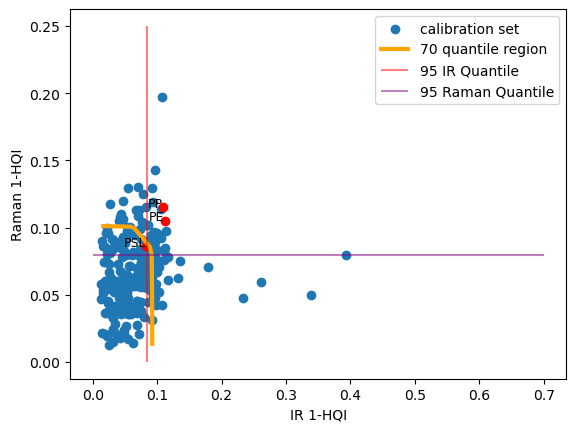

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


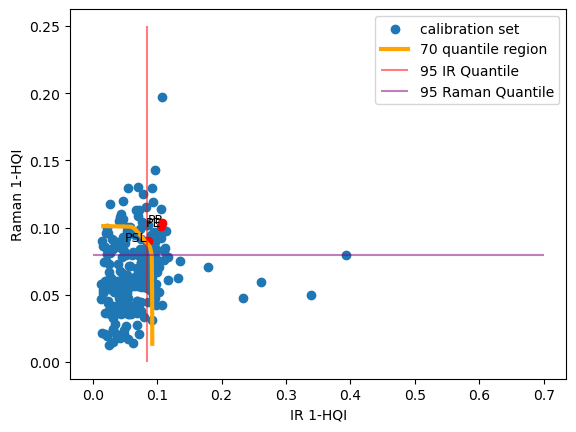

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


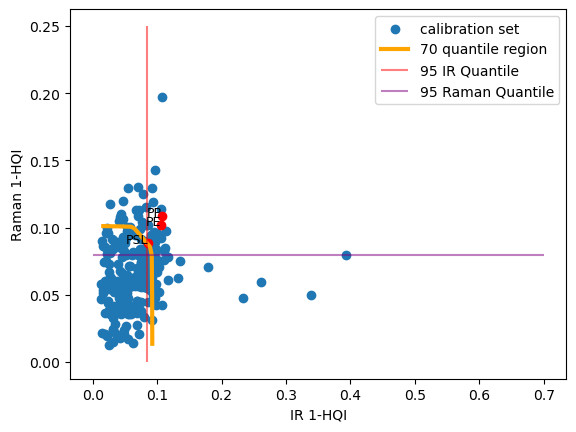

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


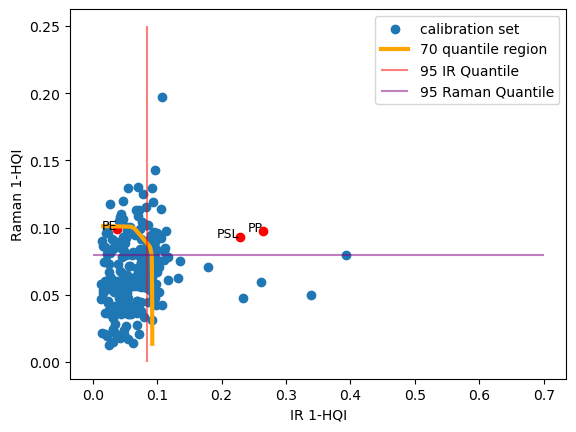

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


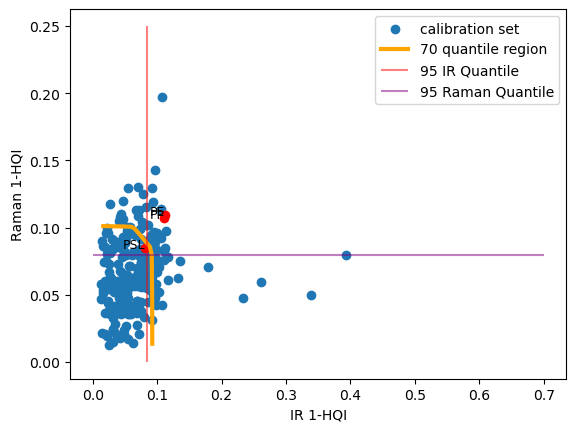

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


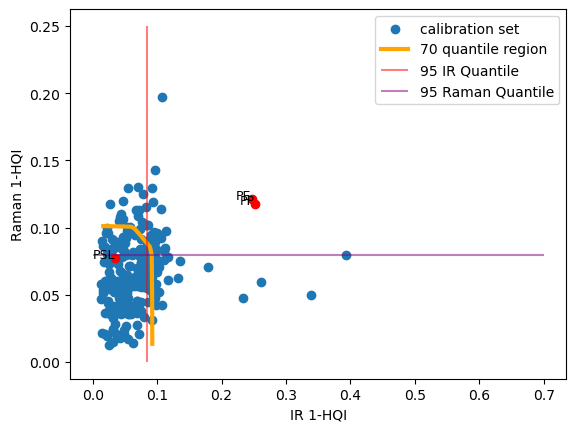

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


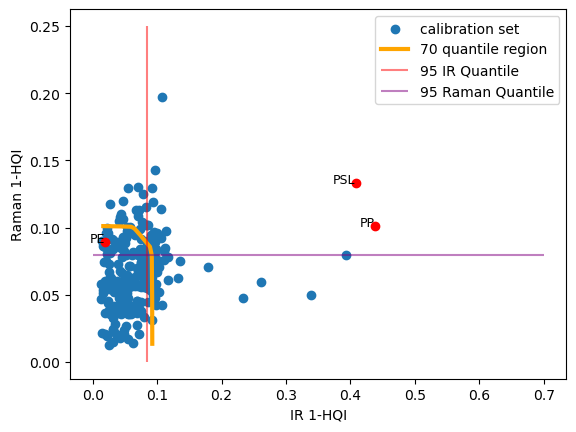

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


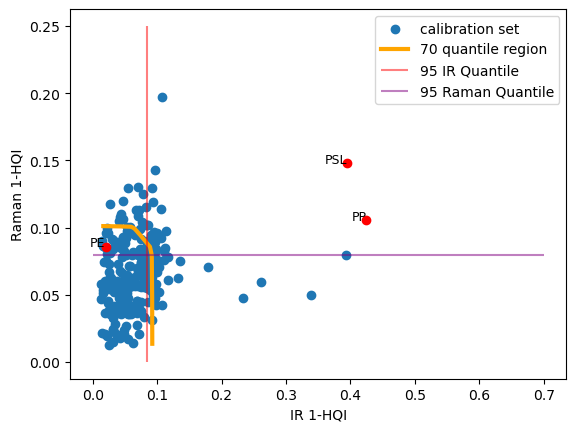

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


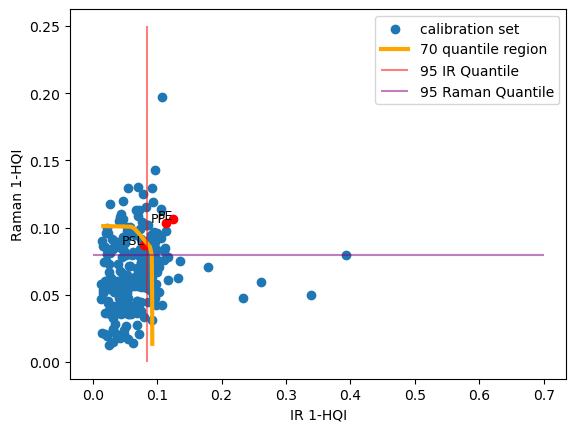

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


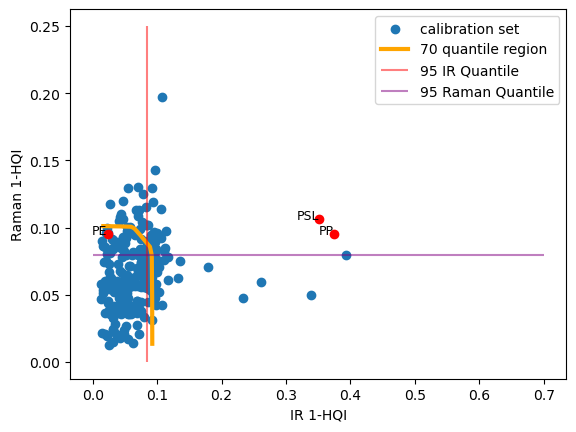

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


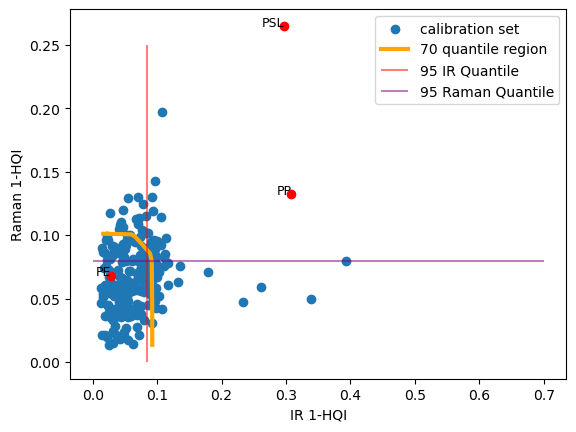

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


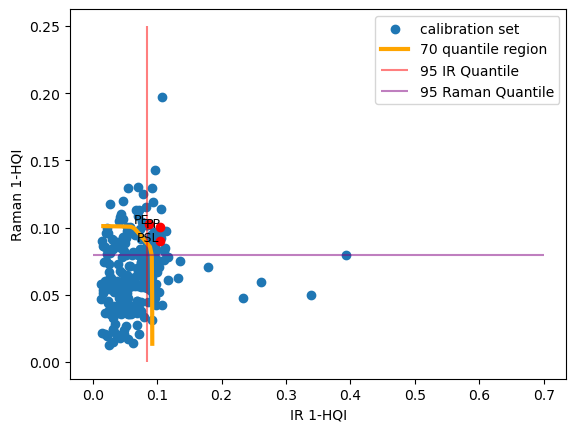

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


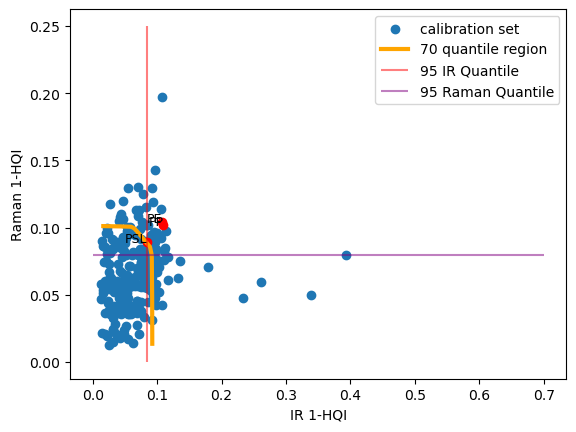

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


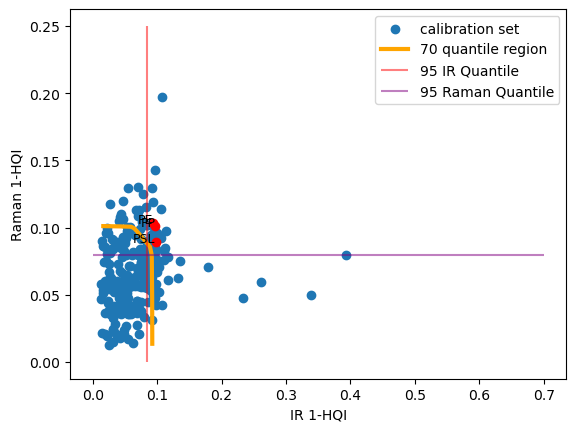

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


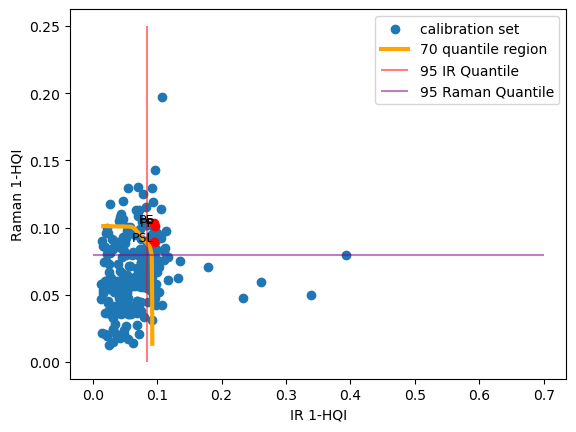

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


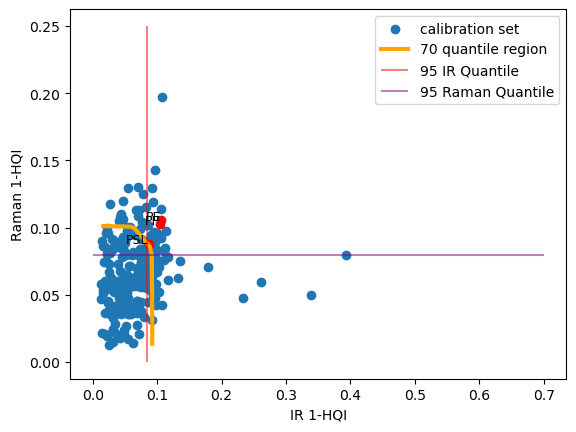

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


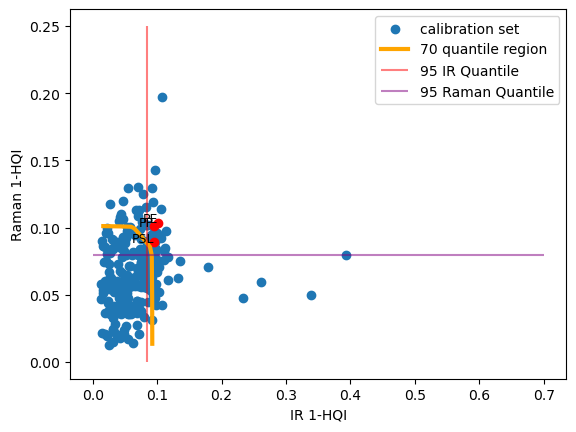

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


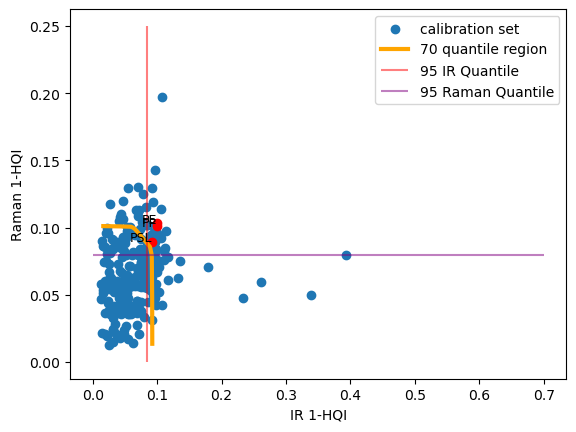

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


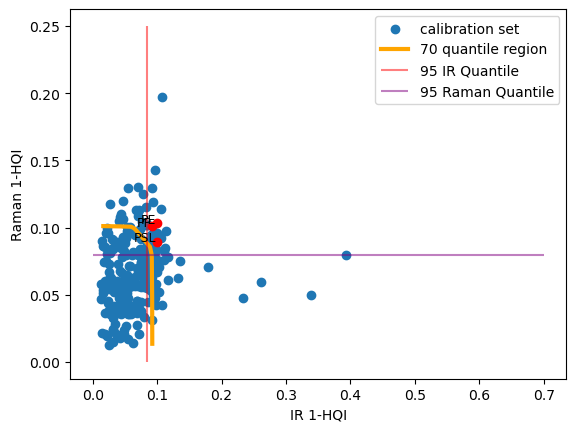

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


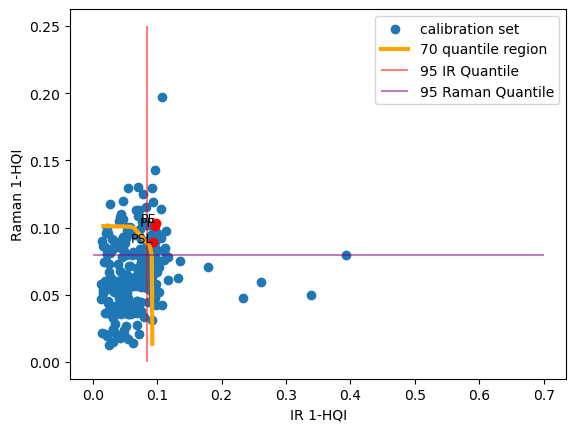

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman []


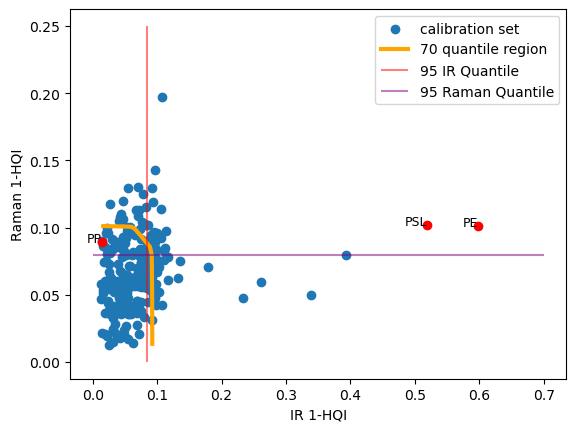

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


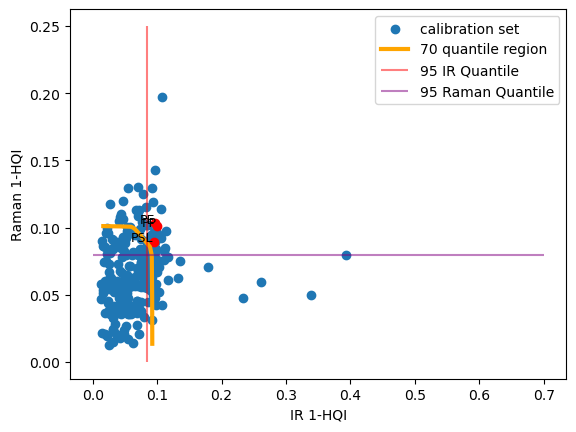

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


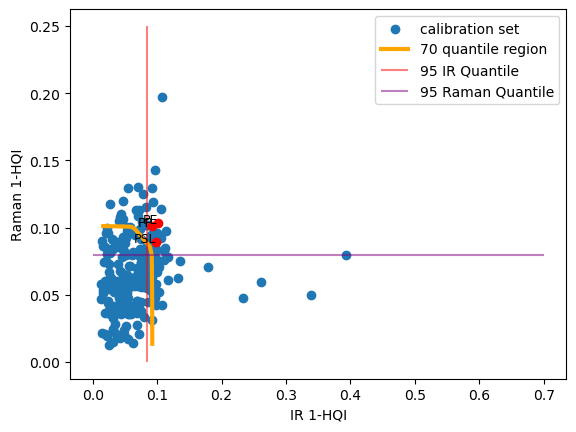

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


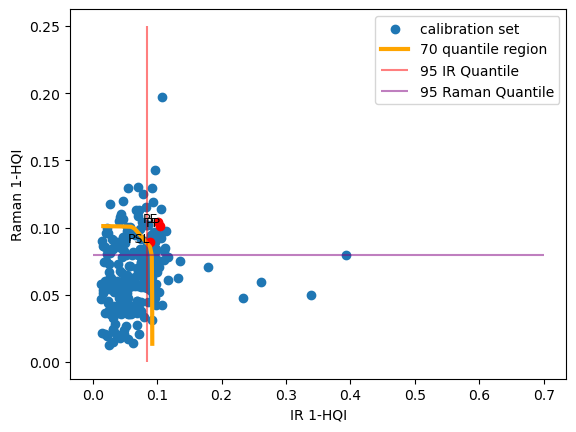

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


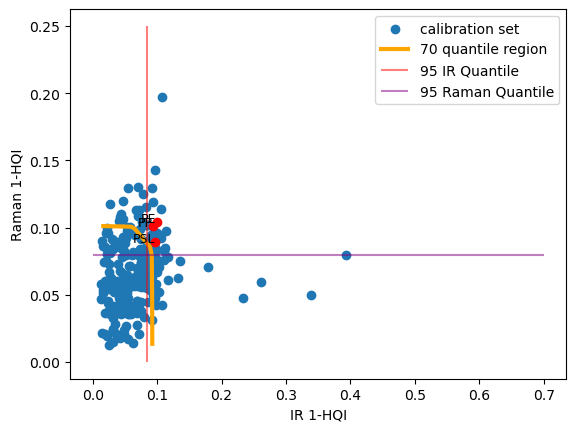

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


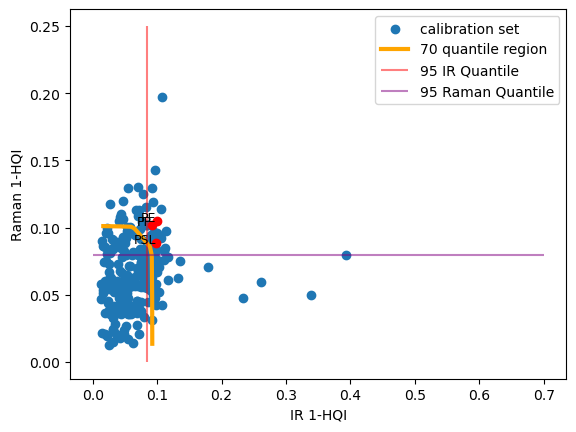

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


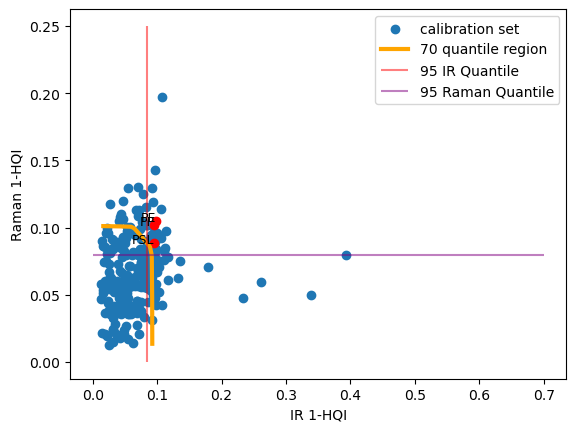

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


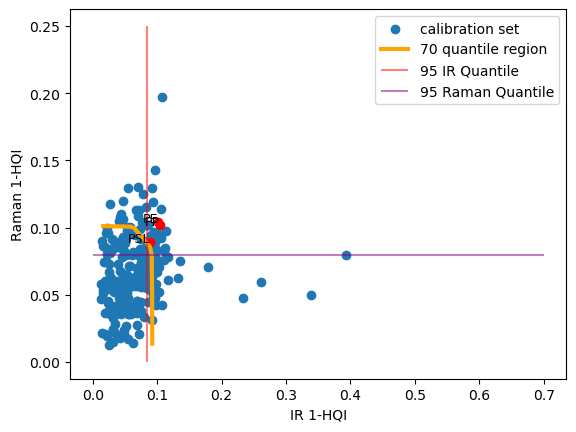

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


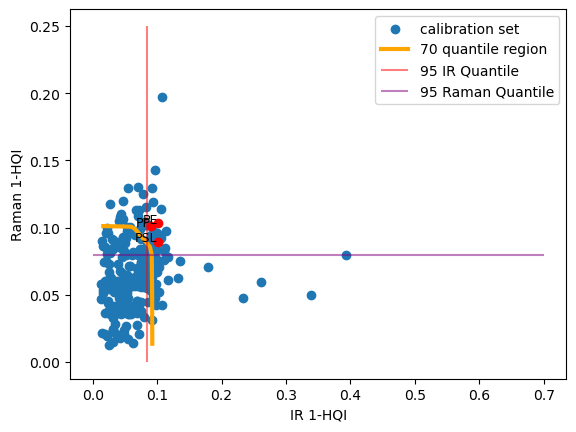

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


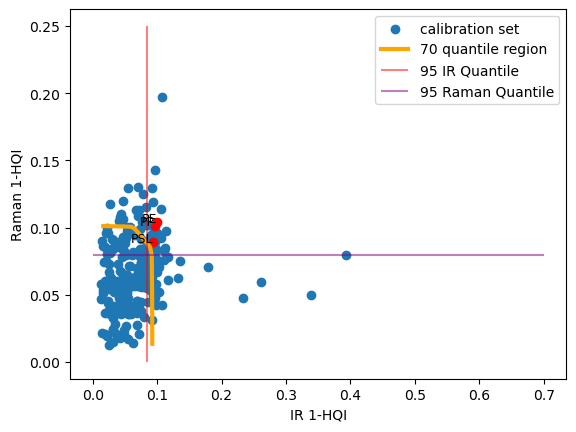

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


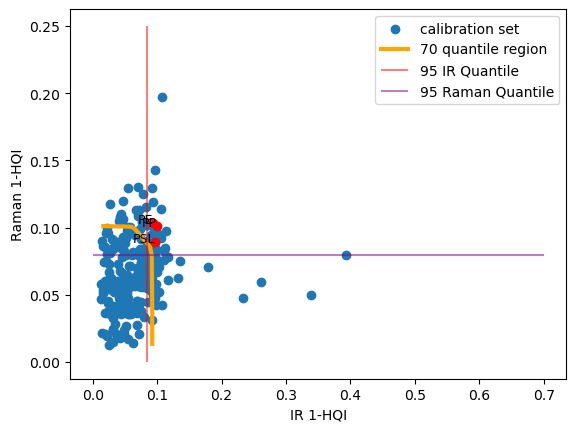

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


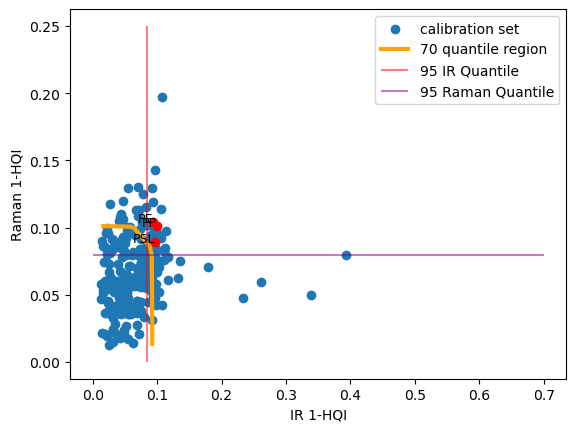

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


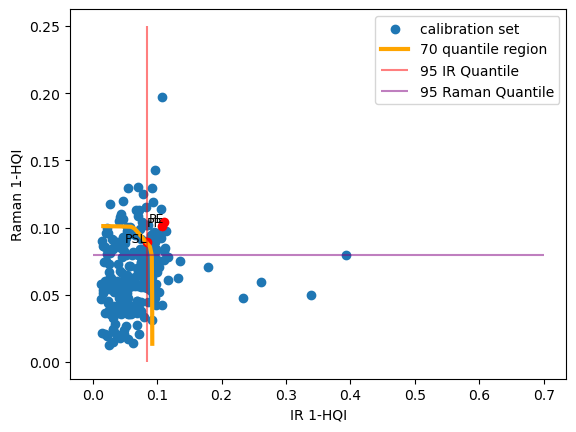

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


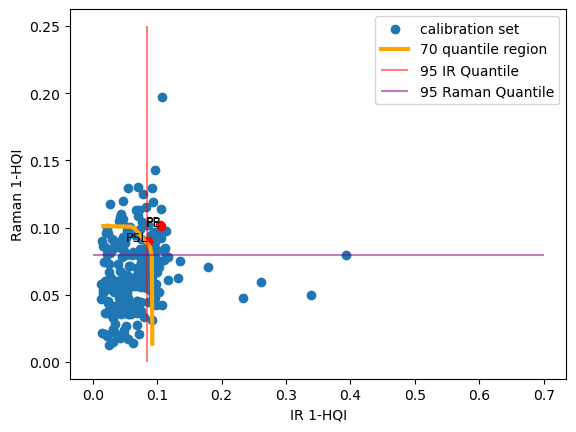

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE']
Raman []


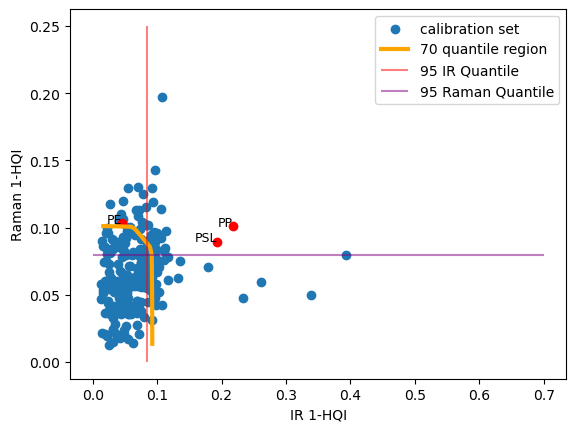

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


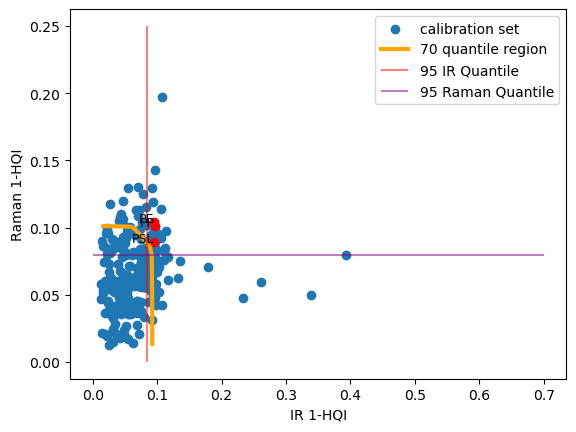

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


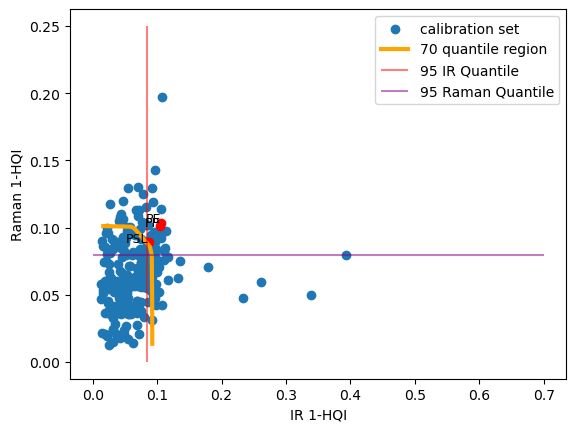

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


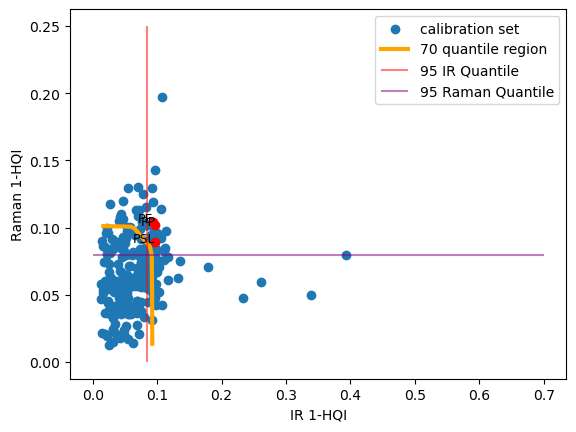

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


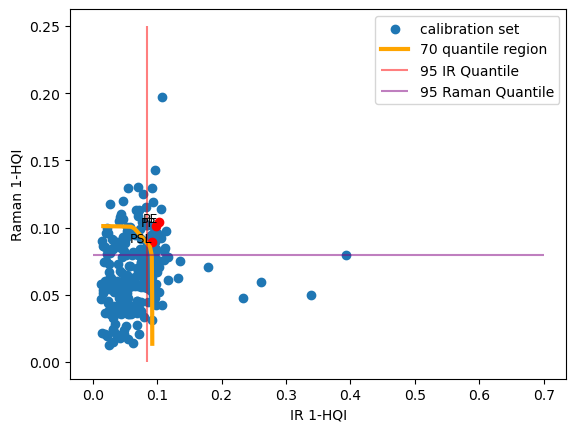

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


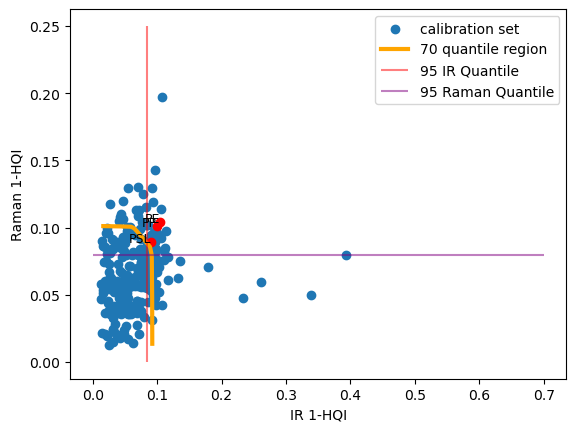

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


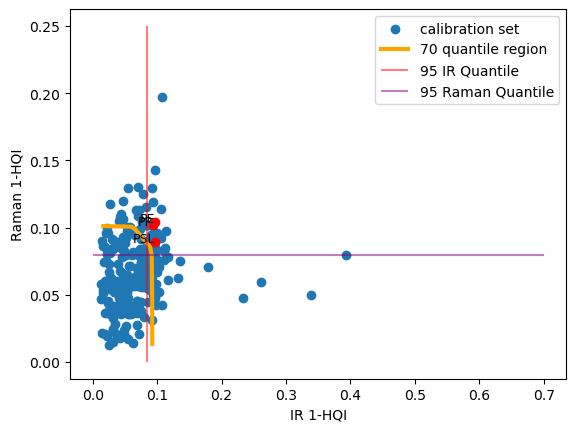

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


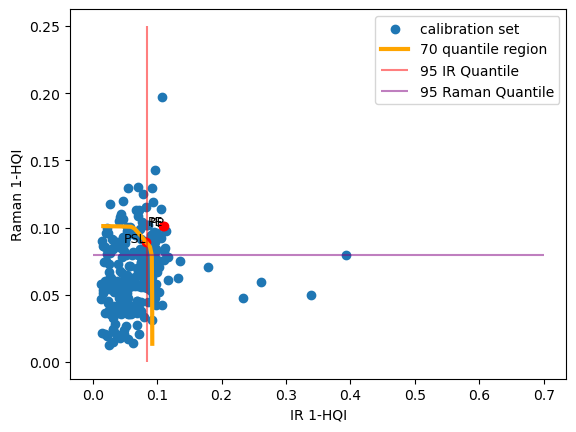

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


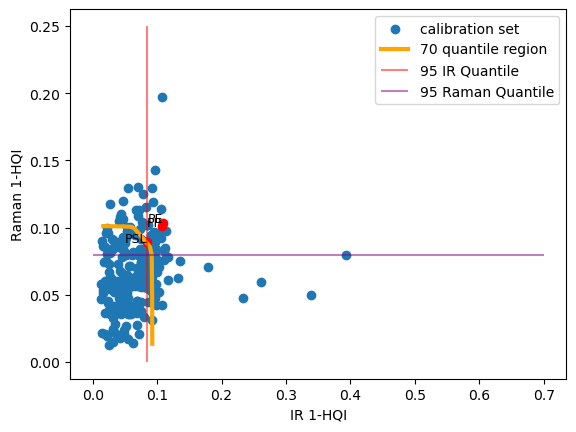

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


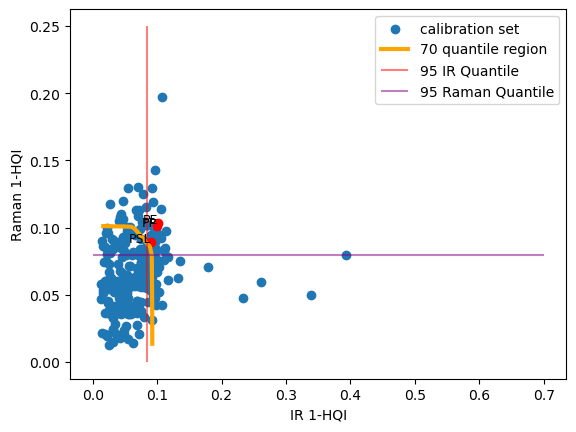

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


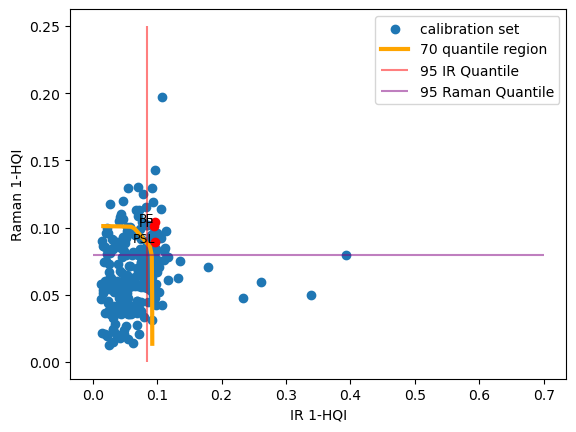

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


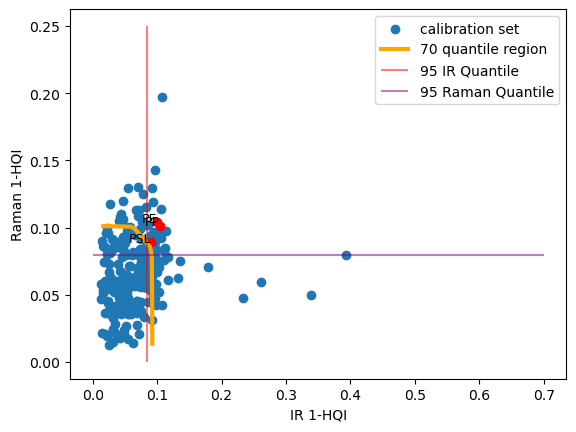

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


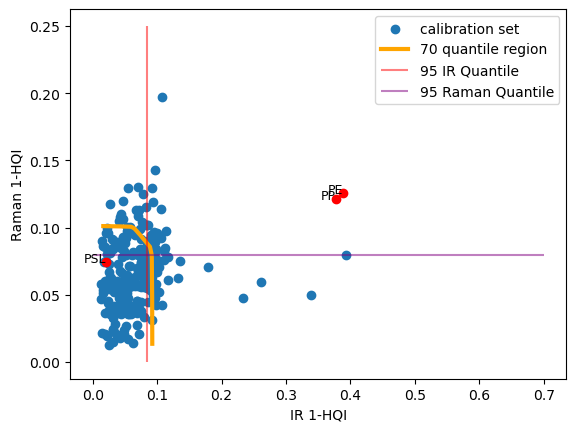

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


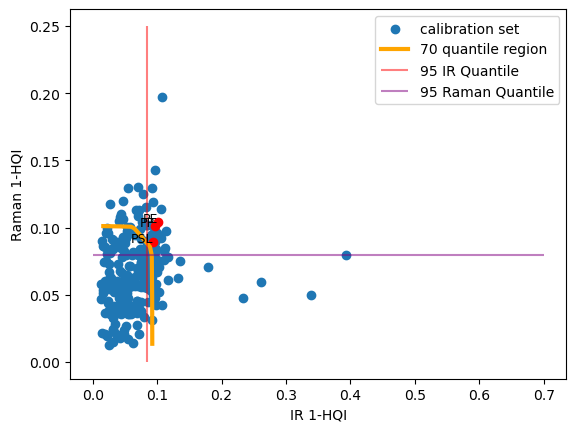

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


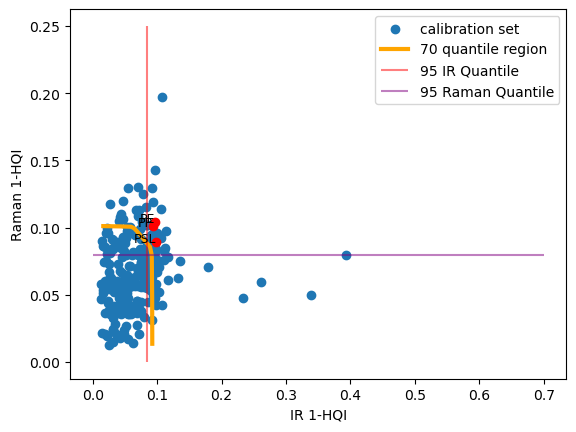

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


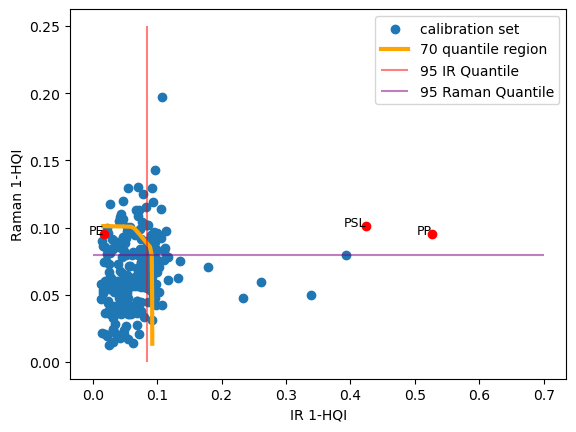

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


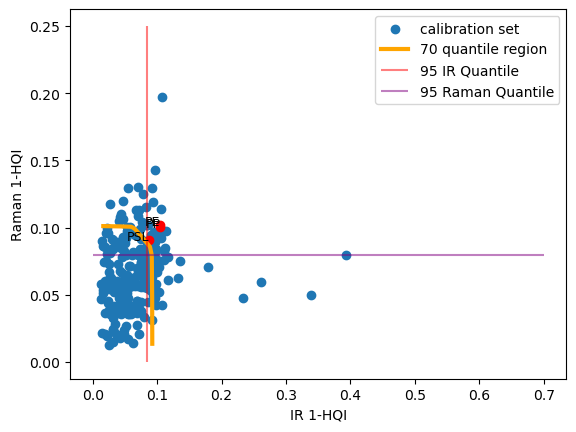

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


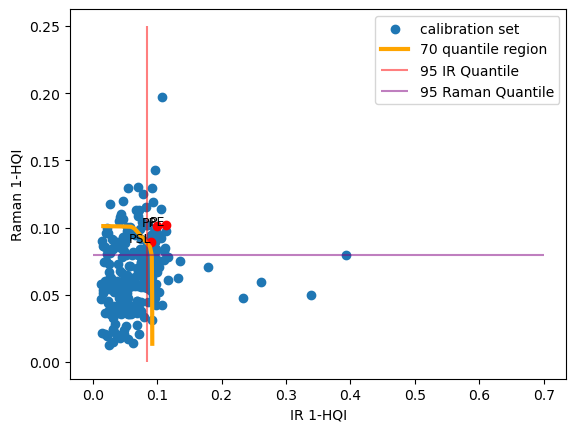

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


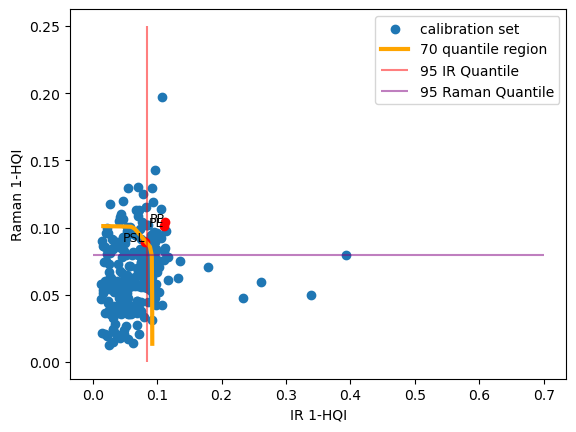

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


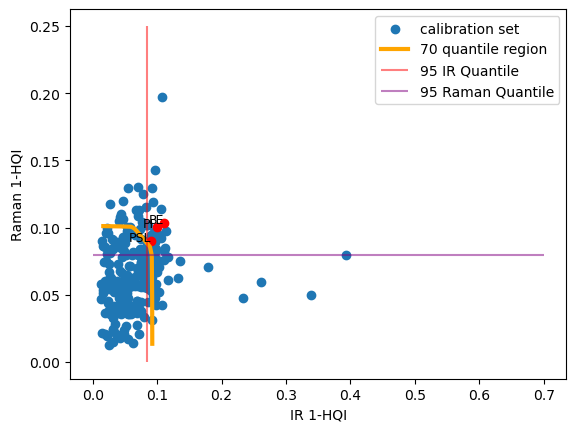

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


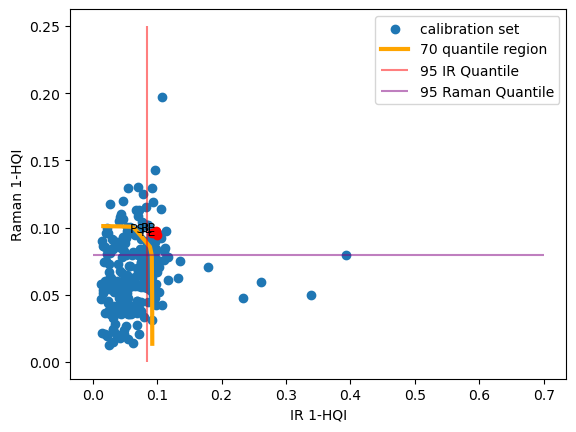

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


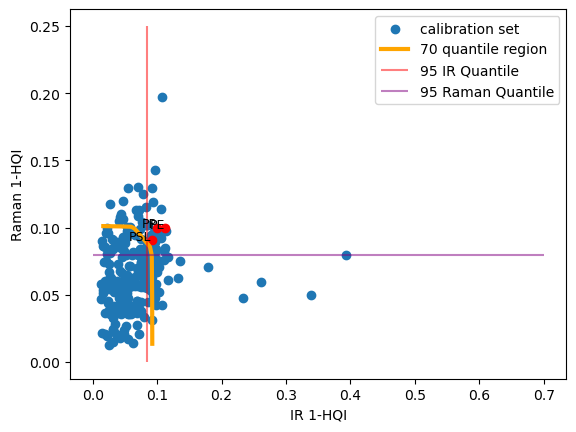

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


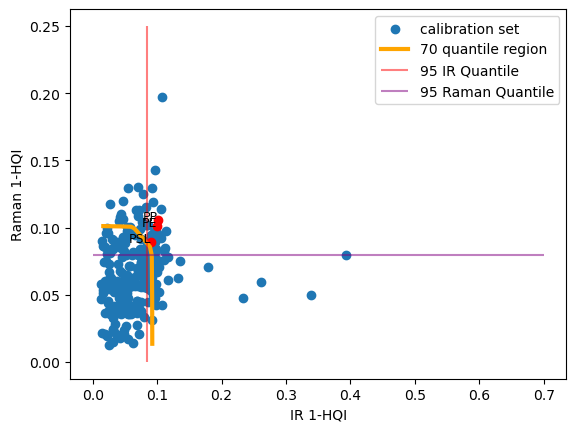

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


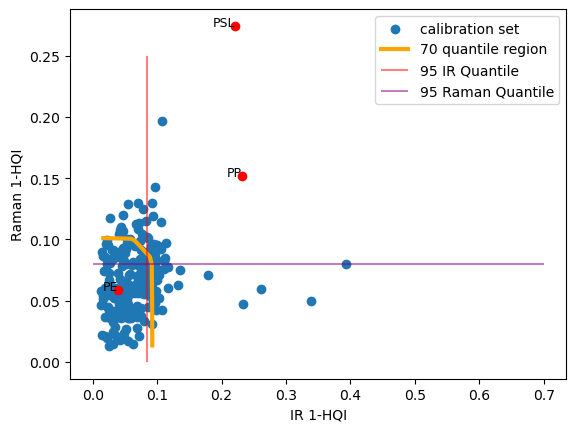

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


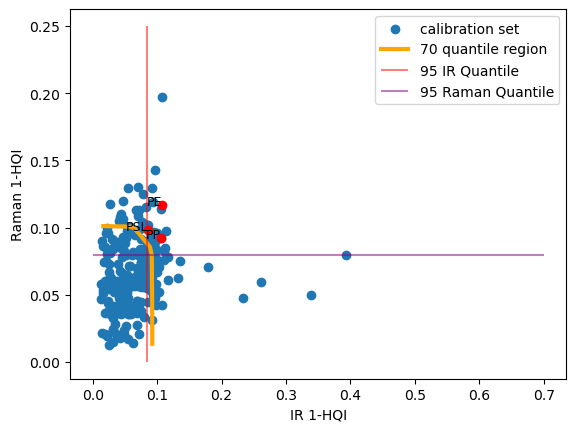

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


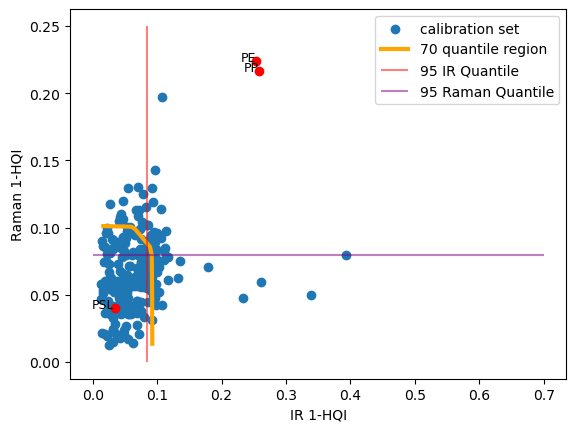

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


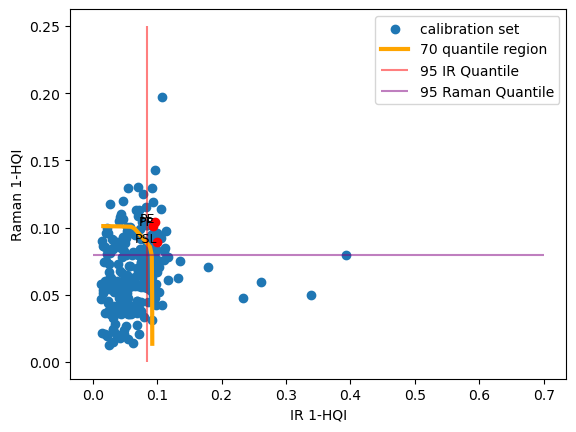

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


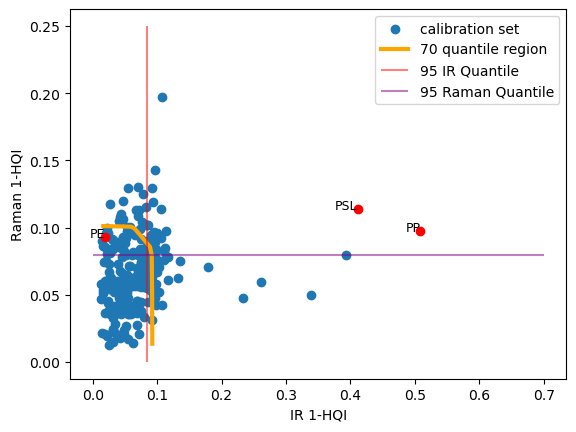

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman ['PP']


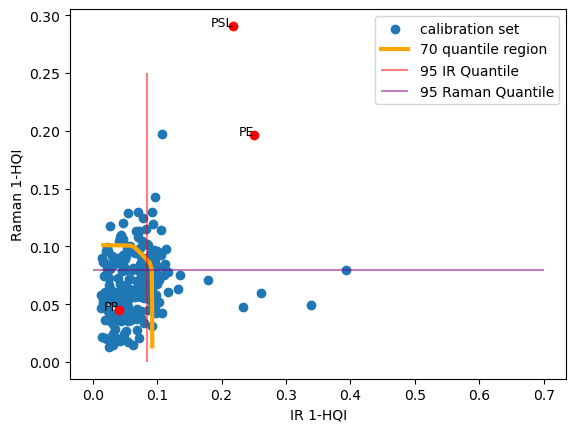

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


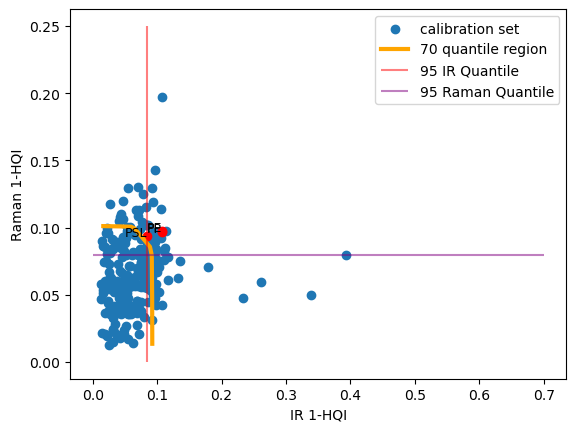

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


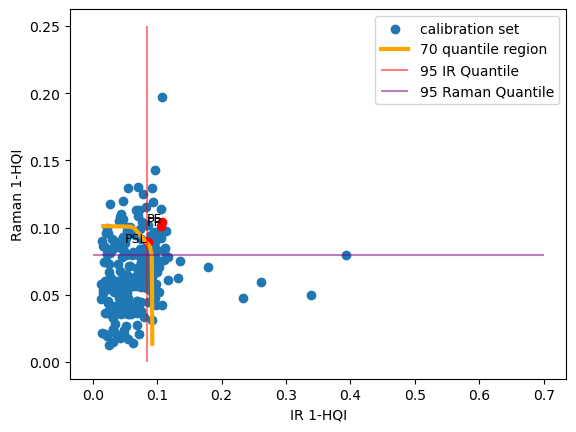

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


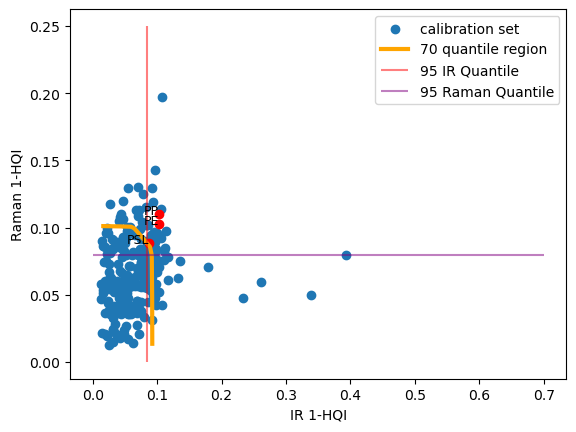

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


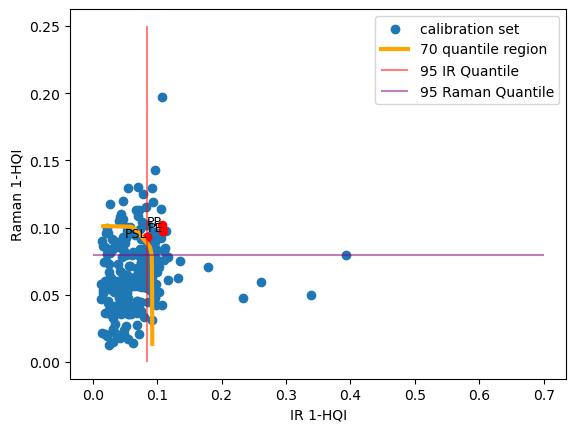

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


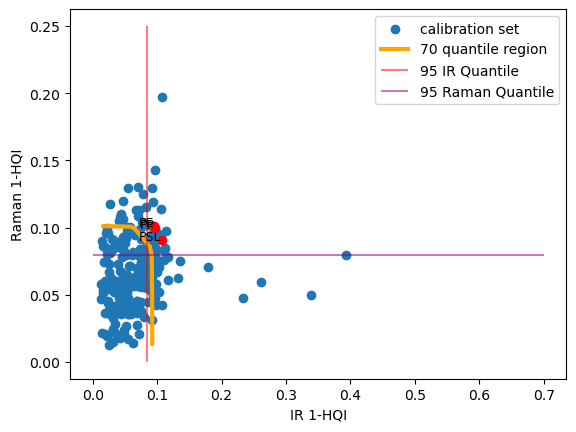

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


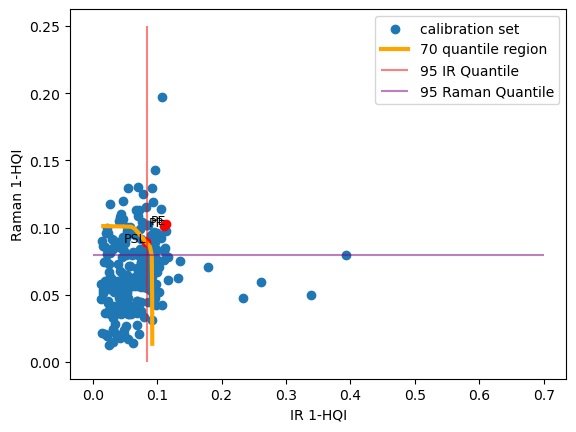

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


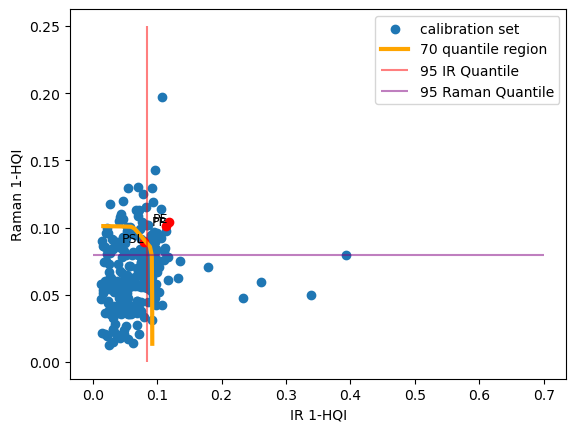

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


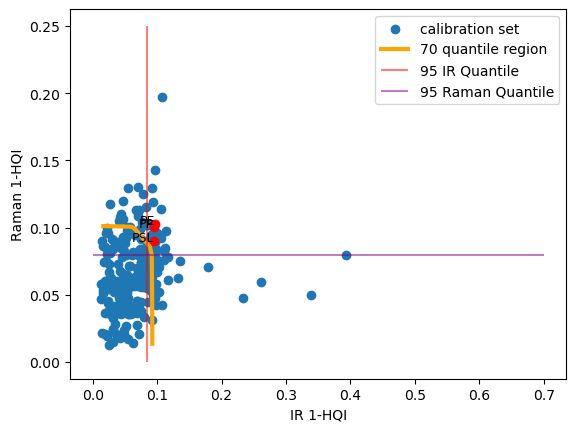

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


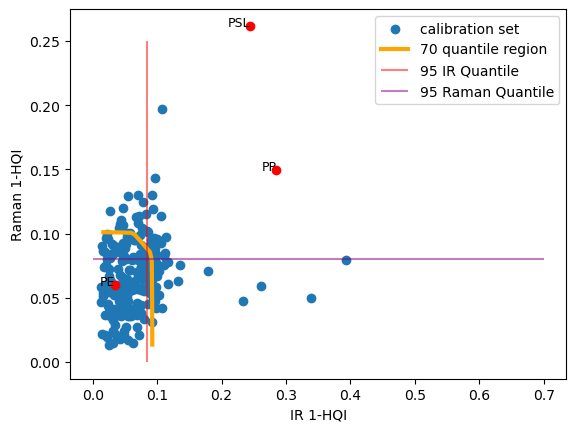

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


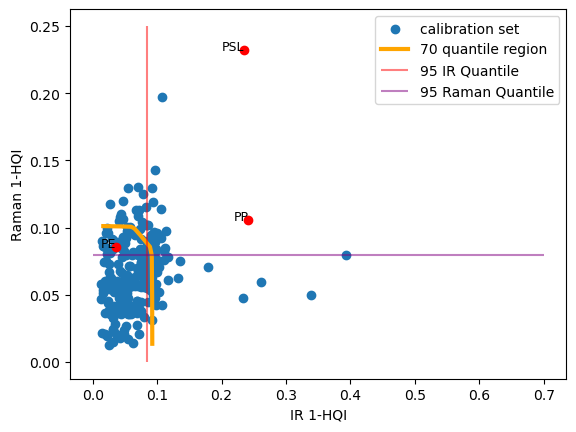

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


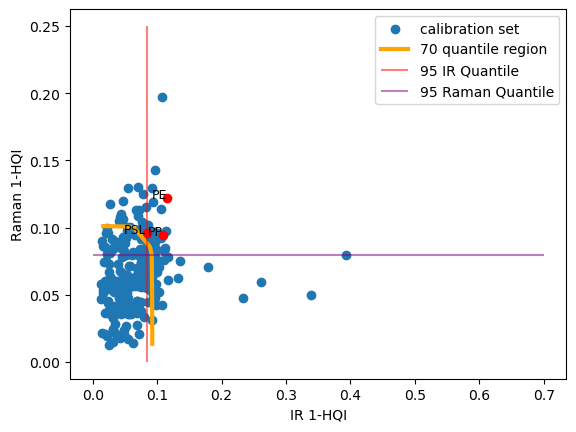

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman ['PE']


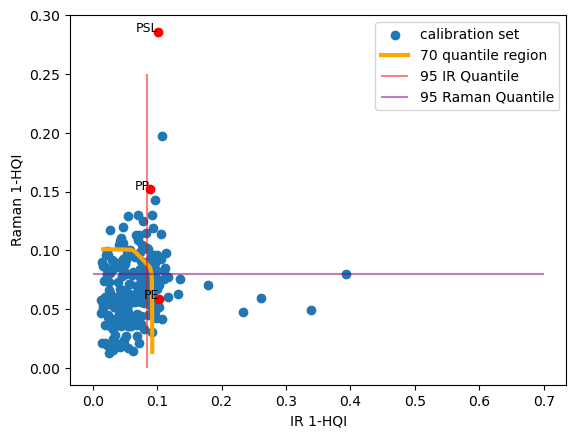

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


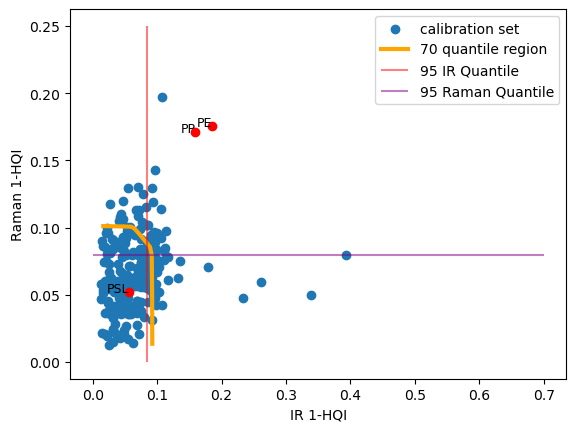

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


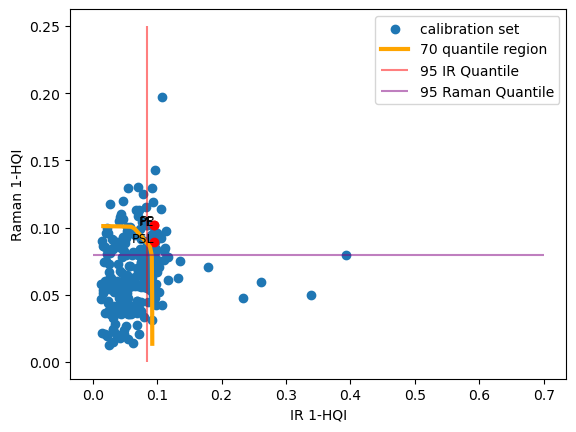

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


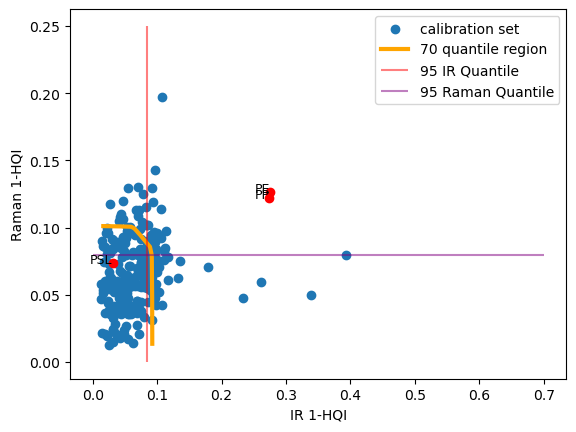

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


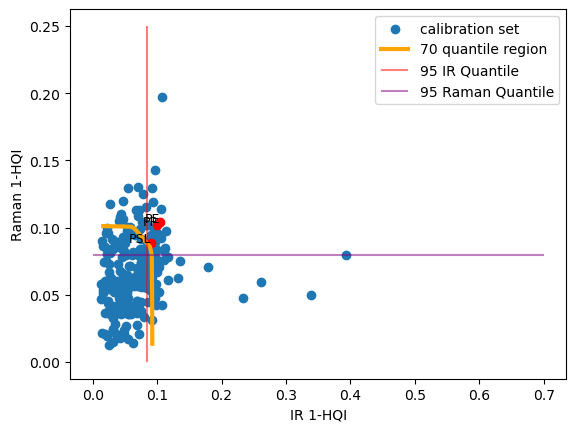

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


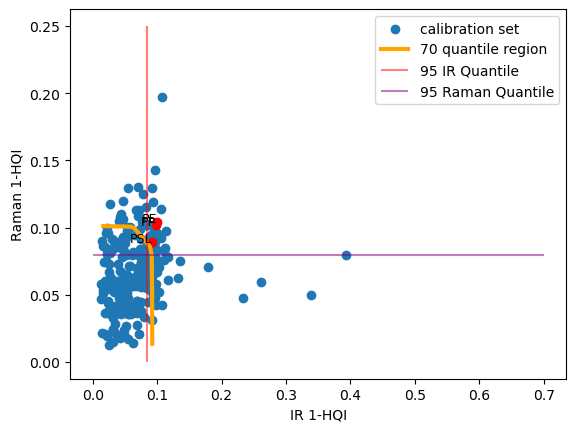

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


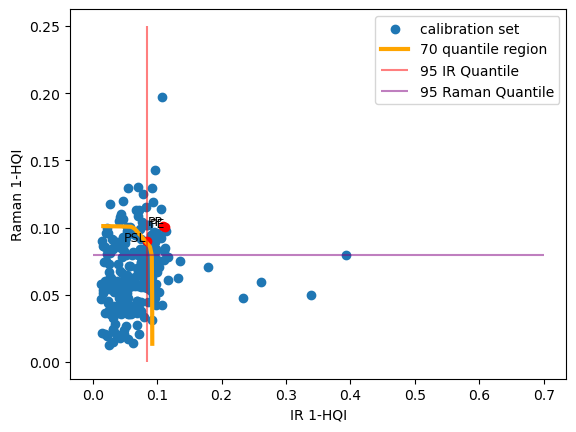

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman []


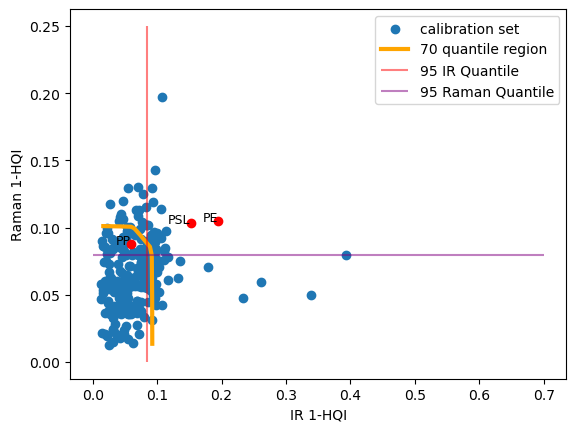

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


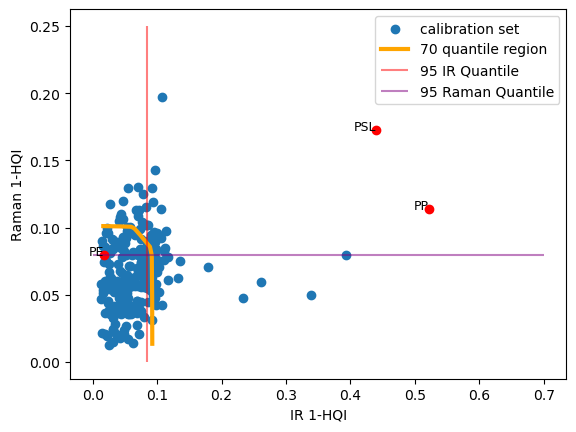

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE']
Raman []


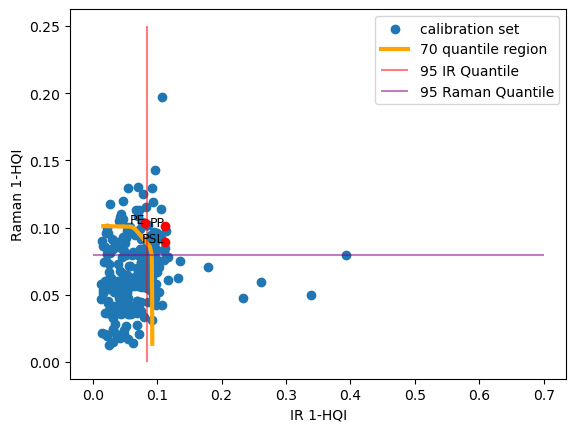

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


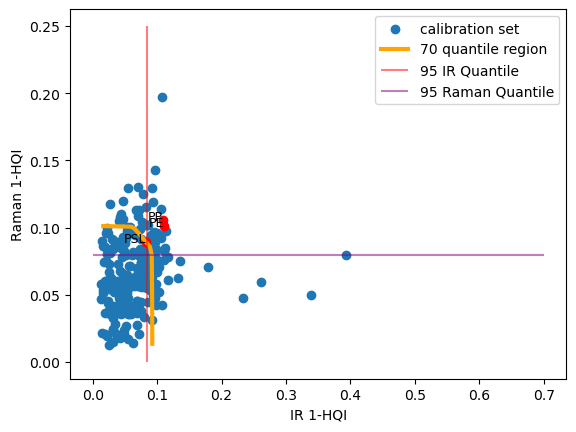

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


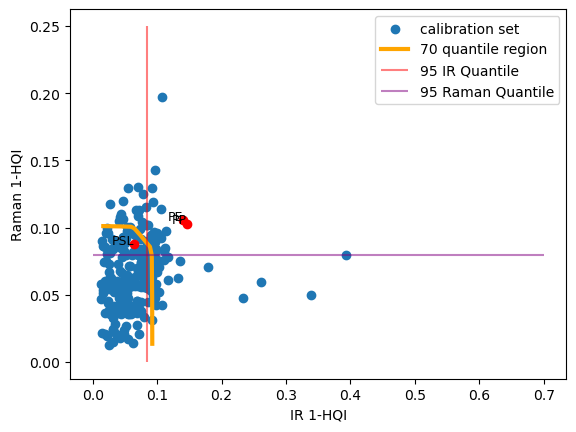

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


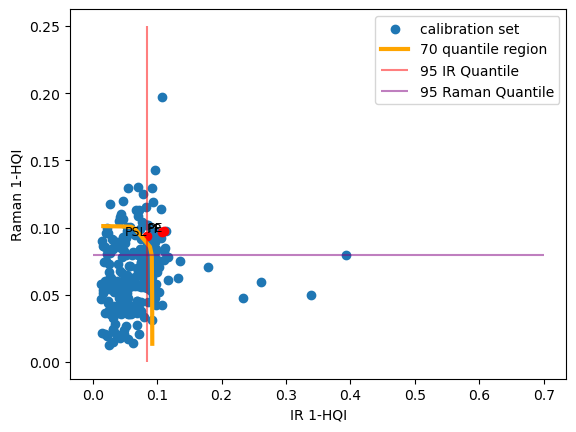

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE']
Raman []


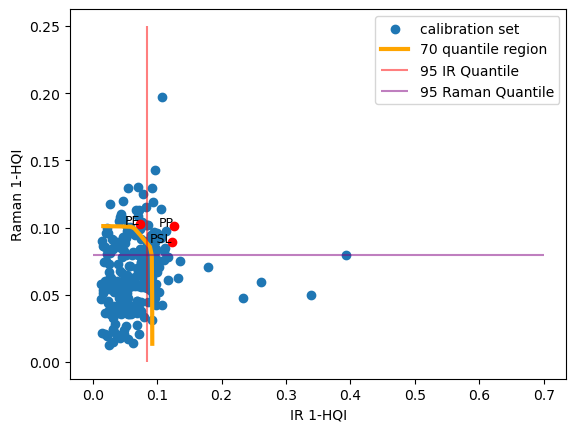

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


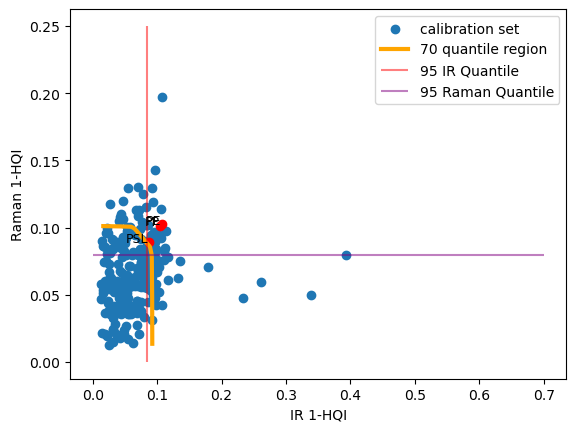

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


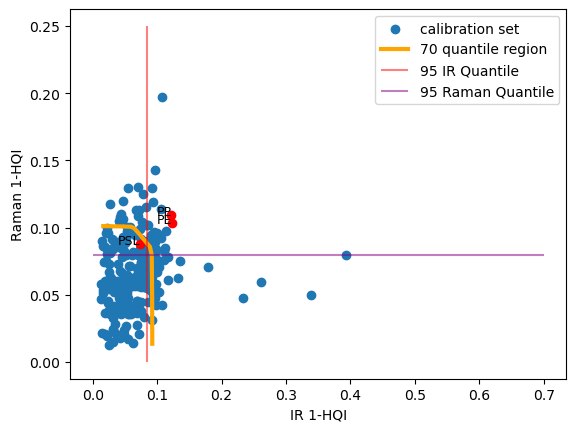

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


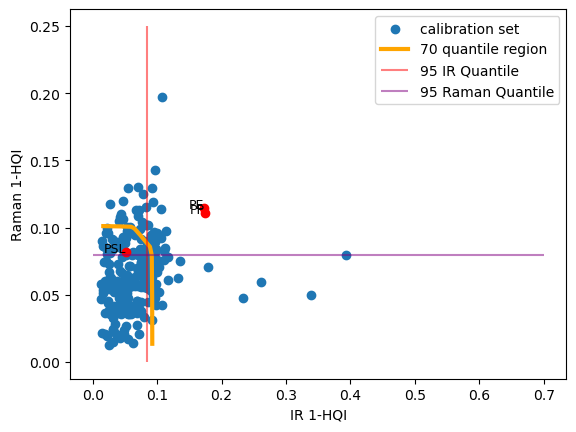

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


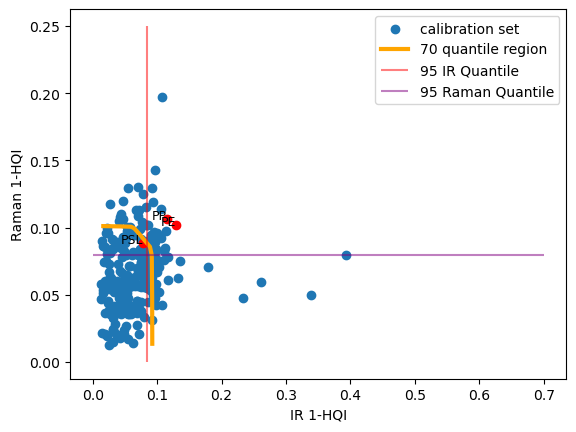

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


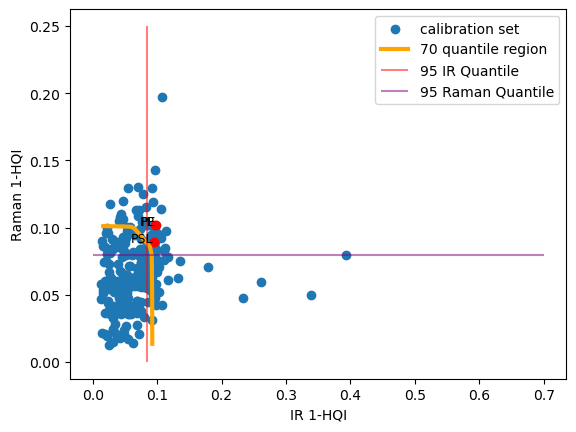

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE']
Raman []


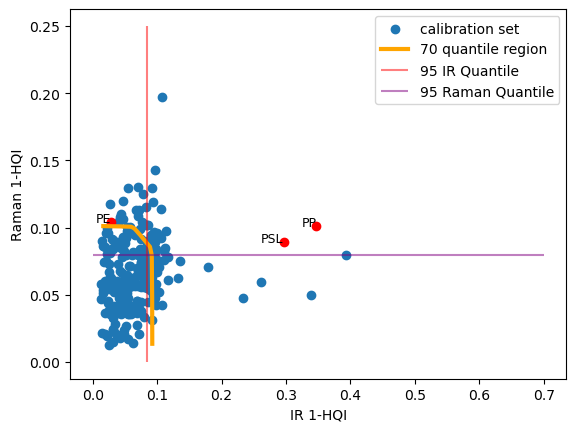

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


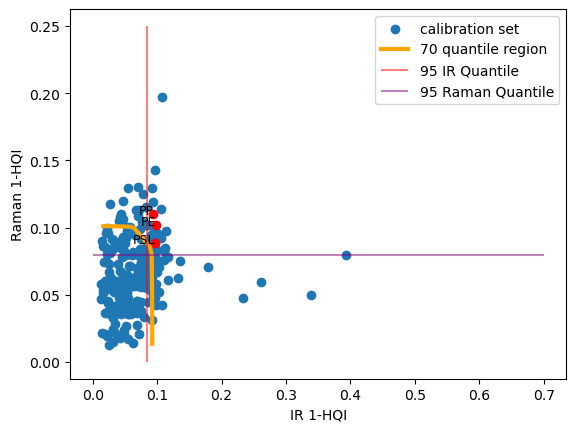

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


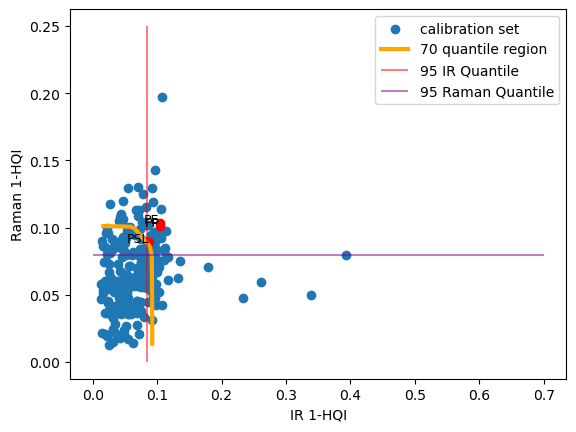

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


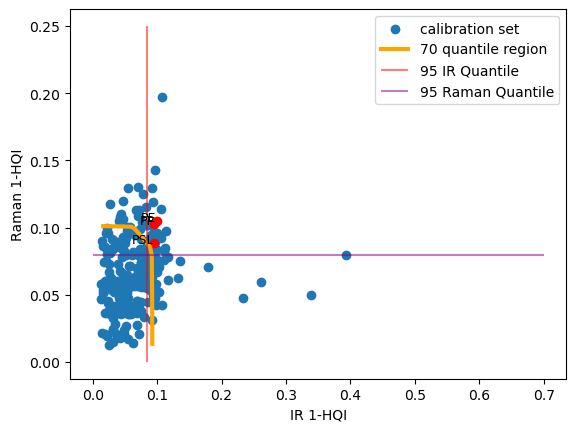

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


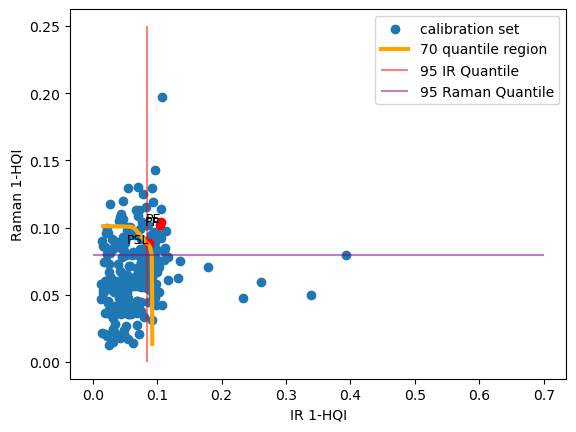

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


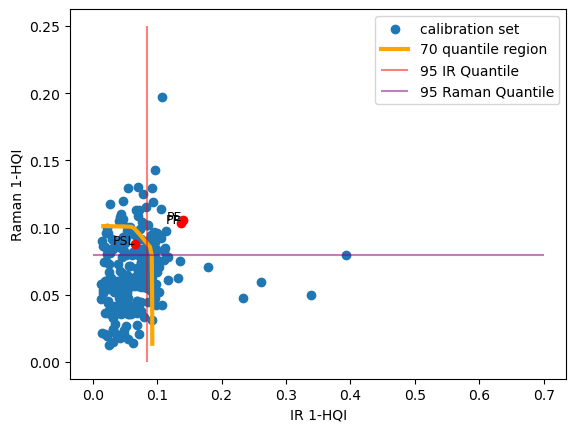

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


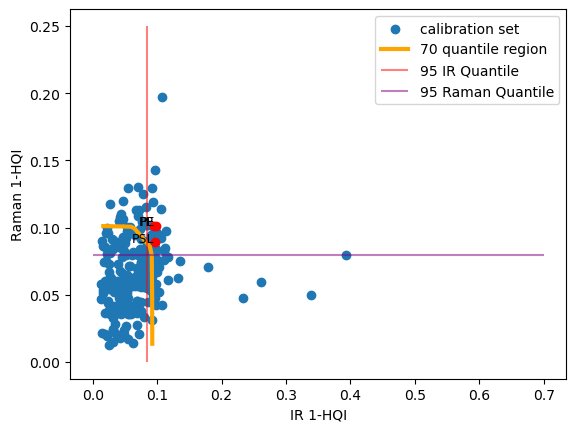

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


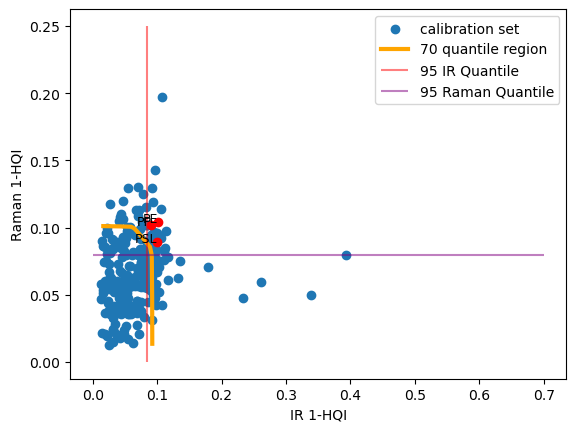

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PP']
Raman []


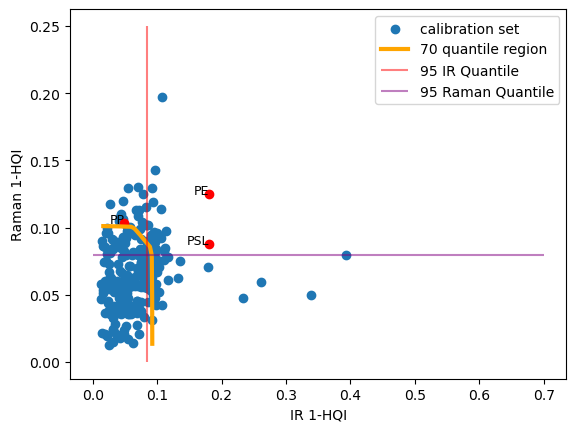

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


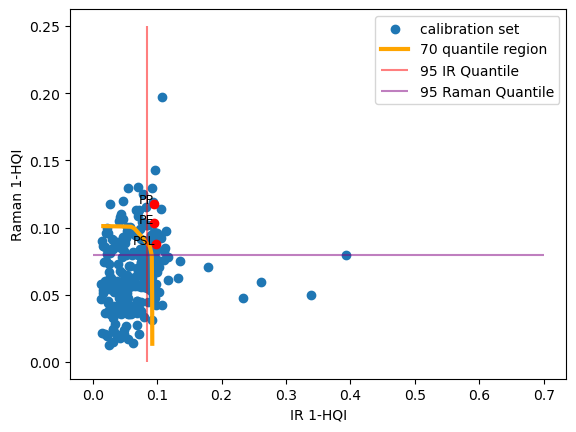

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PSL']
Raman []


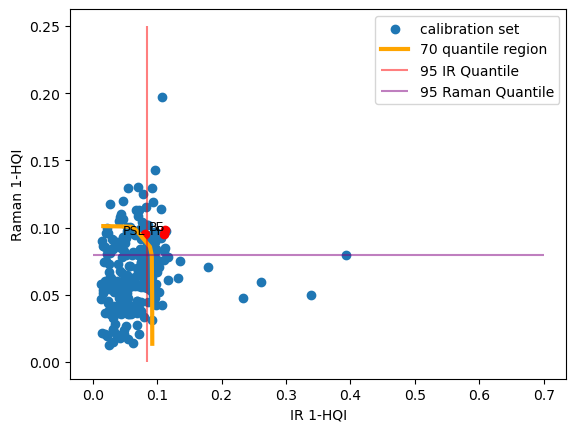

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


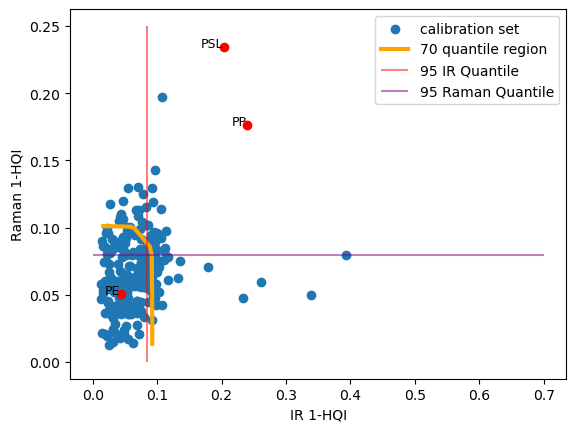

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PP']
IR ['PP']
Raman ['PP']


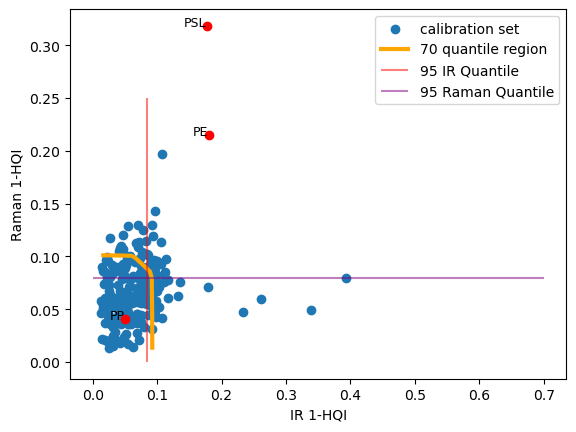

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


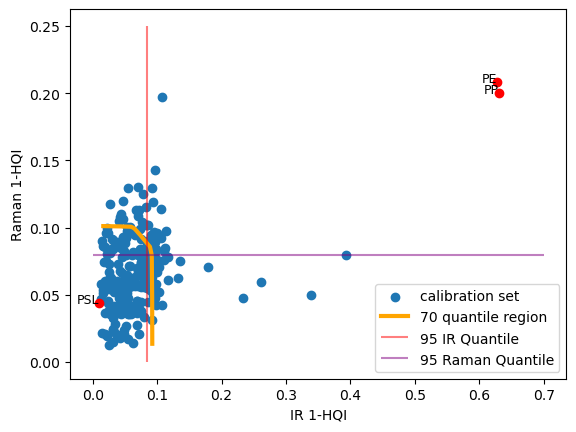

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


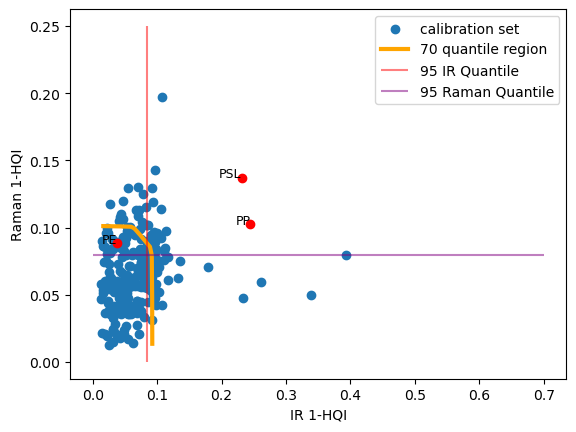

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


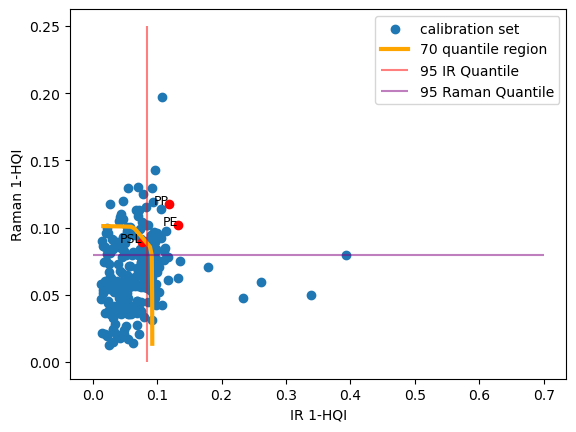

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


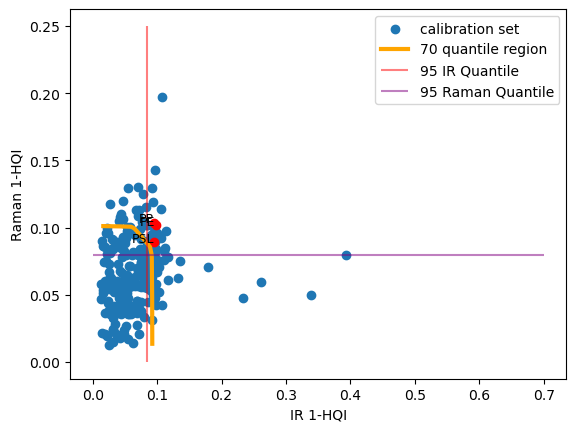

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


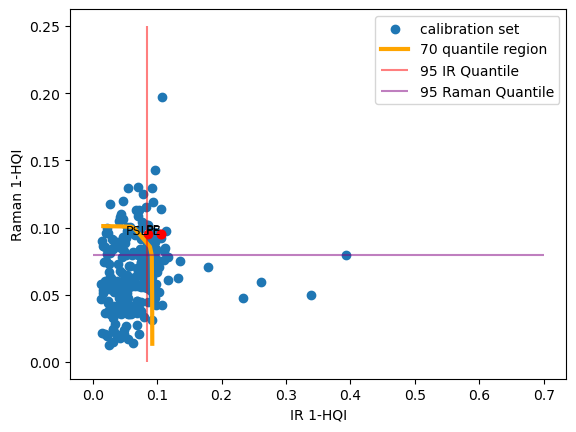

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


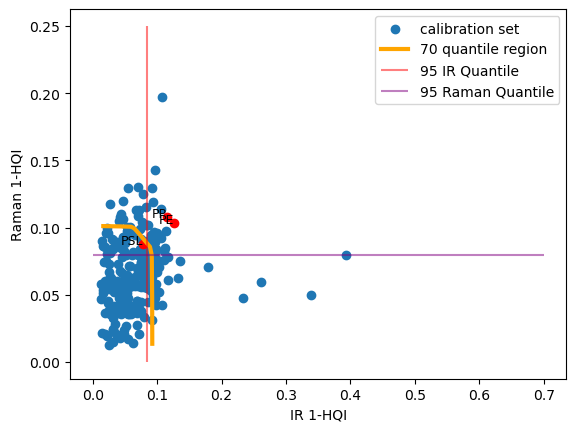

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


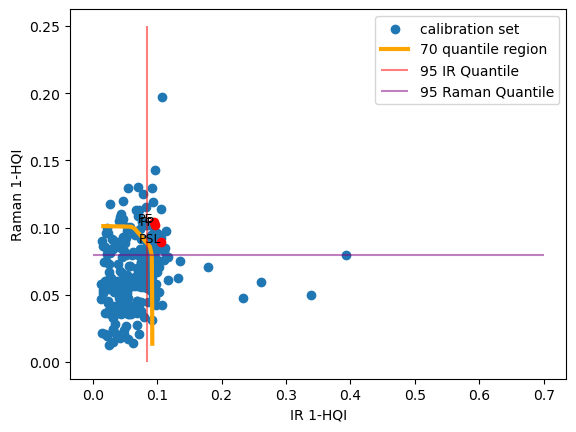

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman ['PSL']


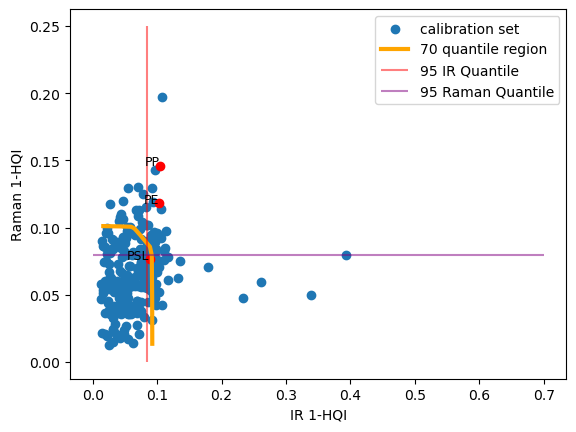

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


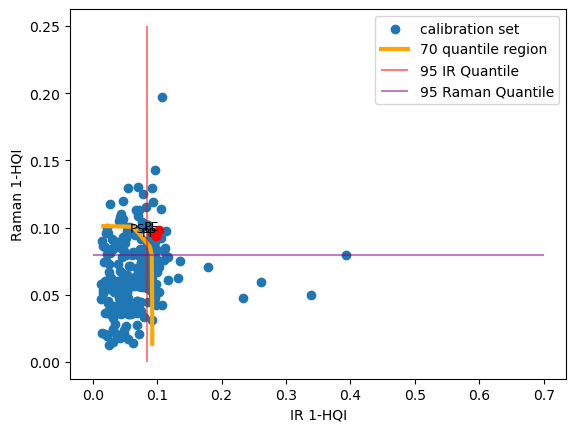

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PP']
Raman []


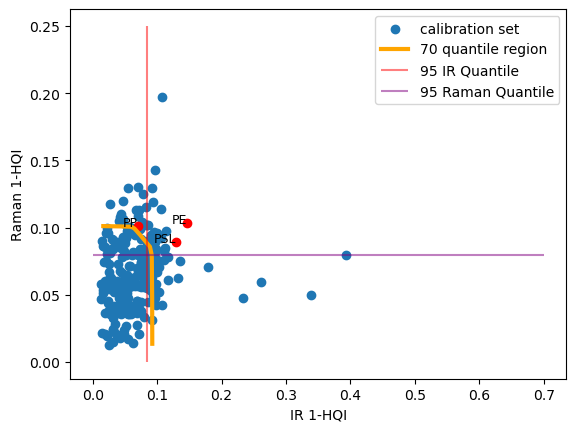

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


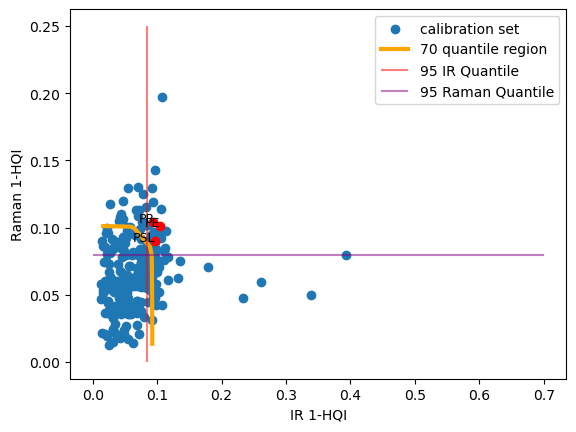

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


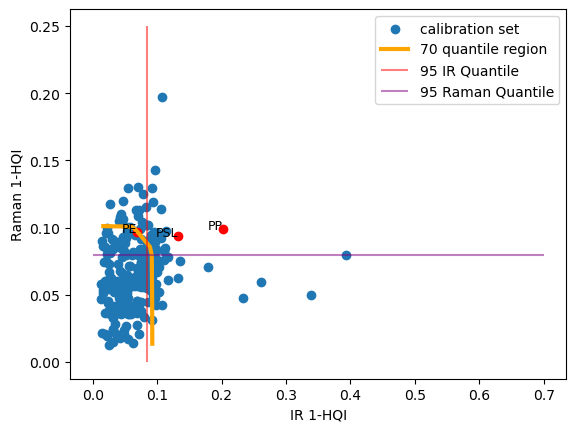

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


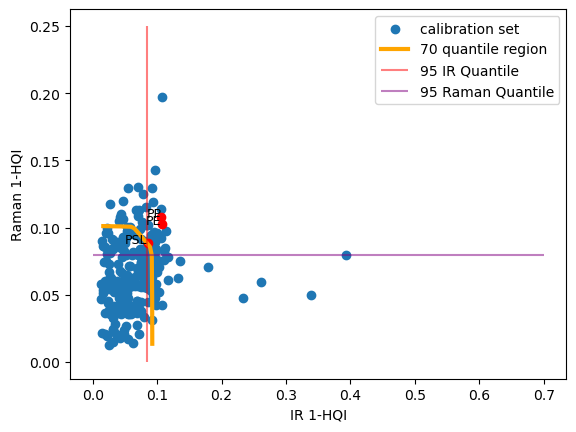

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


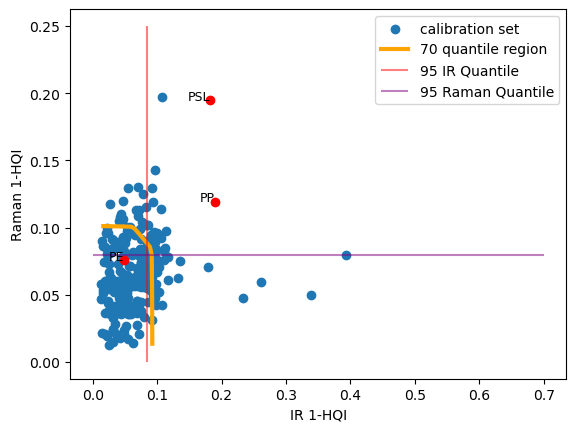

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


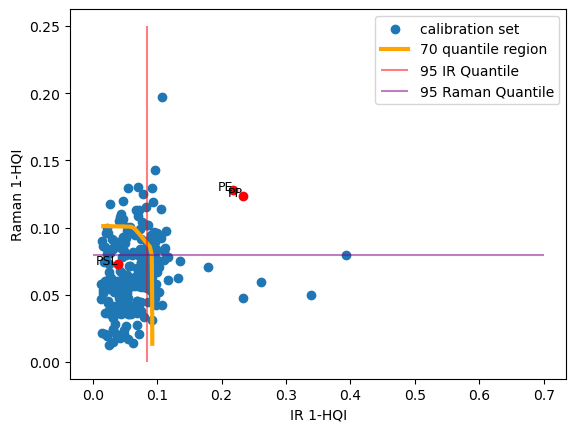

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


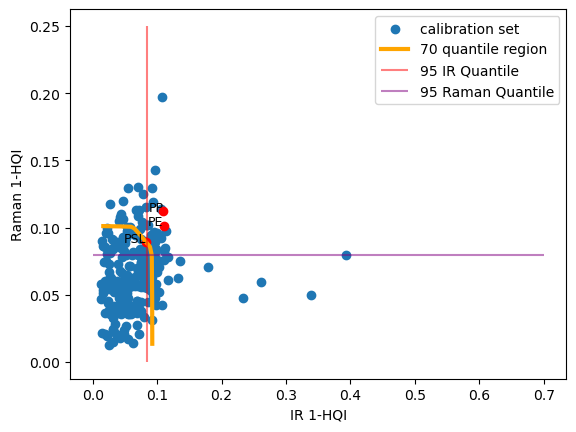

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman ['PSL']


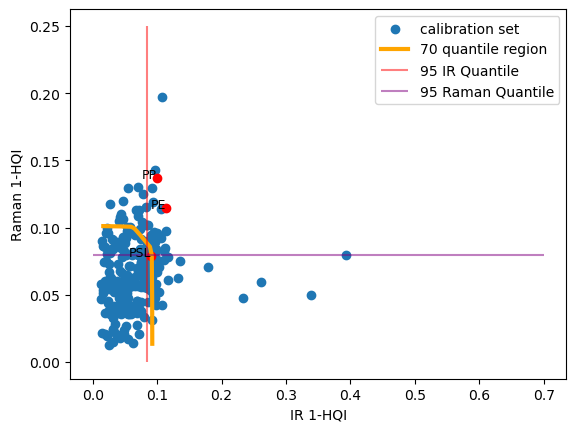

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


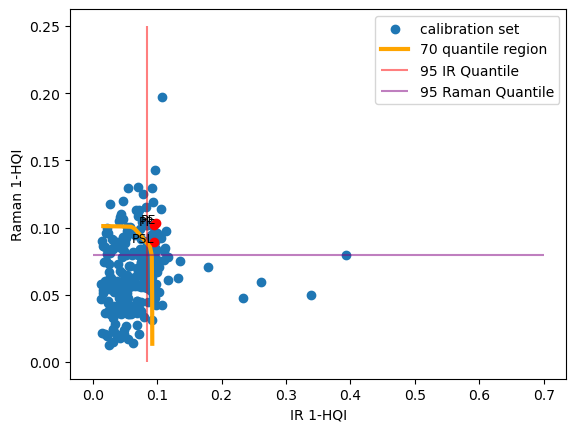

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


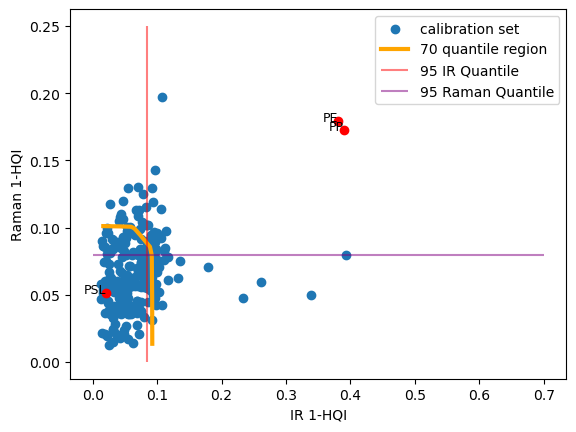

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


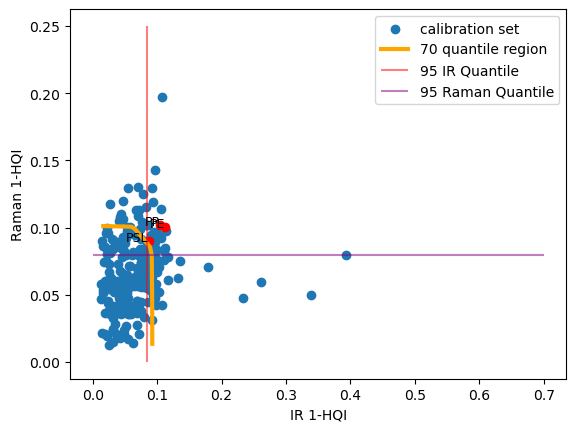

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


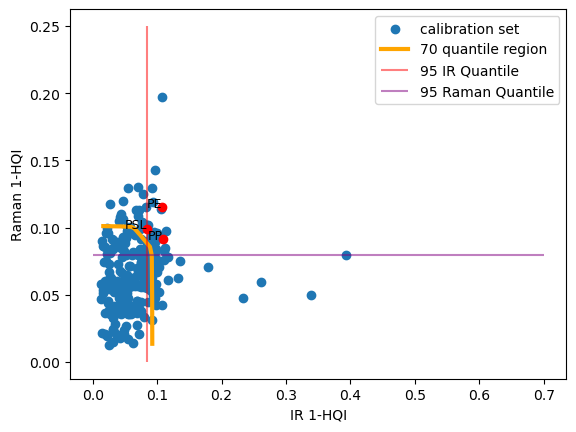

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


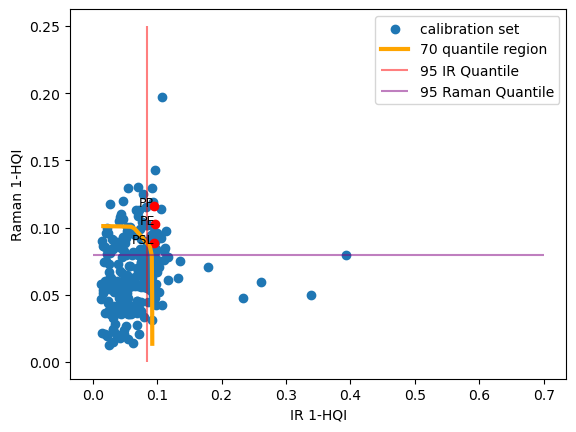

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


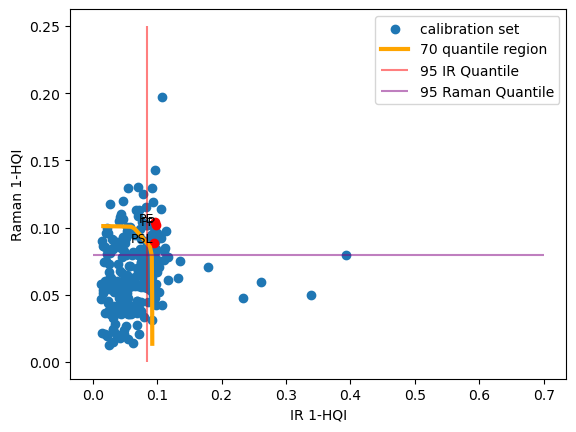

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


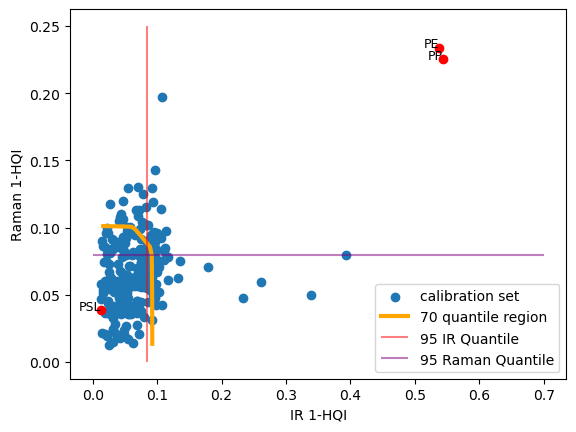

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman ['PSL']


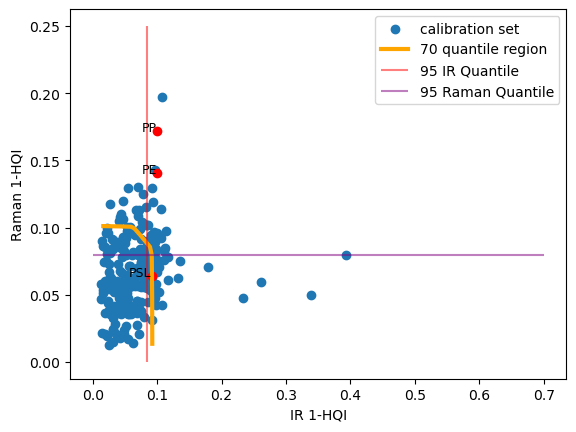

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


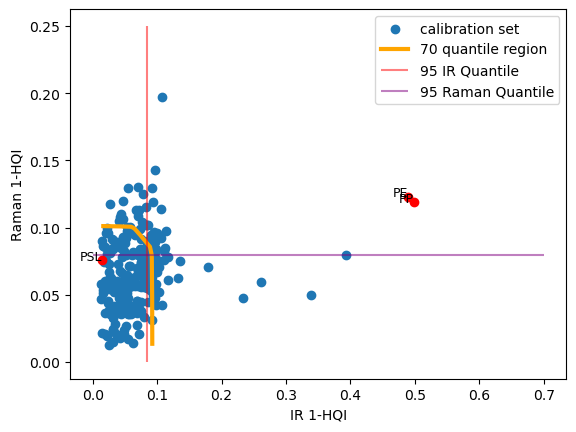

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


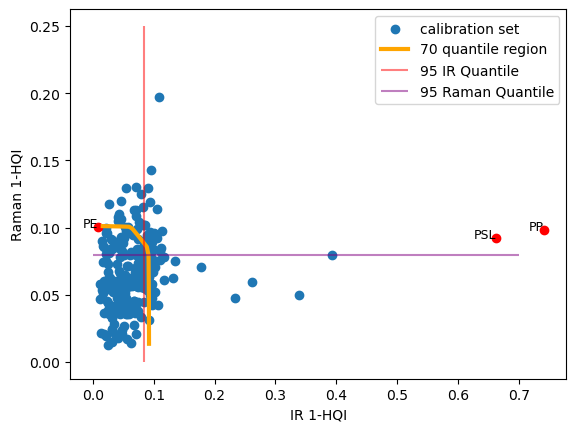

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman ['PSL']


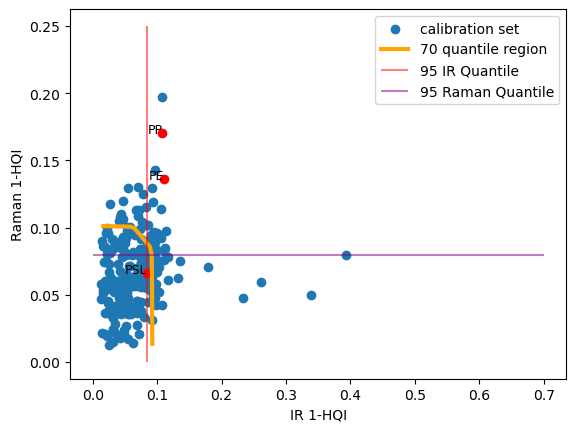

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


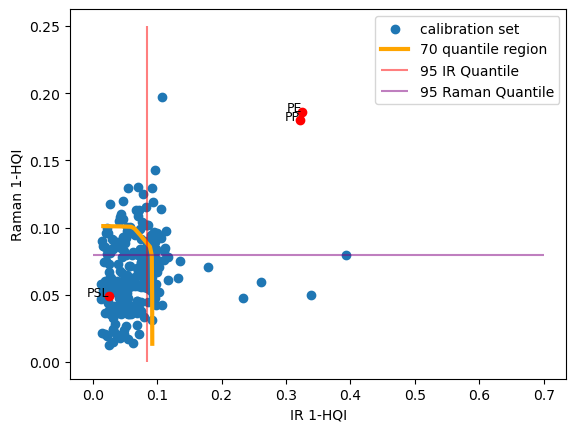

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


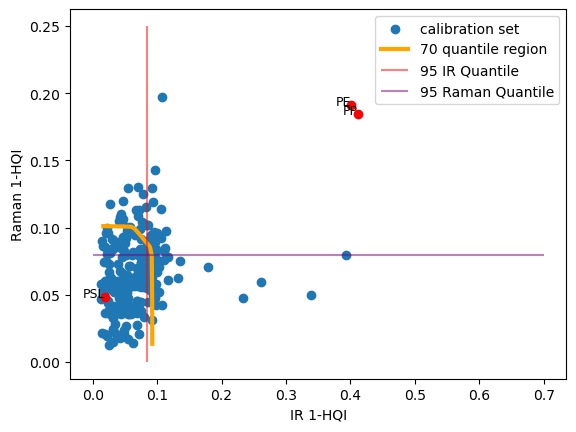

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


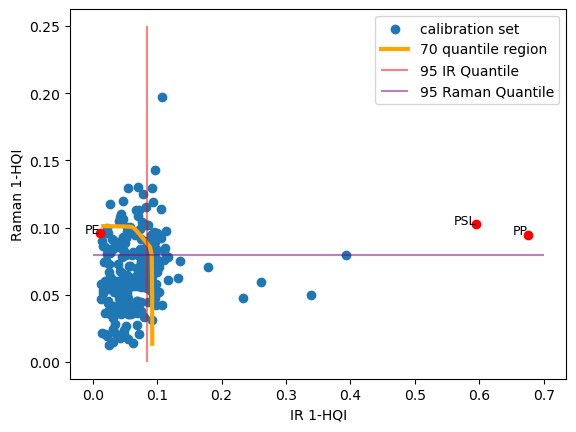

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


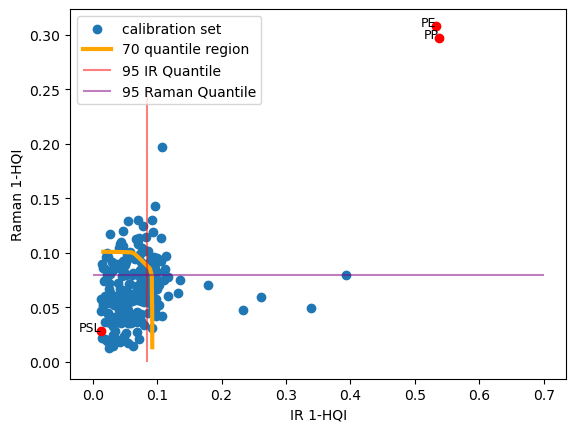

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


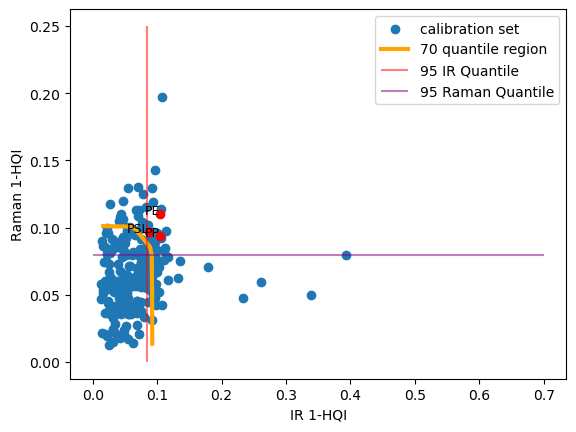

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


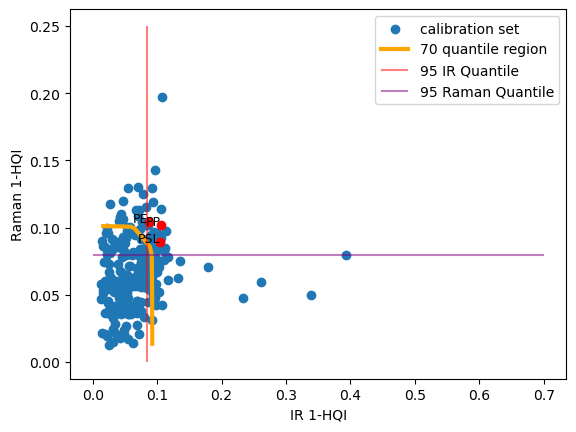

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


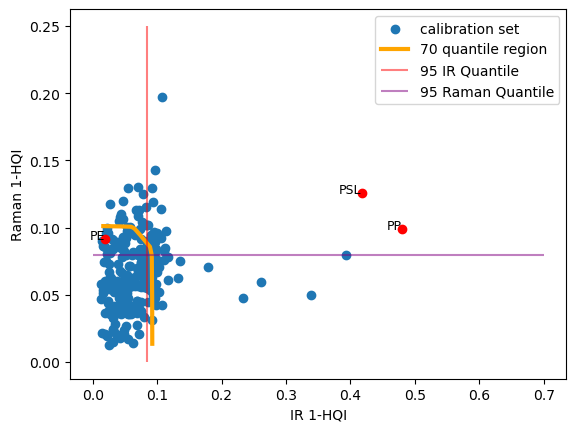

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


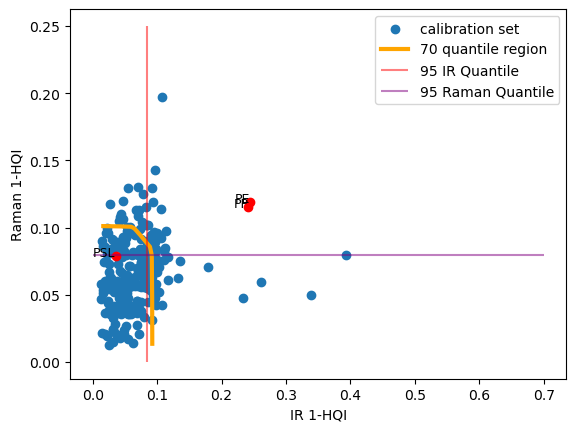

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


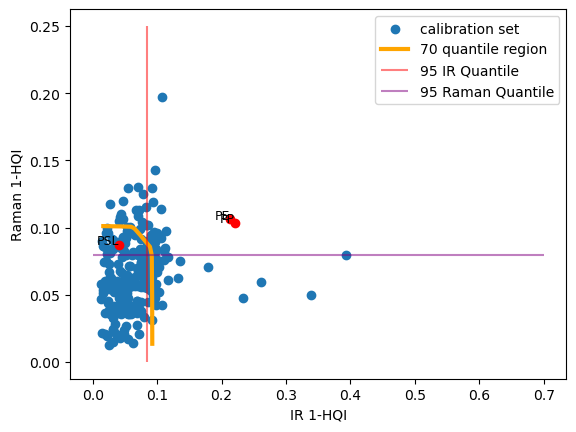

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


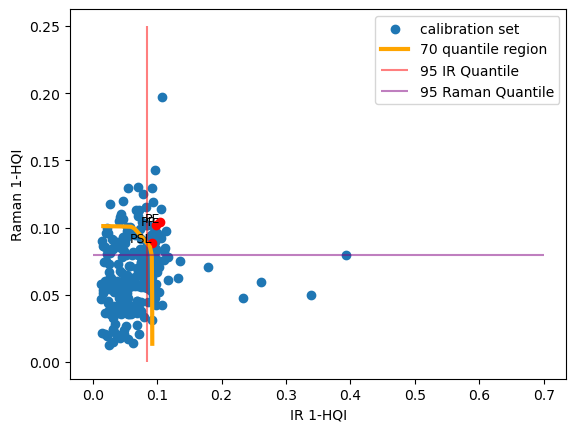

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman []


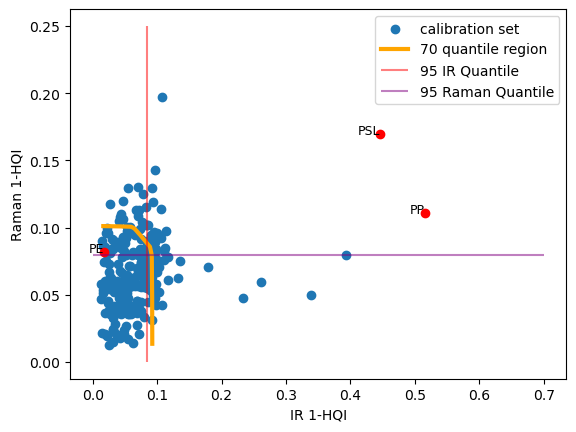

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


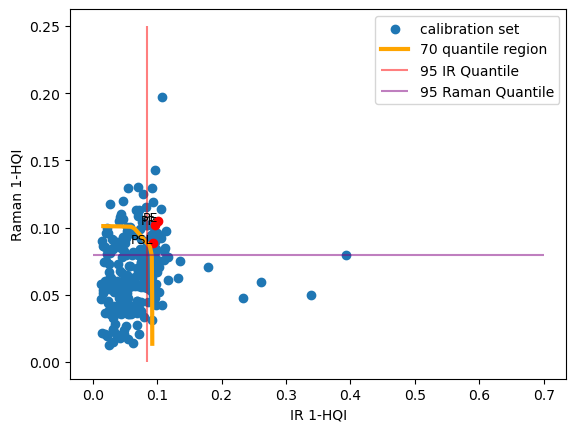

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


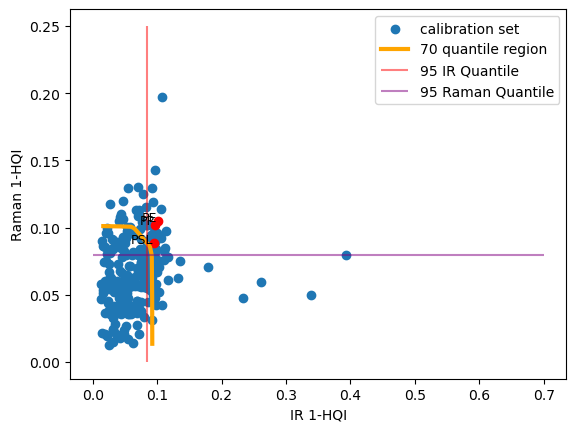

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


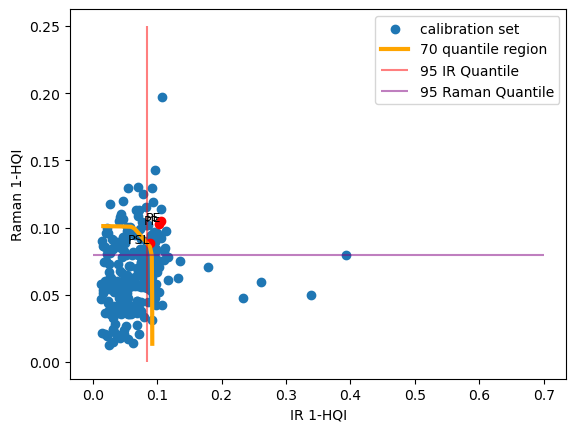

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


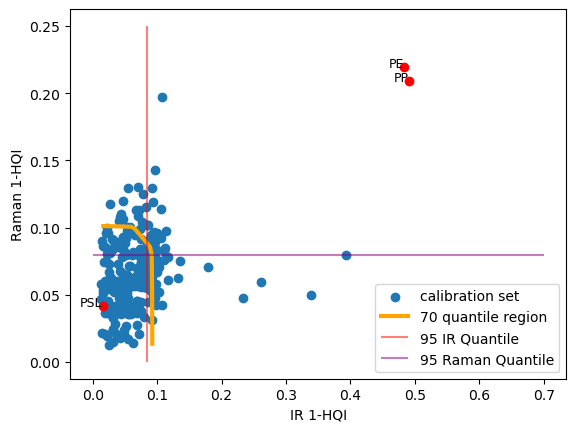

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


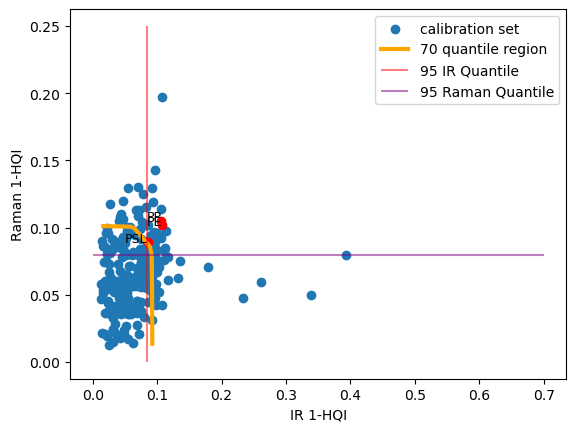

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


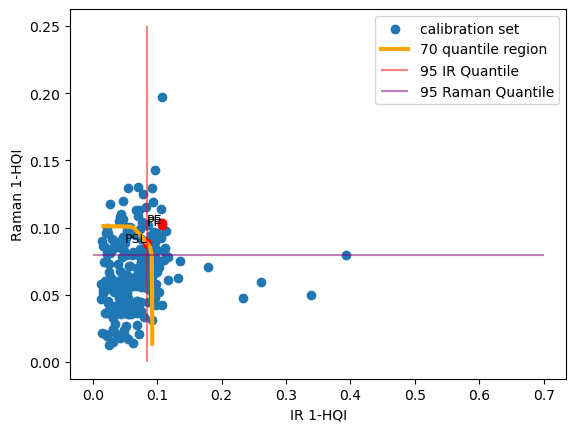

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


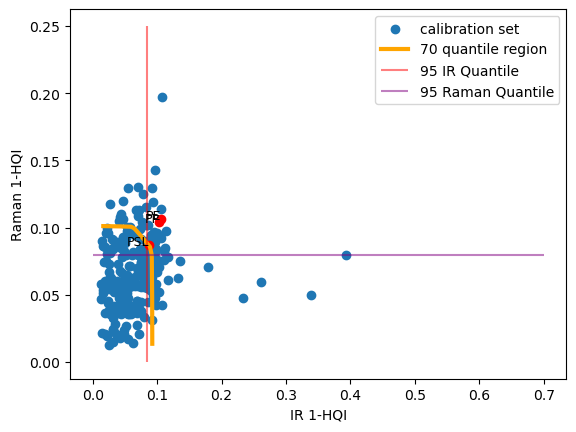

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


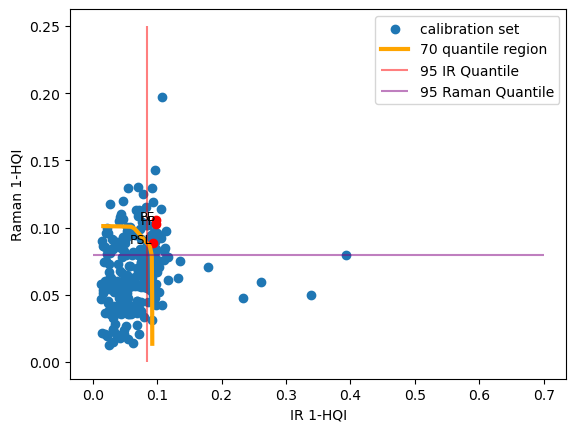

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


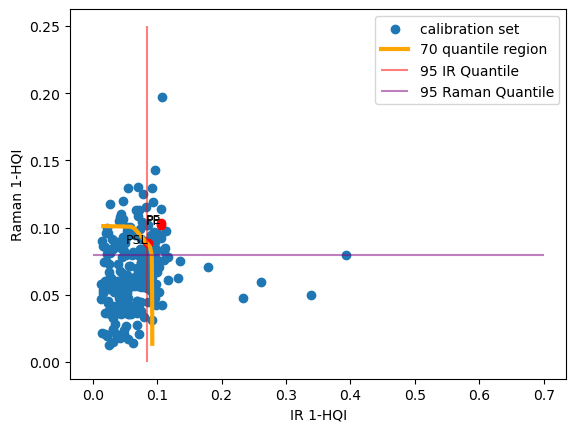

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


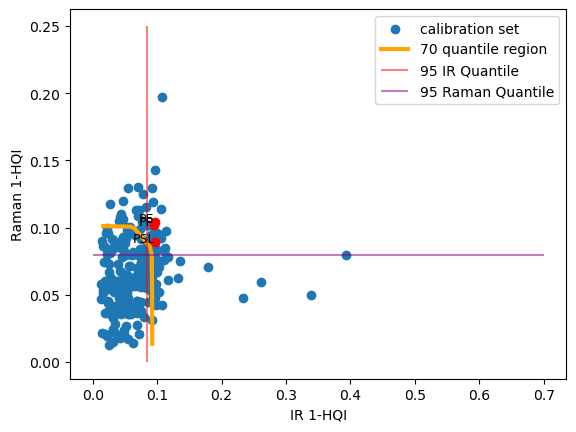

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


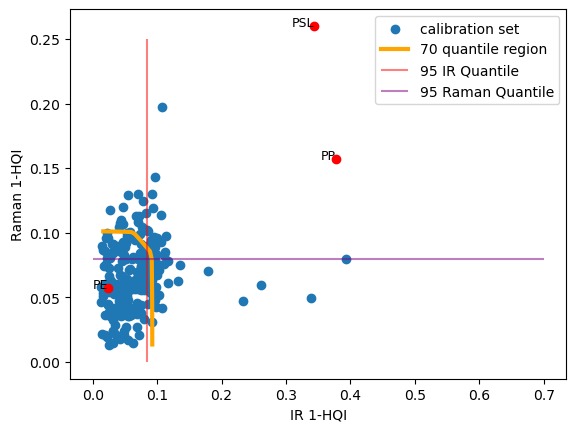

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


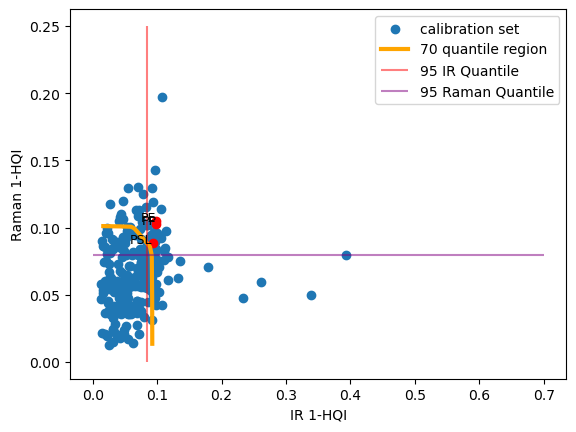

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


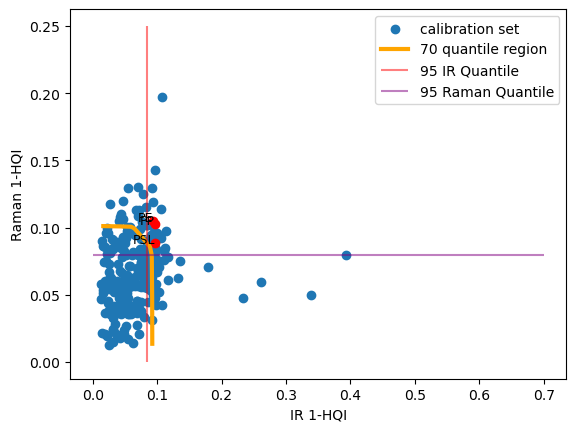

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


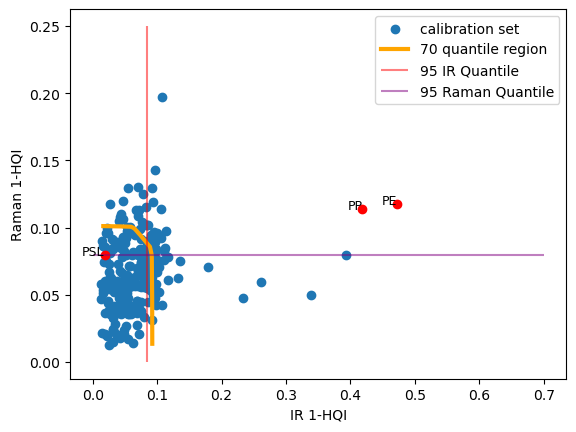

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


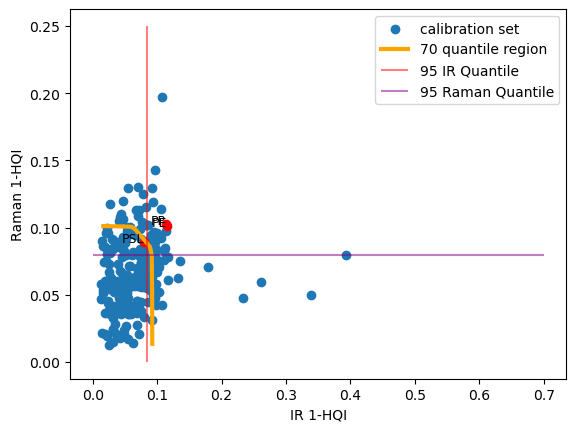

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


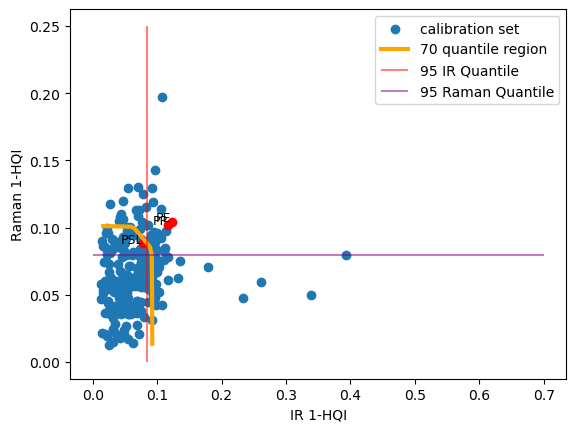

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PE']
Raman []


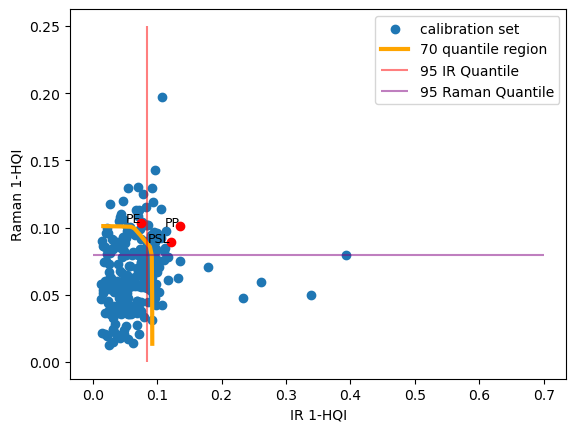

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


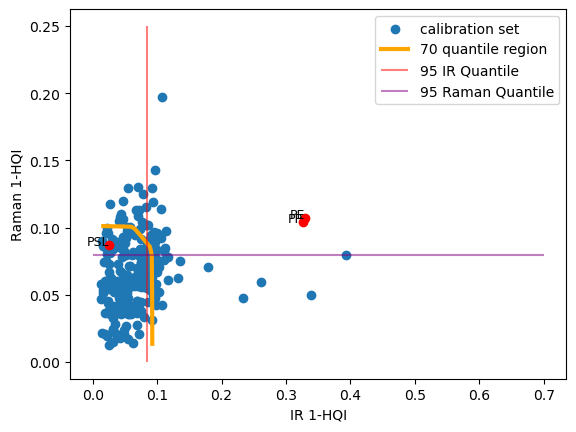

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


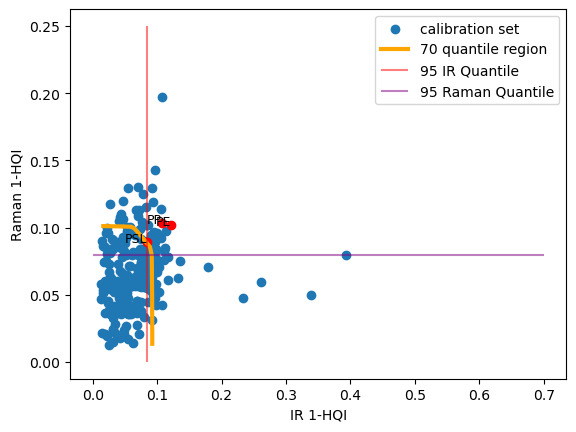

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


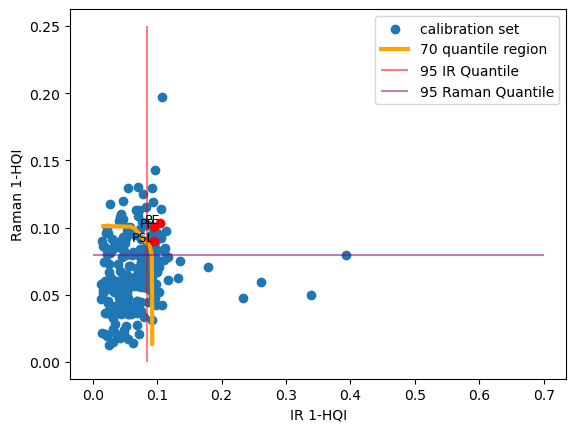

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman ['PSL']


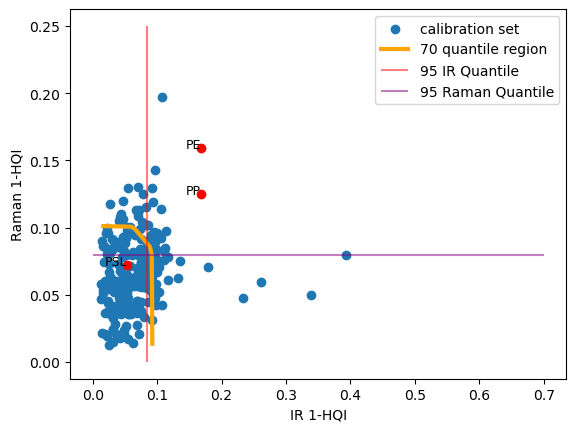

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR ['PSL']
Raman []


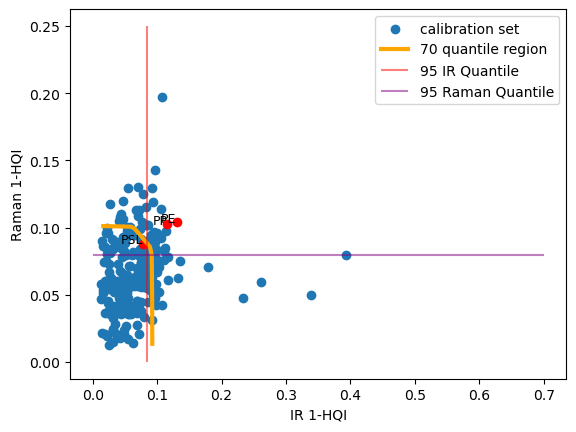

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


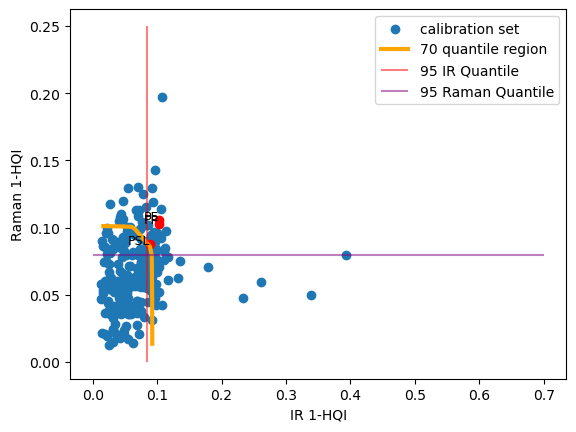

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


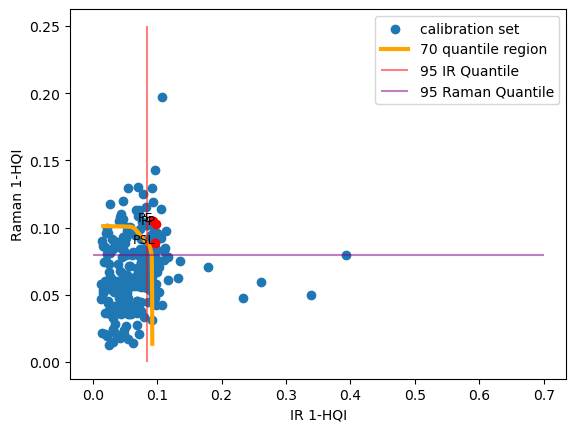

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


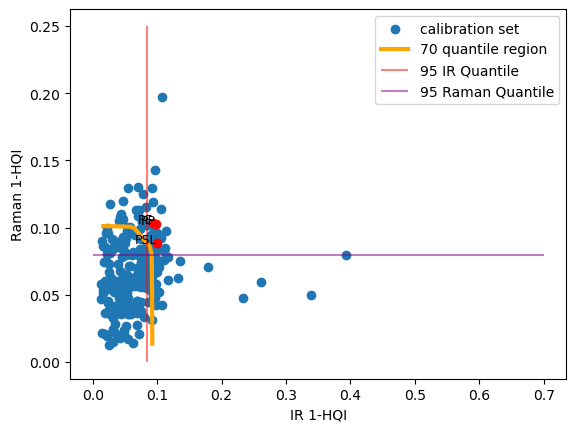

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


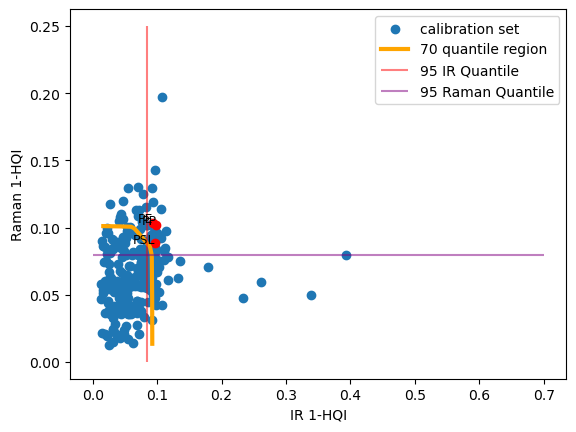

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


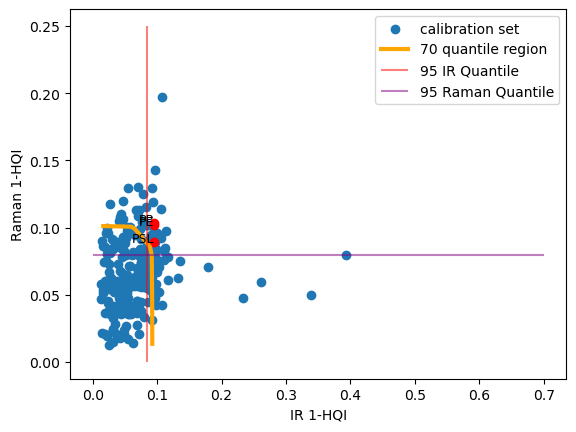

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


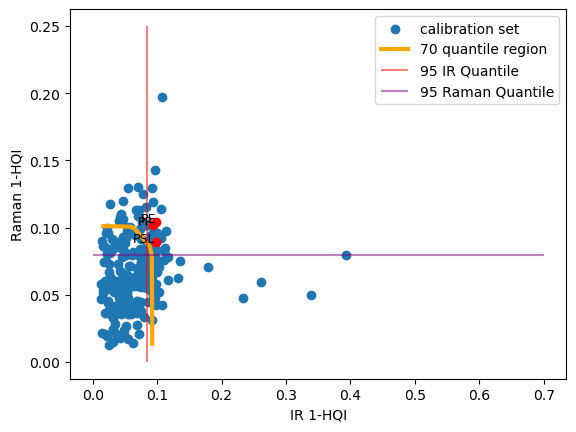

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR ['PP']
Raman []


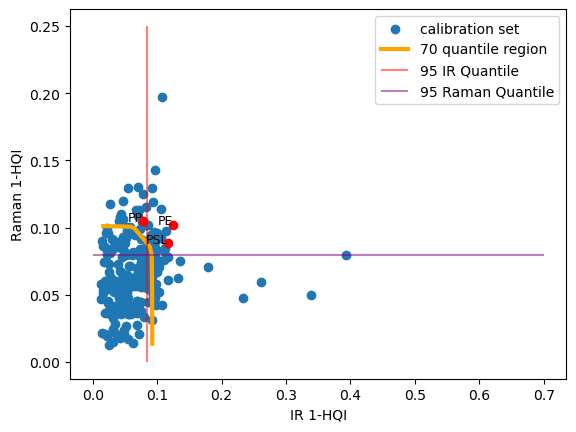

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP ['PSL']
IR []
Raman []


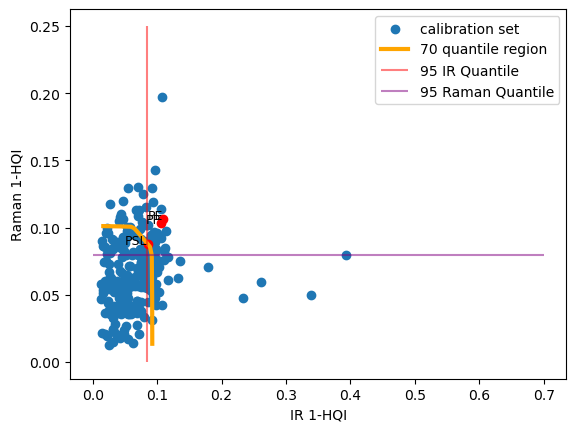

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  1.80it/s]


In [81]:
pred_set_list = defaultdict(list)
env_list_list = []
for id_ in range(253):#np.where(label_amb_ir==3)[0]:
    score_example = [score_list_test[0][id_:id_+1], 
                 score_list_test[1][id_:id_+1]] 
    
    (ps_list, 
         ps_ir_list, 
         ps_raman_list, 
         env_list, 
         cal_smx_arr, 
         cal_idx_list, 
         q_ir_list, 
         q_raman_list) = envelop(score_list, 
                                 label_ir, 
                                 score_example,
                                 alphas=[0.30],
                                 label_table=label_table,
                                 N_sim=1, 
                                 quant_prop=.2, 
                                 cal_prop=0.8, 
                                 seed_init=10,)
    
    pred_set_list['mvcp'] = pred_set_list['mvcp'] + ps_list[30]
    pred_set_list['IR'] = pred_set_list['IR'] + ps_ir_list[30]
    pred_set_list['Raman'] = pred_set_list['Raman'] + ps_raman_list[30]
    env_list_list.append(env_list)

  0%|                                                     | 0/1 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


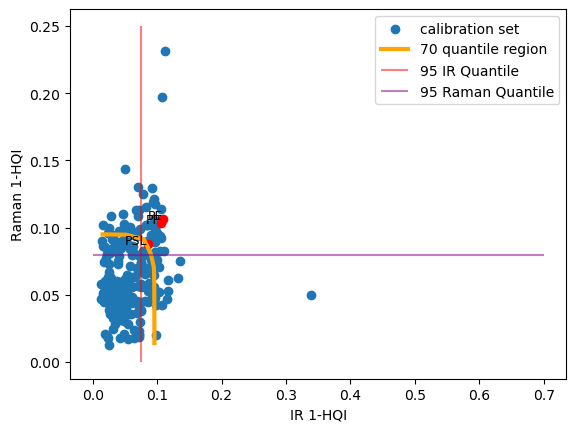

MVCP ['PSL']
IR []
Raman []


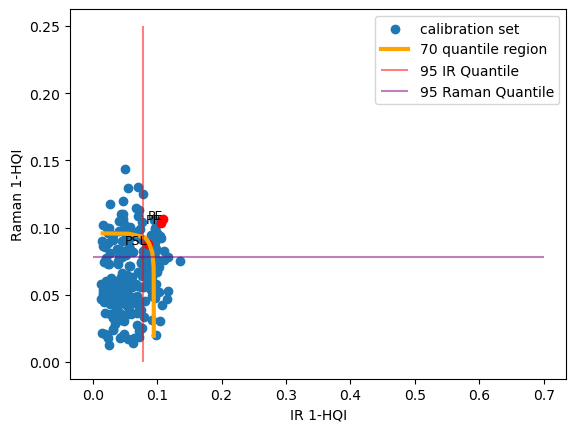

MVCP []
IR []
Raman []


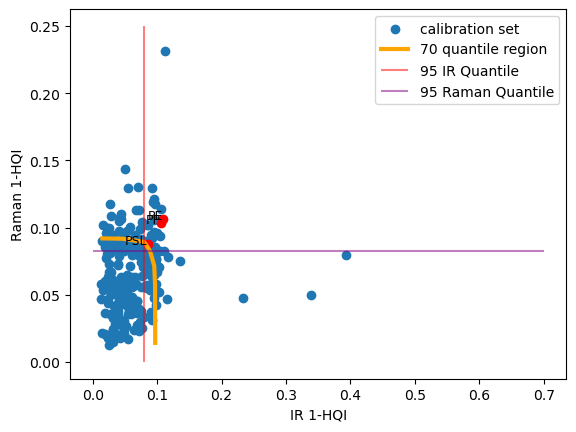

MVCP ['PSL']
IR []
Raman []


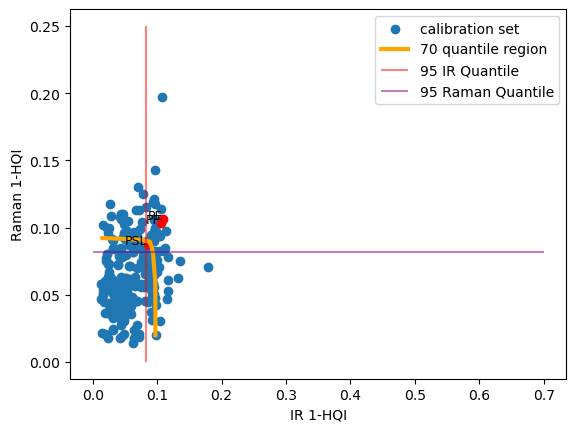

MVCP ['PSL']
IR []
Raman []


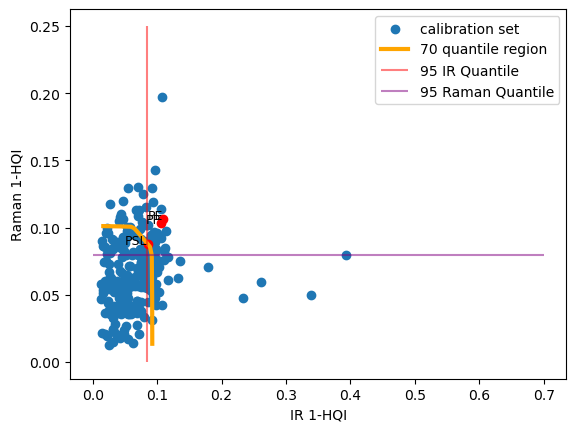

MVCP []
IR []
Raman []


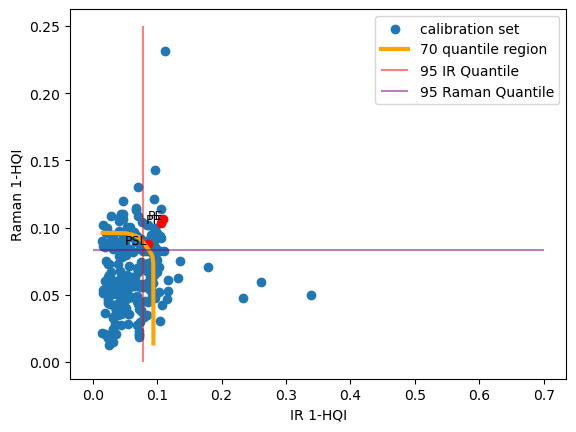

MVCP []
IR []
Raman []


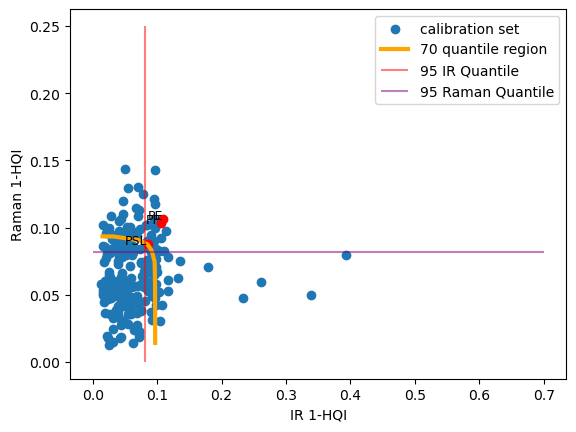

MVCP []
IR []
Raman []


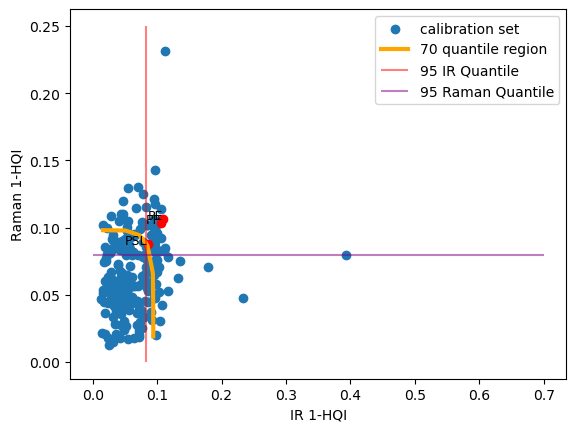

MVCP []
IR []
Raman []


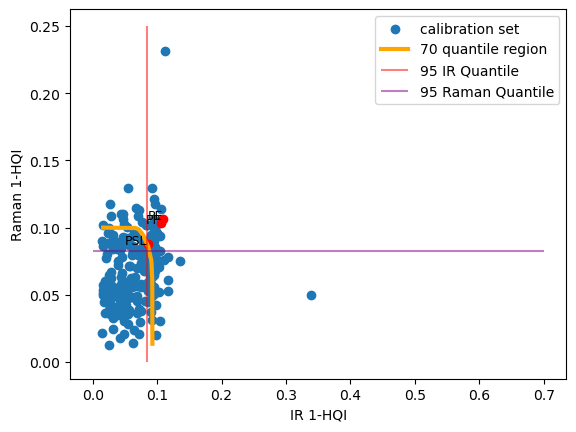

MVCP ['PSL']
IR []
Raman []


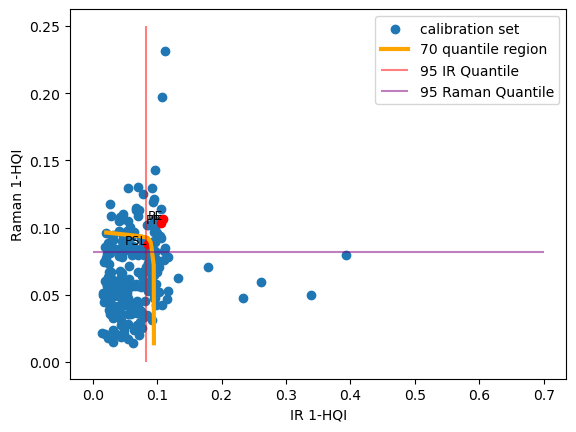

MVCP ['PSL']
IR []
Raman []


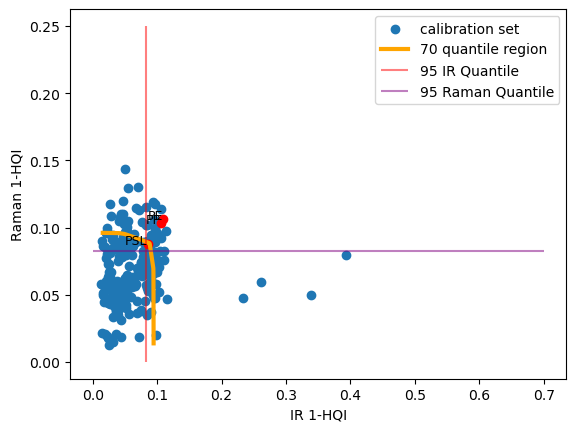

MVCP []
IR []
Raman []


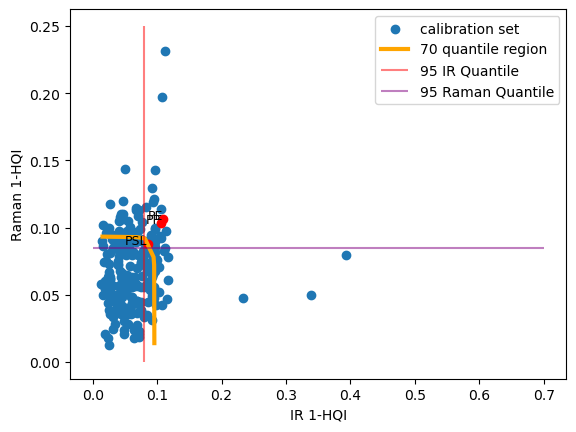

MVCP ['PSL']
IR []
Raman []


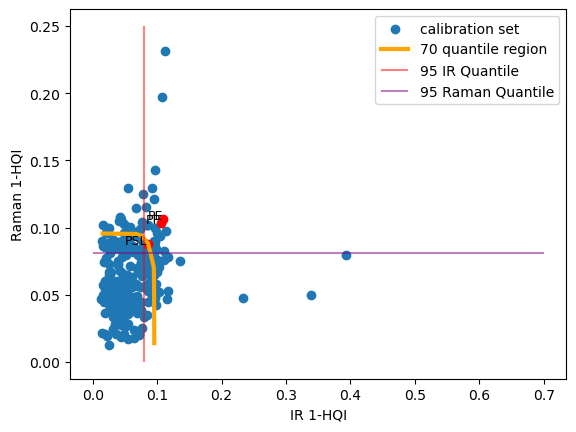

MVCP ['PSL']
IR []
Raman []


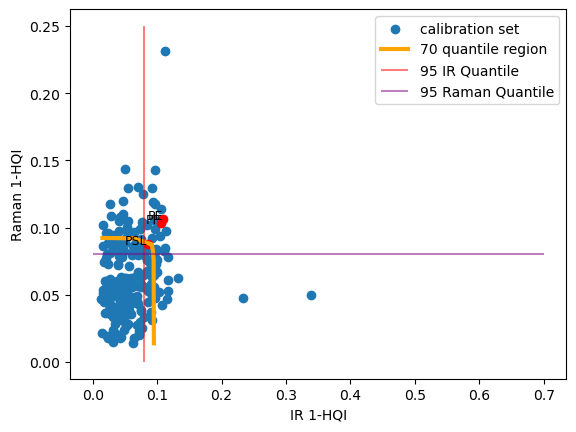

MVCP ['PSL']
IR []
Raman []


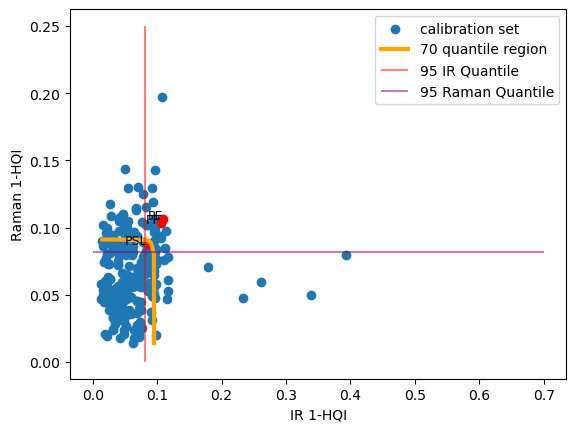

MVCP ['PSL']
IR ['PSL']
Raman []


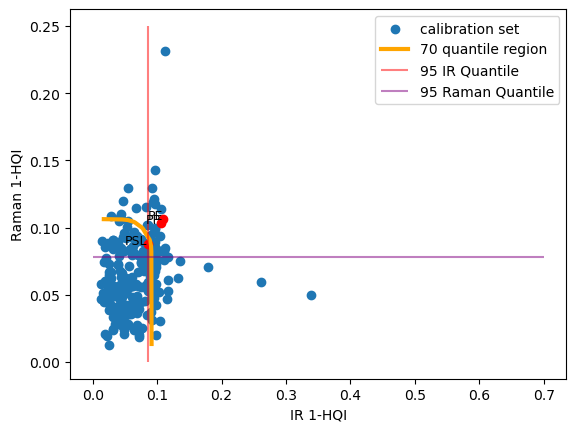

MVCP ['PSL']
IR []
Raman []


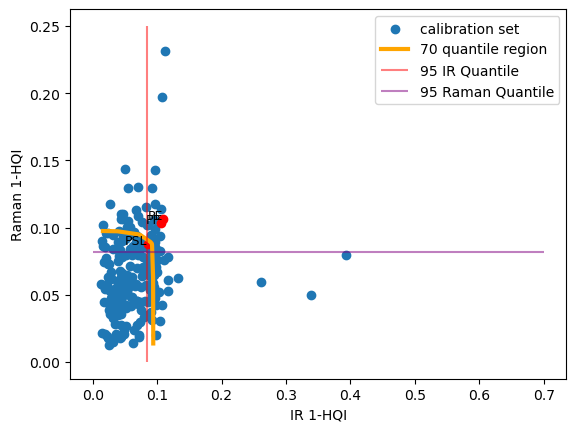

MVCP []
IR []
Raman []


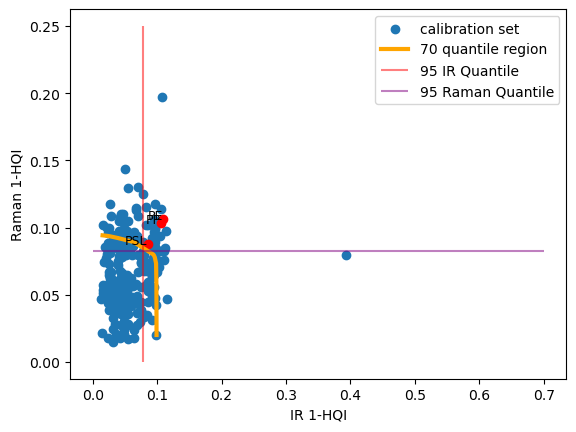

MVCP []
IR []
Raman []


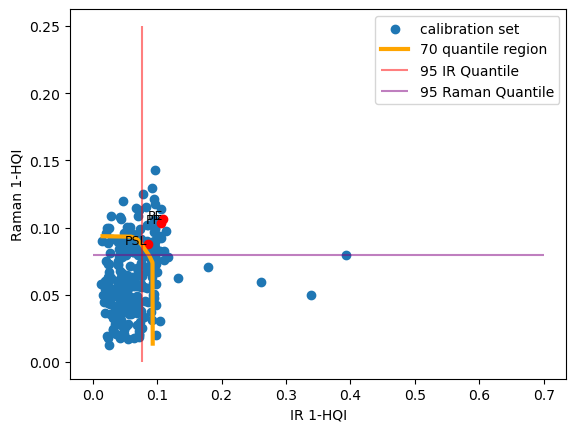

MVCP ['PSL']
IR []
Raman []


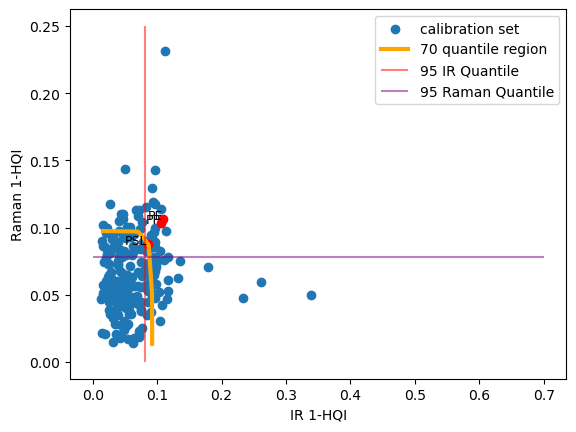

MVCP ['PSL']
IR []
Raman []


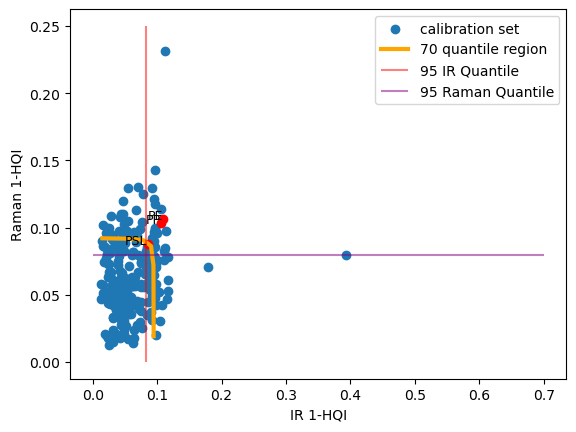

MVCP []
IR []
Raman []


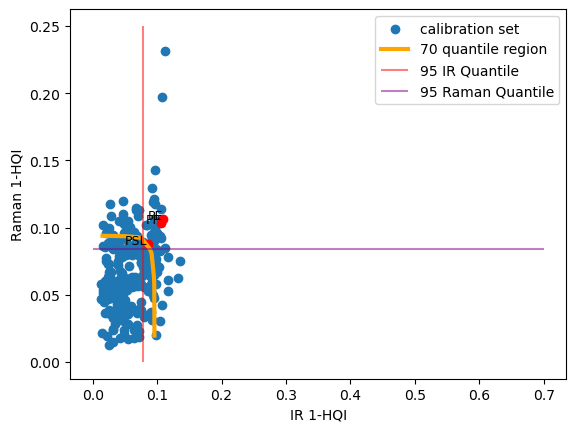

MVCP []
IR []
Raman []


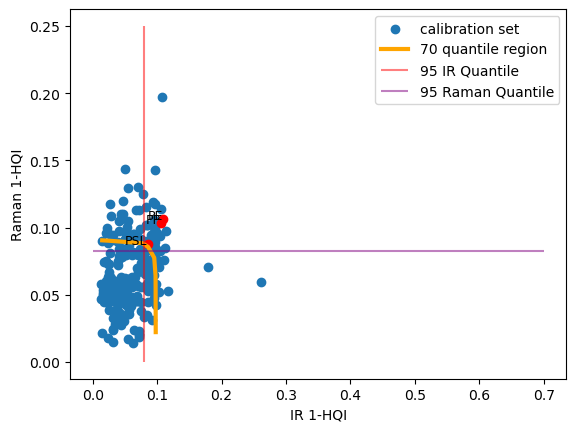

MVCP ['PSL']
IR []
Raman []


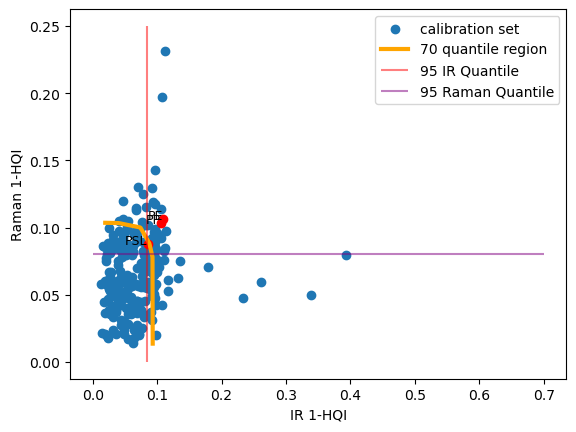

MVCP ['PSL']
IR []
Raman []


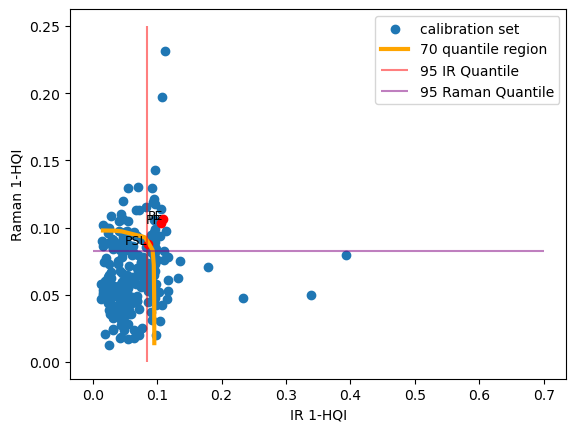

MVCP ['PSL']
IR []
Raman []


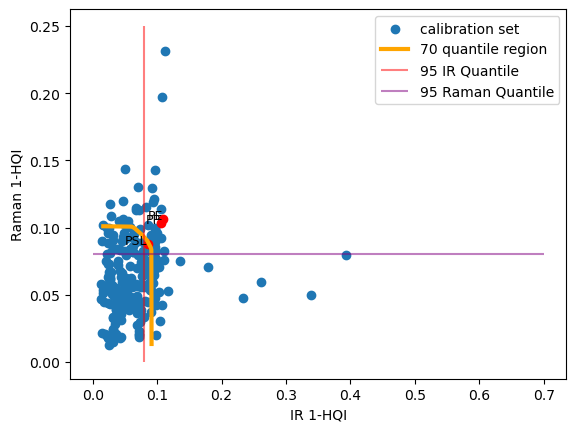

MVCP ['PSL']
IR []
Raman []


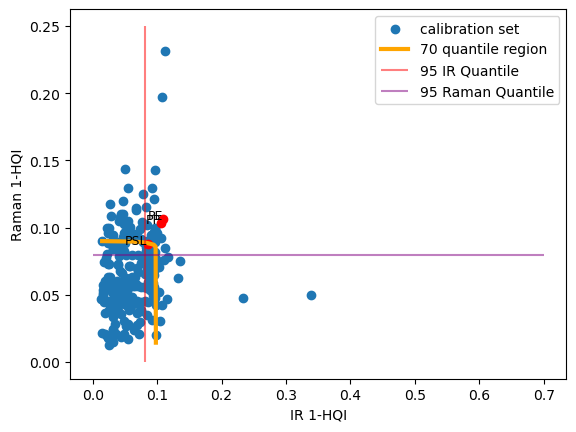

MVCP []
IR []
Raman []


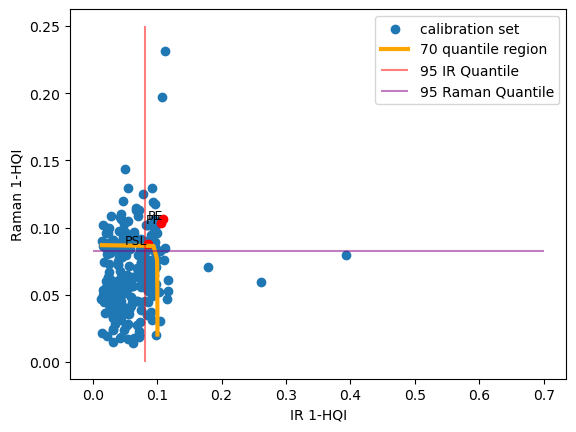

MVCP []
IR []
Raman []


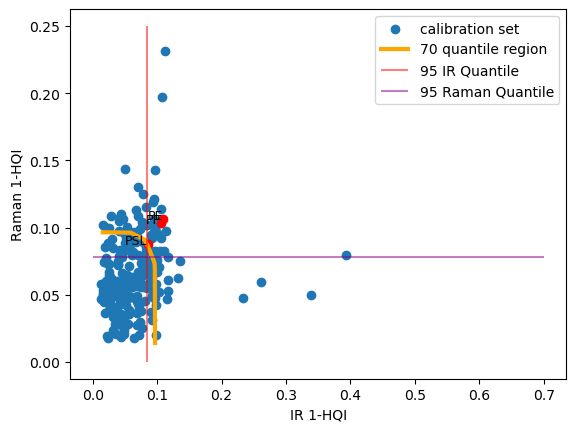

MVCP ['PSL']
IR []
Raman []


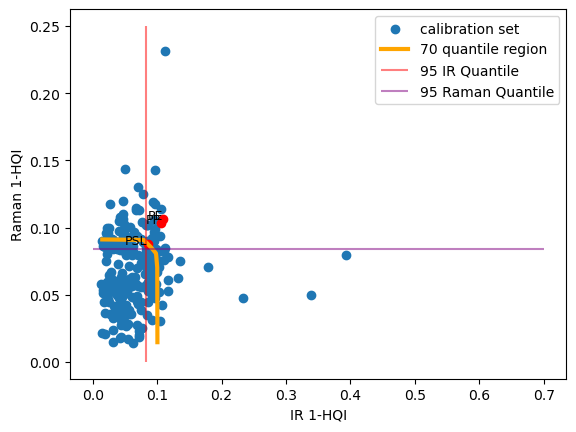

MVCP []
IR []
Raman []


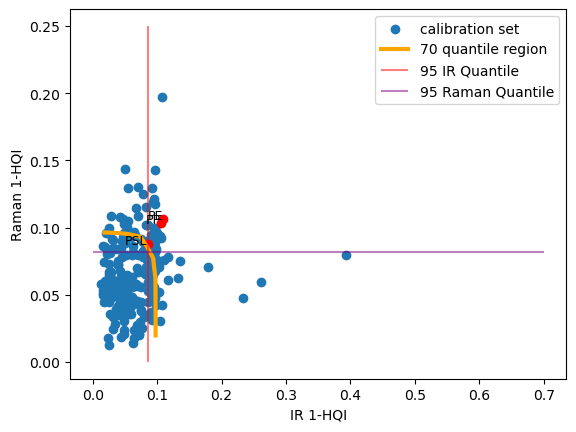

MVCP []
IR []
Raman []


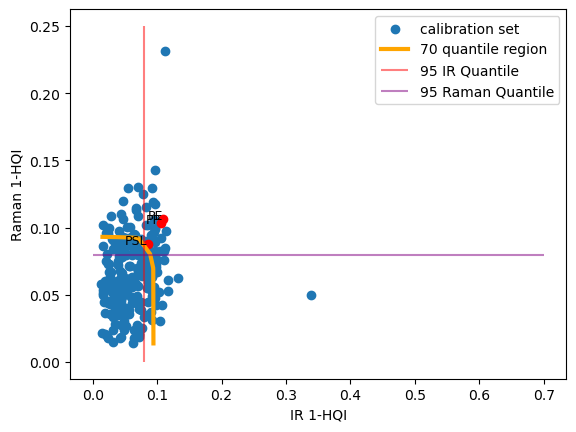

MVCP ['PSL']
IR []
Raman []


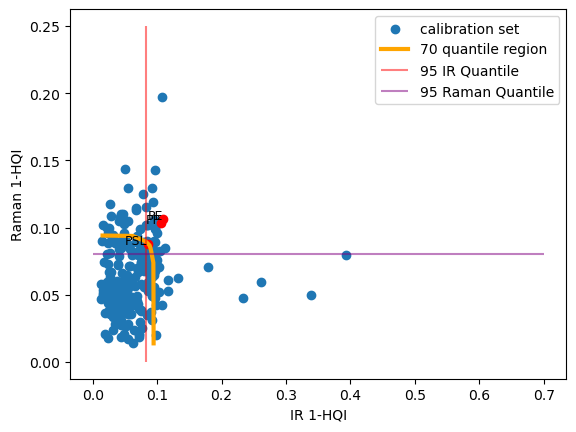

MVCP ['PSL']
IR []
Raman []


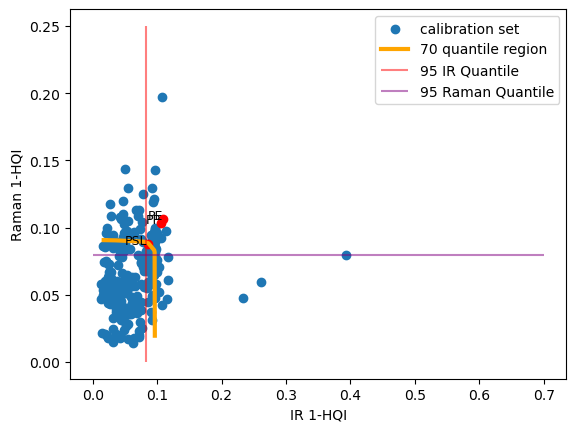

MVCP ['PSL']
IR []
Raman []


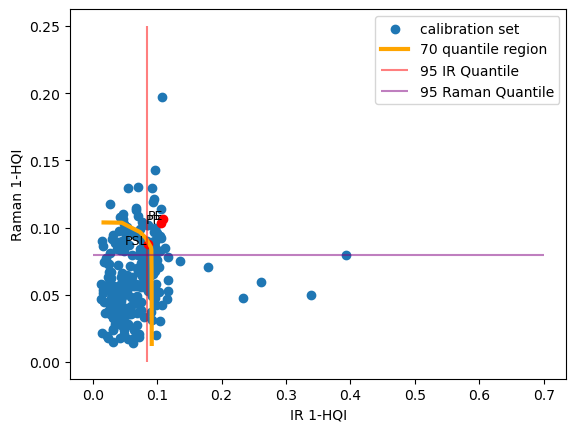

MVCP ['PSL']
IR []
Raman []


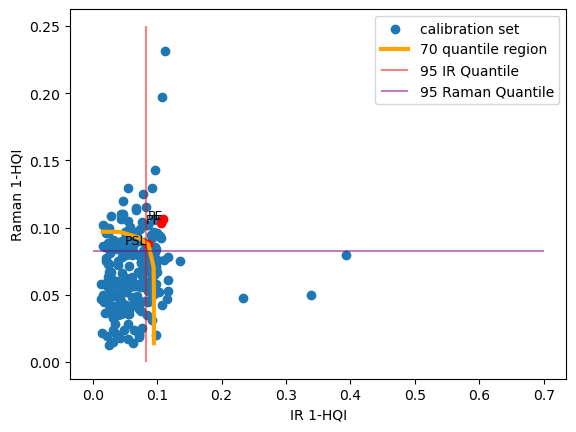

MVCP []
IR []
Raman []


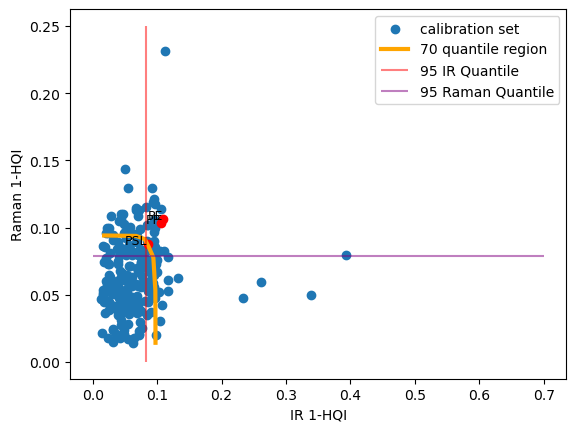

MVCP []
IR []
Raman []


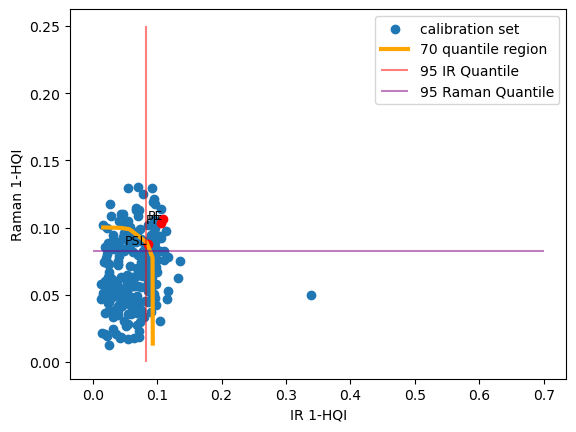

MVCP ['PSL']
IR []
Raman []


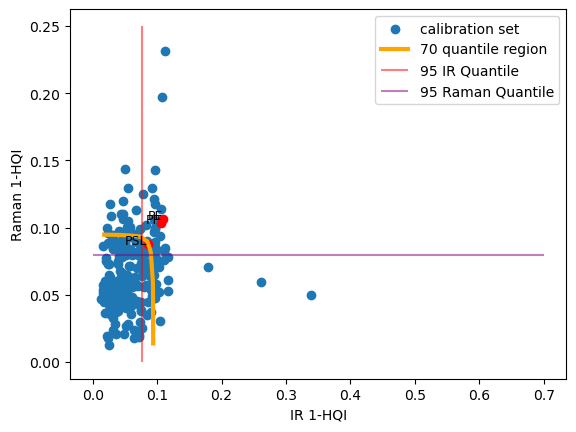

MVCP []
IR []
Raman []


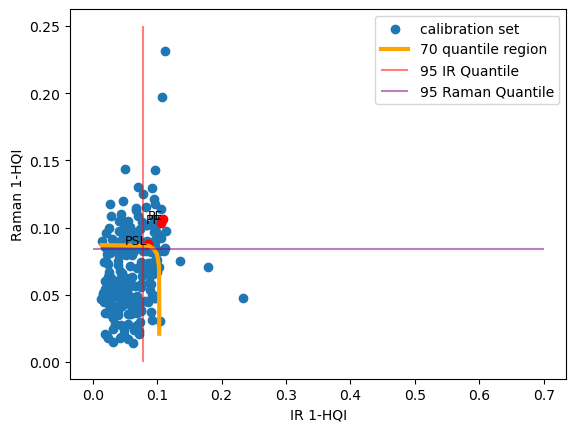

MVCP []
IR []
Raman []


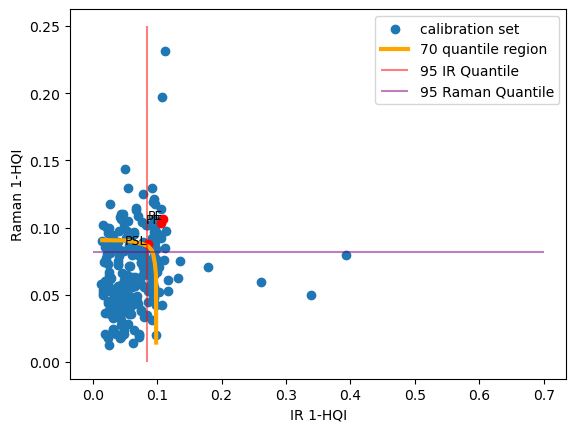

MVCP []
IR []
Raman []


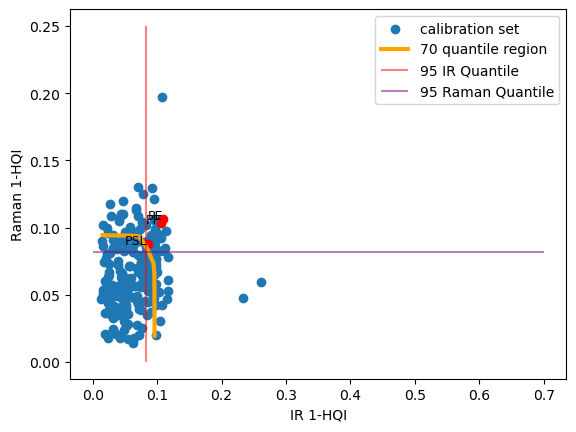

MVCP ['PSL']
IR []
Raman []


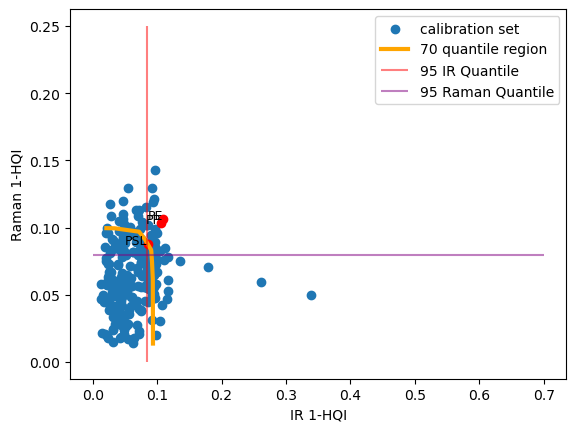

MVCP []
IR []
Raman []


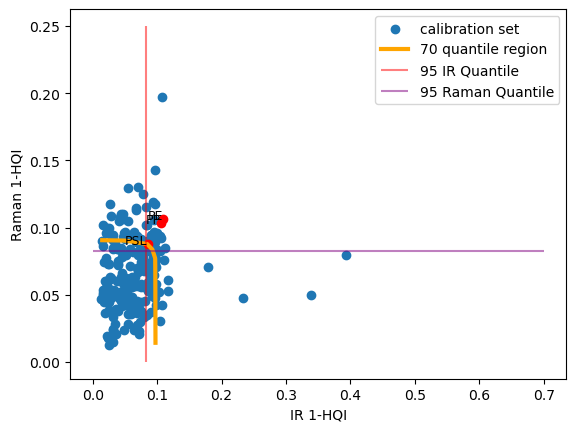

MVCP ['PSL']
IR []
Raman []


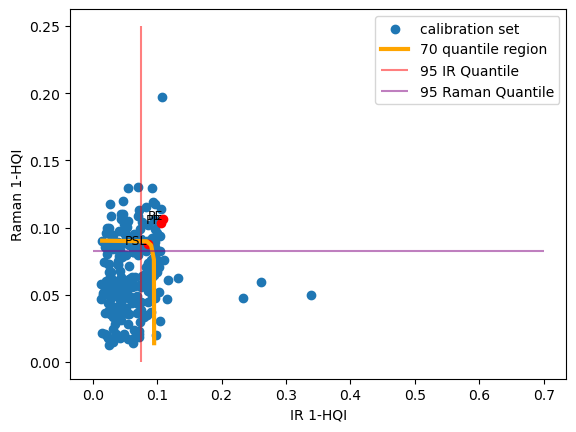

MVCP ['PSL']
IR []
Raman []


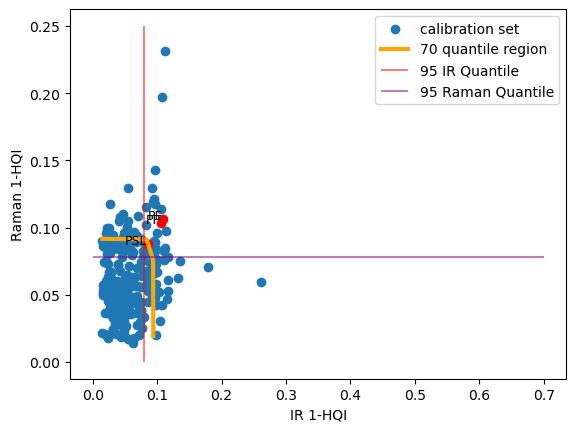

MVCP []
IR []
Raman []


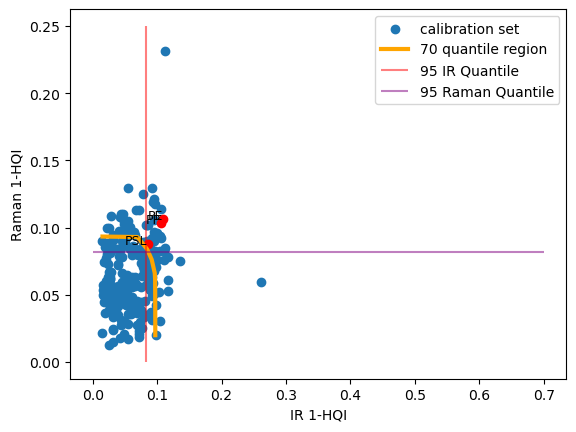

MVCP []
IR []
Raman []


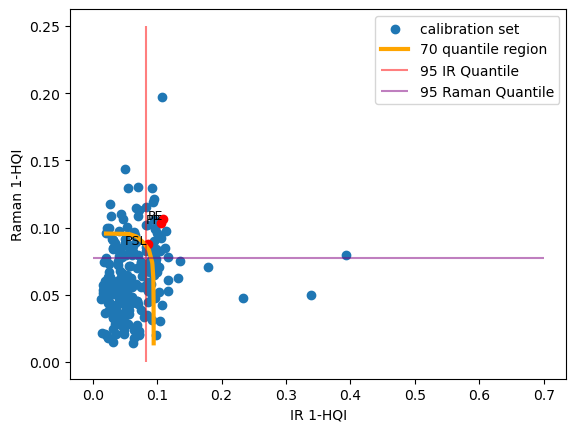

MVCP []
IR []
Raman []


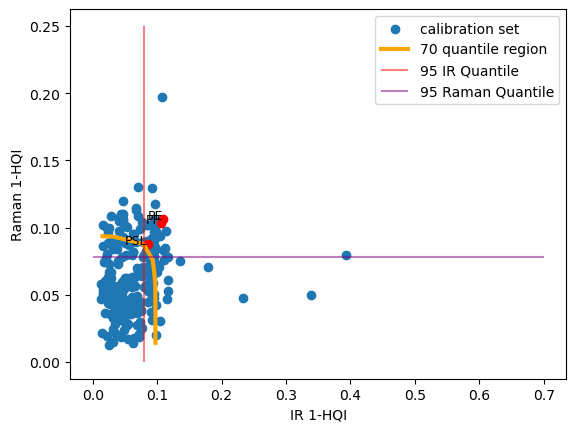

MVCP ['PSL']
IR []
Raman []


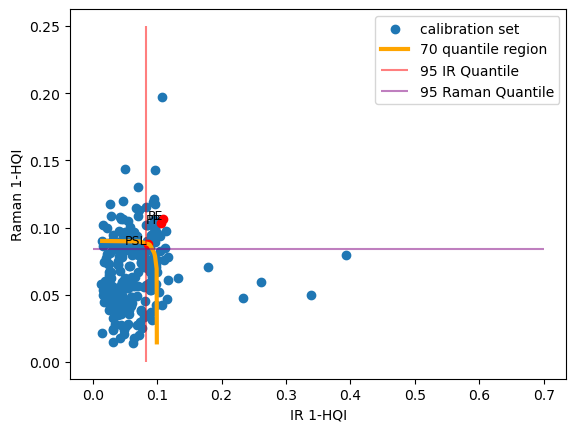

MVCP ['PSL']
IR []
Raman []


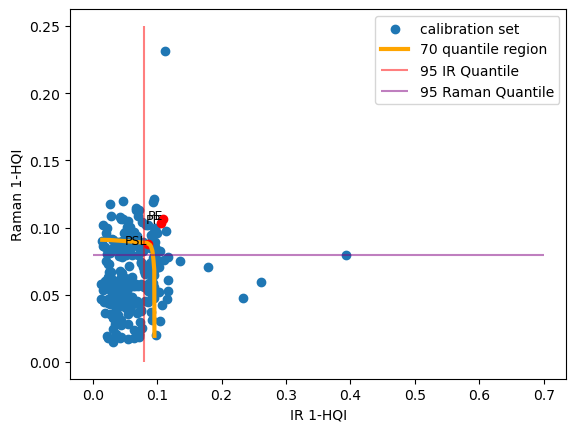

MVCP []
IR []
Raman []


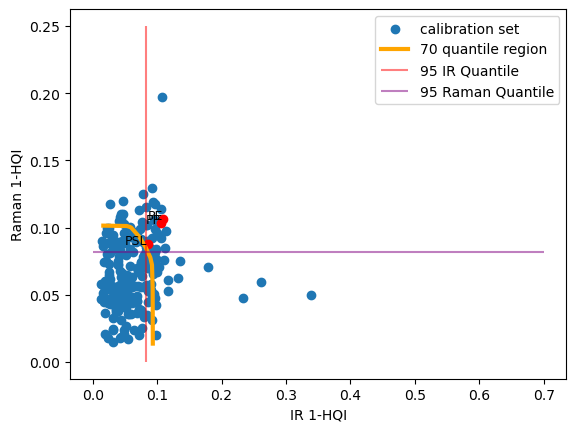

MVCP ['PSL']
IR []
Raman []


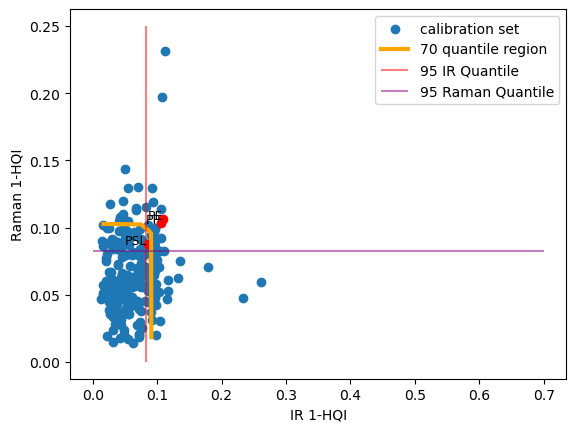

MVCP []
IR []
Raman []


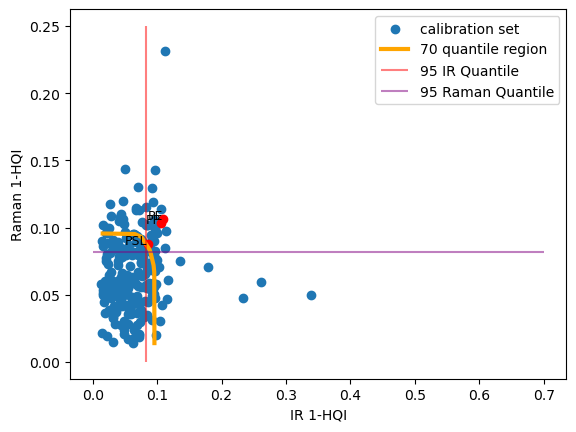

MVCP ['PSL']
IR []
Raman []


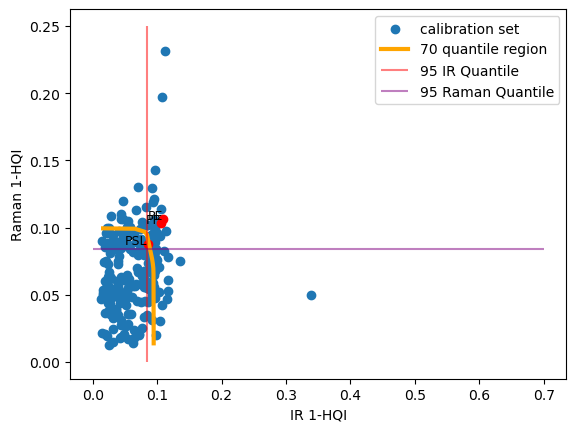

MVCP ['PSL']
IR []
Raman []


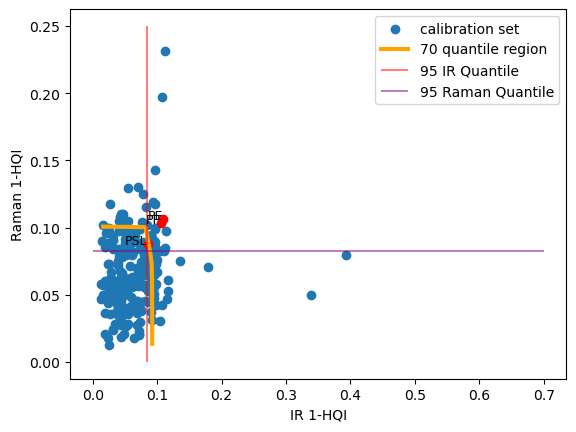

MVCP []
IR []
Raman []


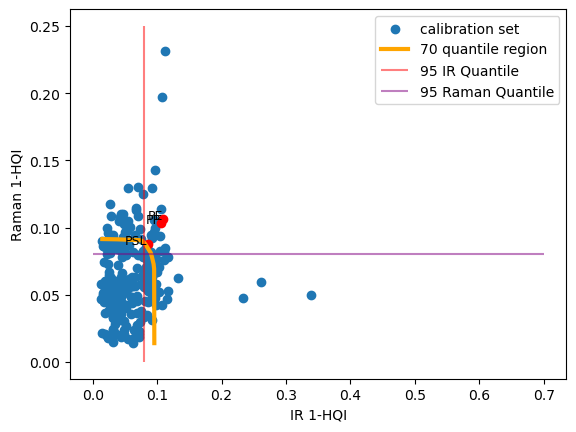

MVCP []
IR []
Raman []


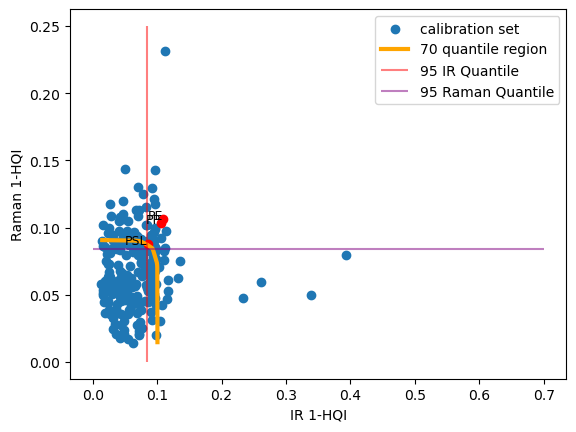

MVCP []
IR []
Raman []


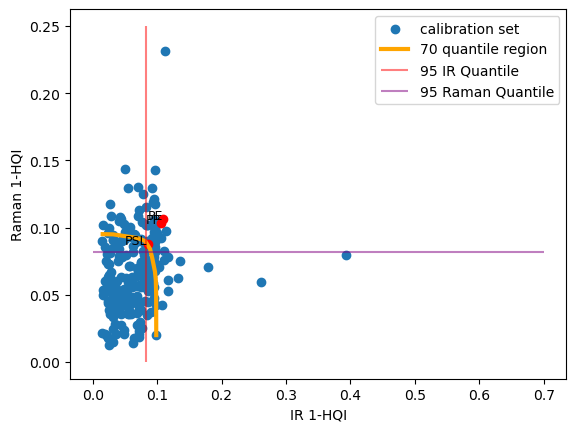

MVCP ['PSL']
IR []
Raman []


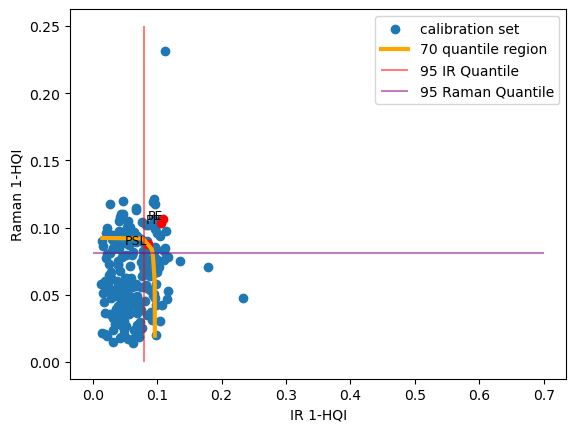

MVCP []
IR []
Raman []


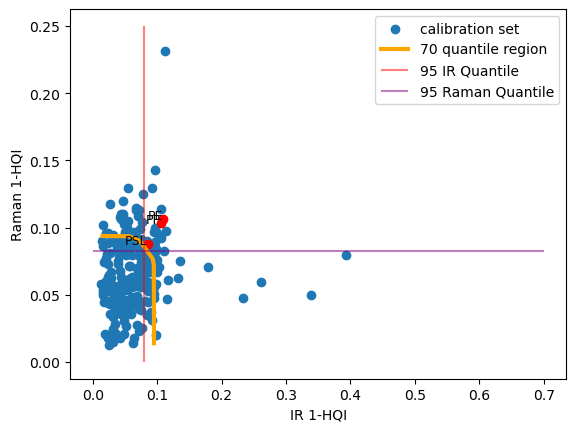

MVCP []
IR []
Raman []


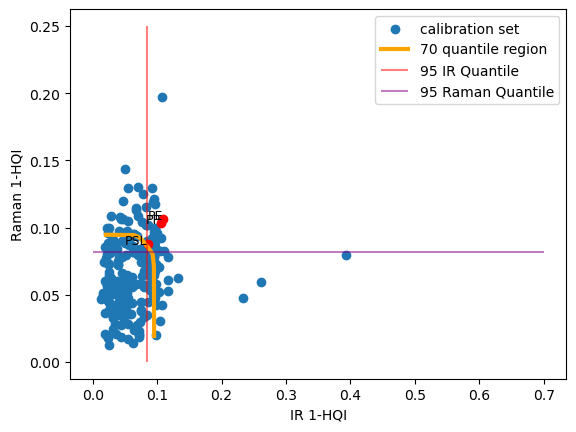

MVCP []
IR []
Raman []


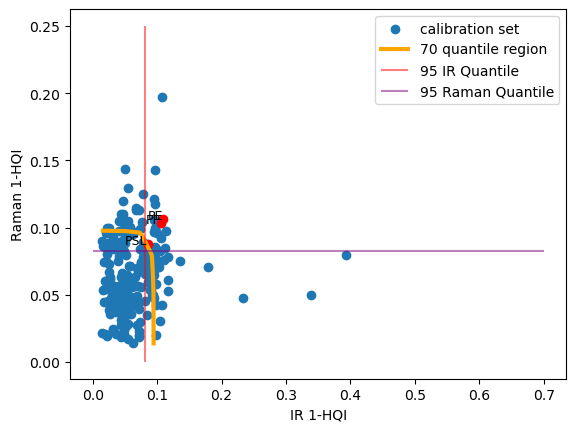

MVCP []
IR []
Raman []


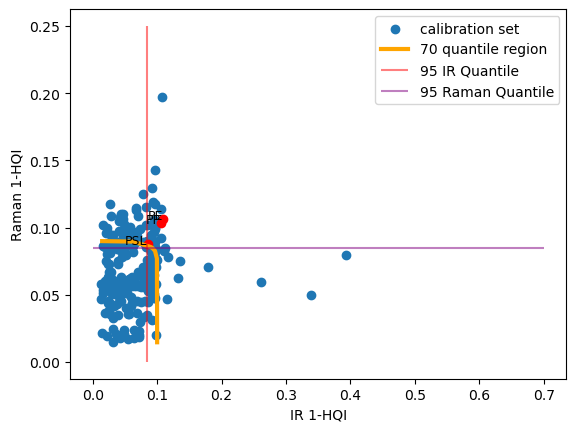

MVCP ['PSL']
IR []
Raman []


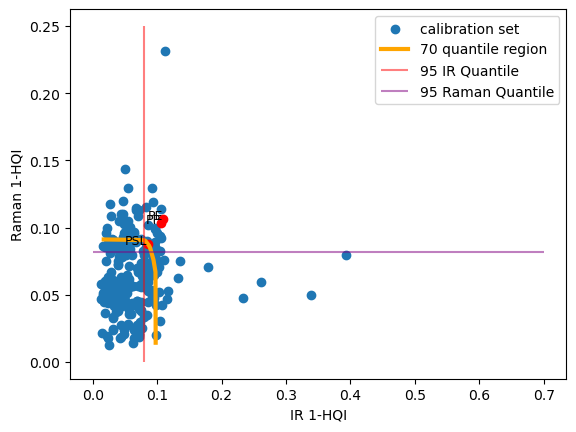

MVCP []
IR []
Raman []


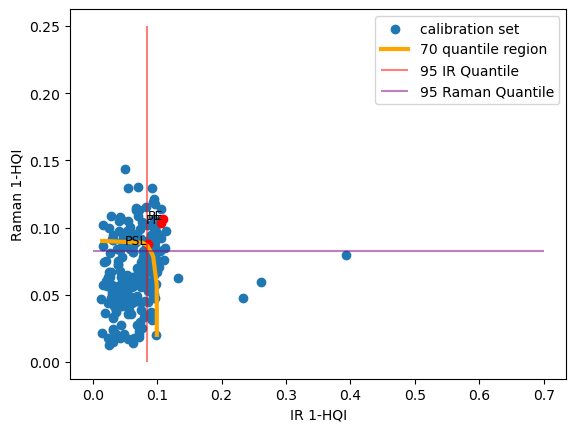

MVCP []
IR []
Raman []


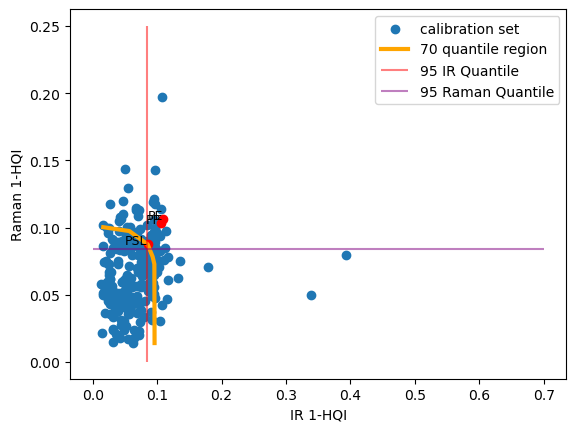

MVCP []
IR []
Raman []


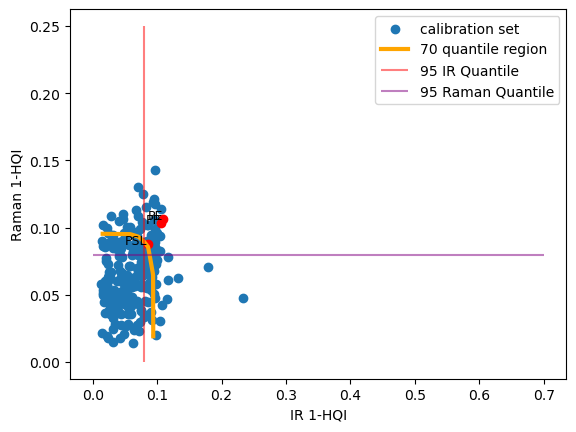

MVCP ['PSL']
IR []
Raman []


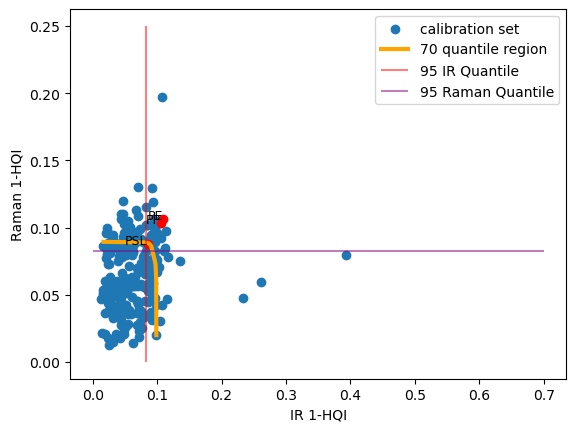

MVCP []
IR []
Raman []


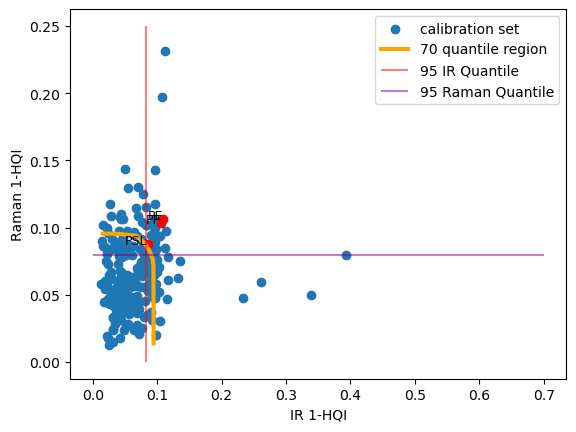

MVCP []
IR []
Raman []


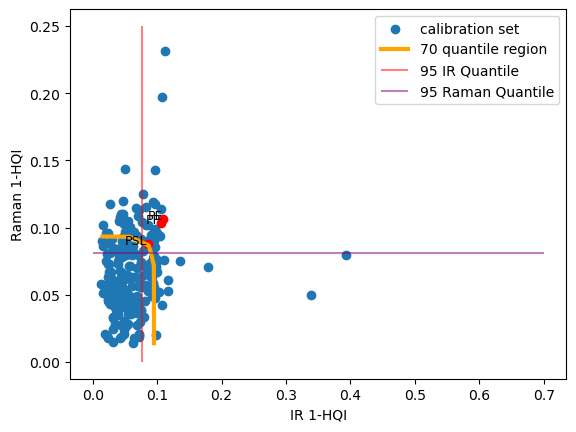

MVCP []
IR []
Raman []


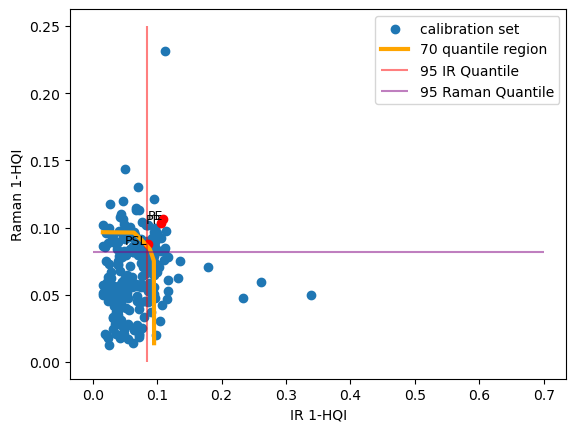

MVCP []
IR []
Raman []


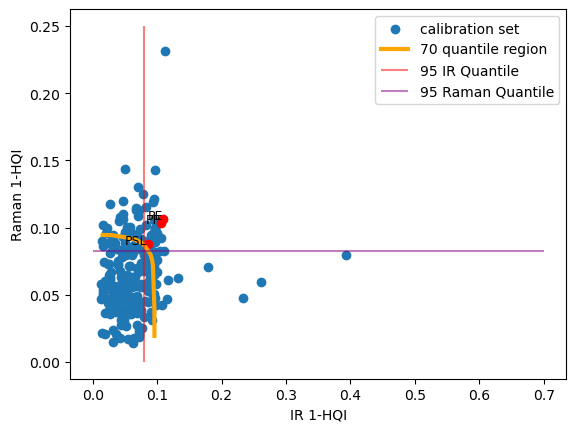

MVCP ['PSL']
IR []
Raman []


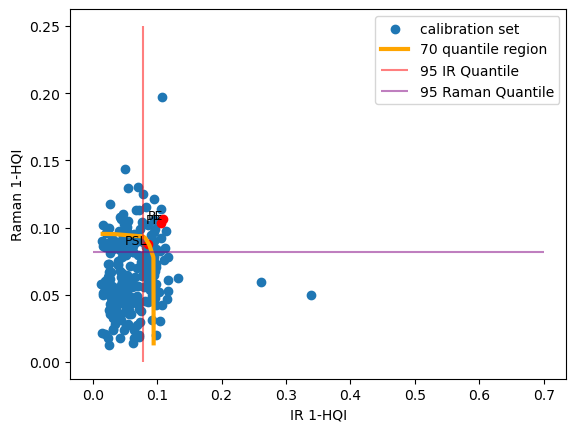

MVCP []
IR []
Raman []


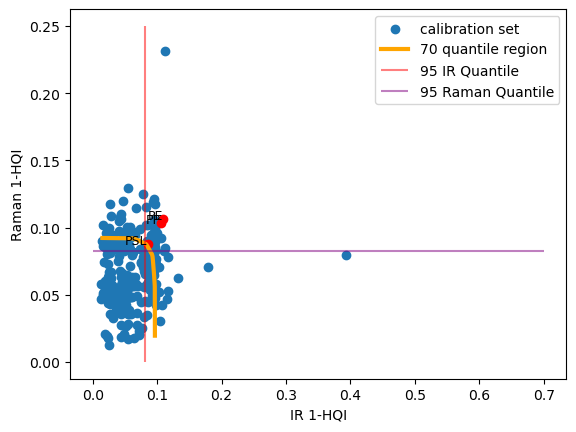

MVCP []
IR []
Raman []


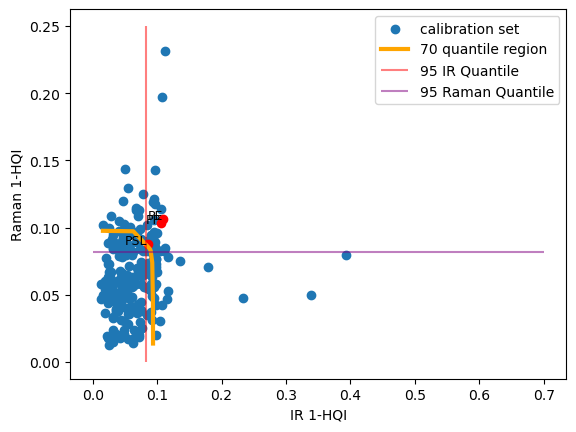

MVCP ['PSL']
IR []
Raman []


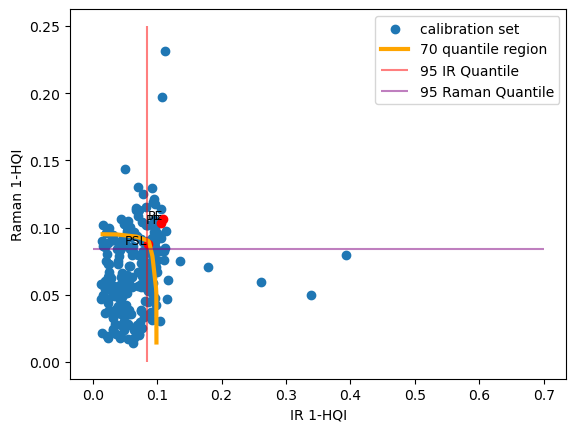

MVCP []
IR []
Raman []


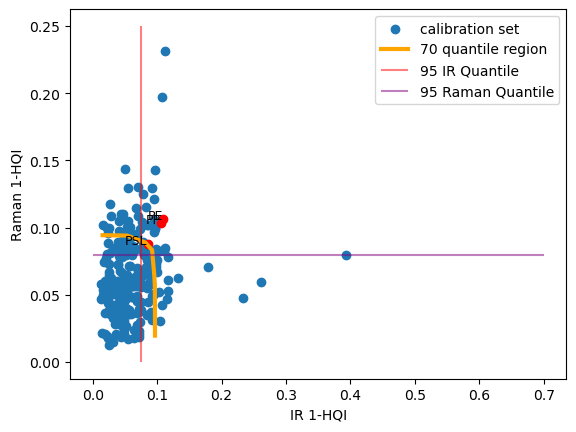

MVCP ['PSL']
IR []
Raman []


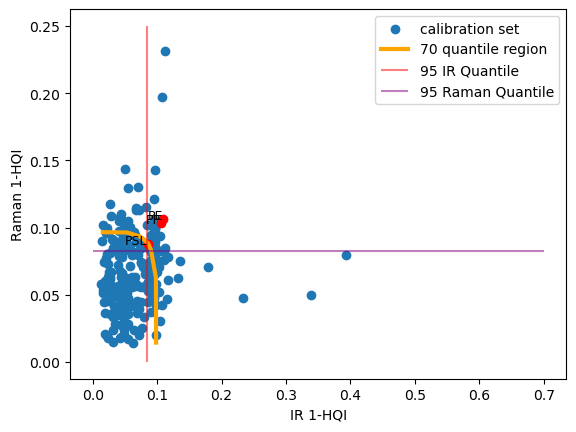

MVCP []
IR []
Raman []


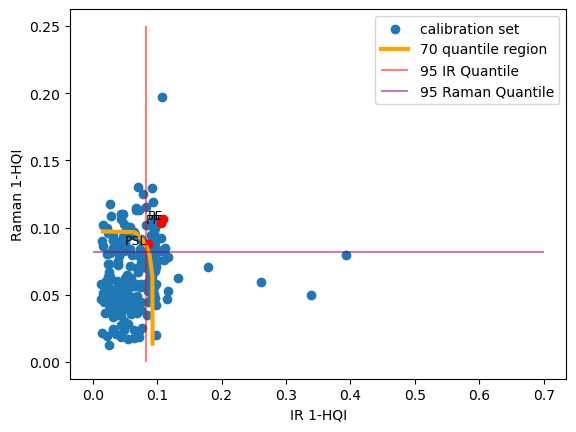

MVCP []
IR []
Raman []


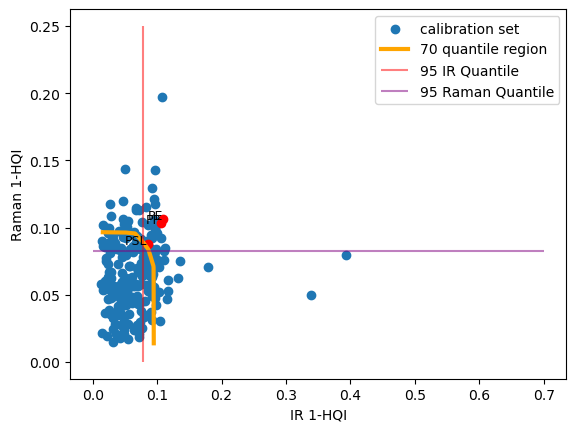

MVCP []
IR []
Raman []


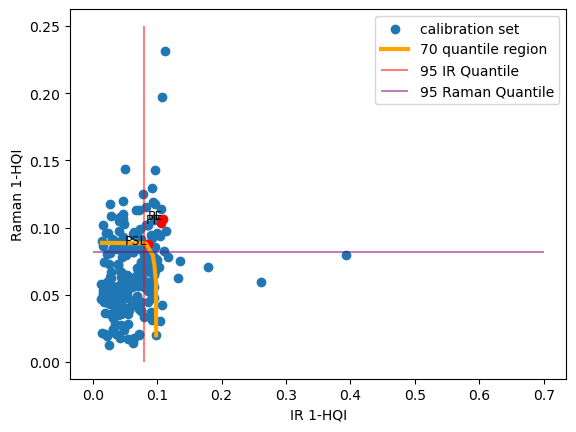

MVCP ['PSL']
IR []
Raman []


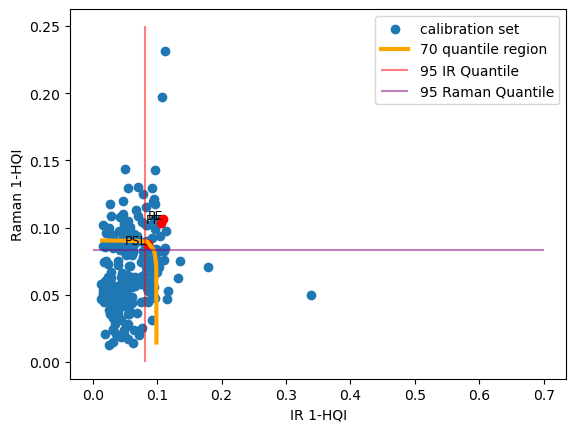

MVCP []
IR []
Raman []


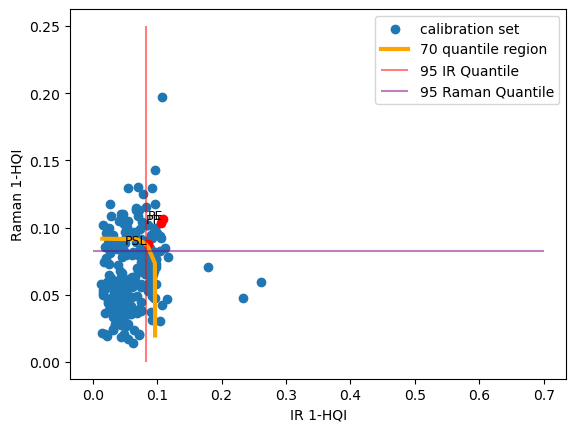

MVCP []
IR []
Raman []


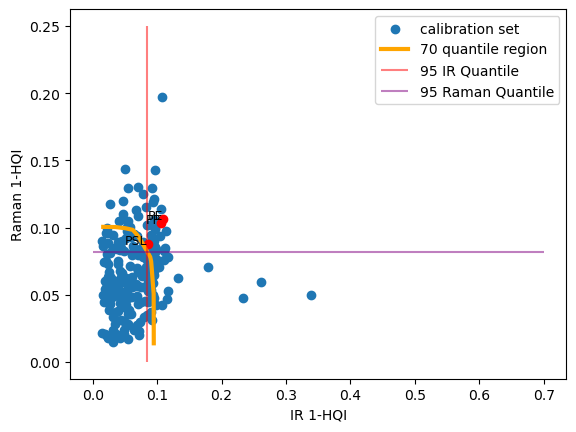

MVCP []
IR []
Raman []


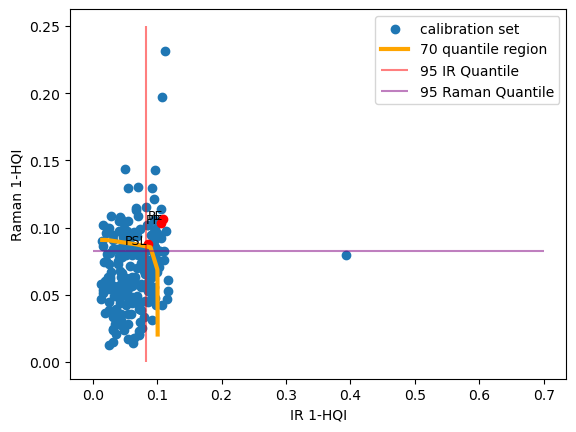

MVCP []
IR []
Raman []


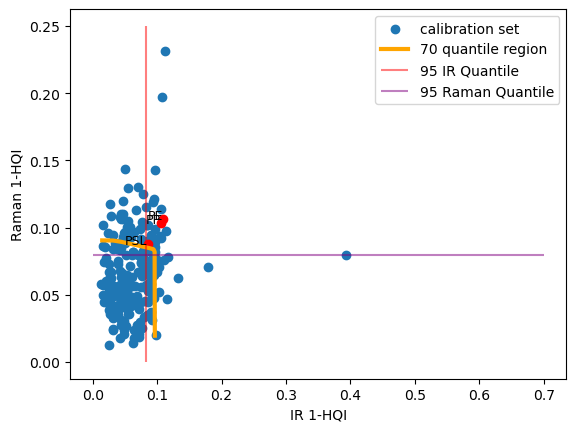

MVCP ['PSL']
IR []
Raman []


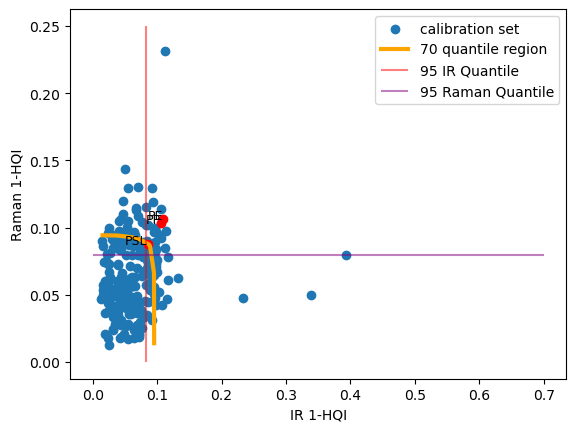

MVCP ['PSL']
IR []
Raman []


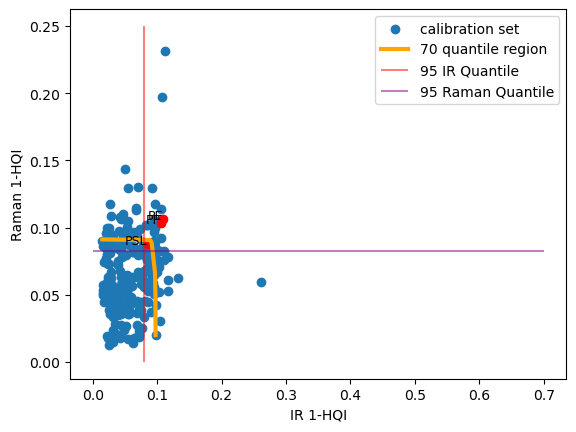

MVCP ['PSL']
IR ['PSL']
Raman []


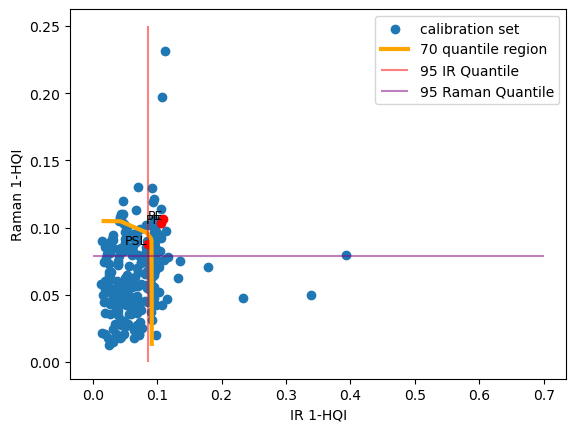

MVCP ['PSL']
IR []
Raman []


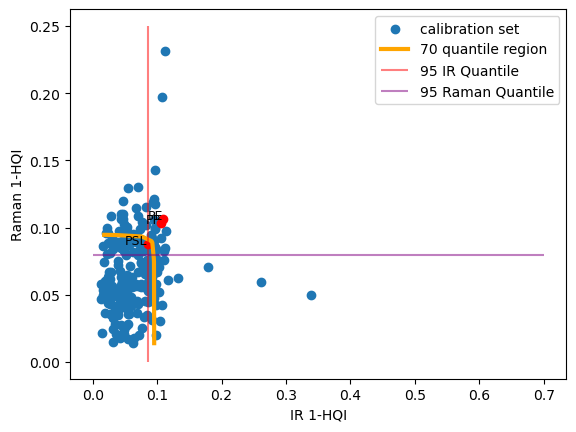

MVCP []
IR []
Raman []


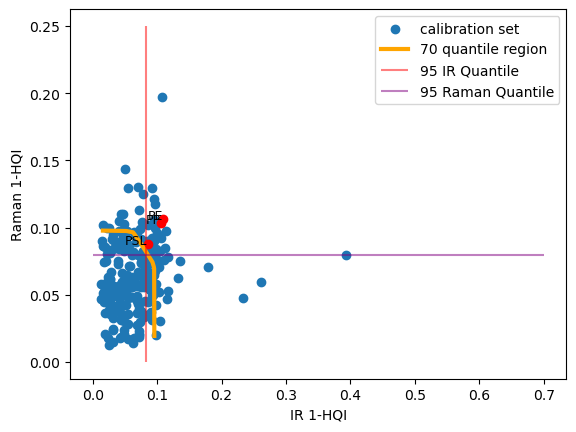

MVCP []
IR []
Raman []


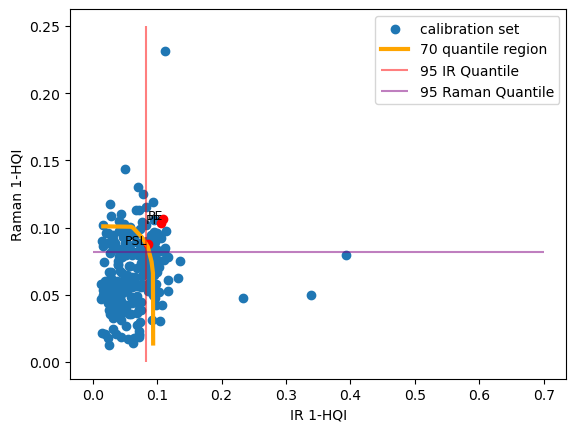

MVCP ['PSL']
IR []
Raman []


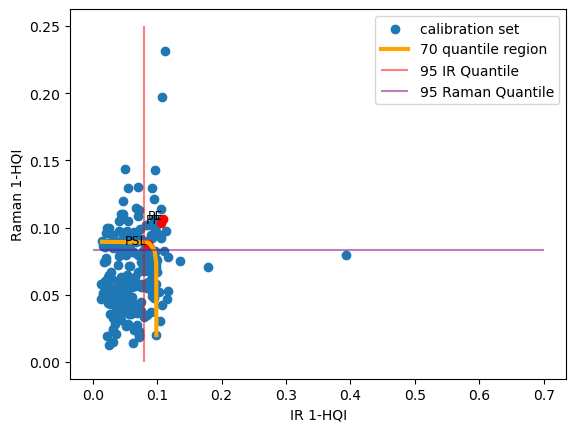

MVCP []
IR []
Raman []


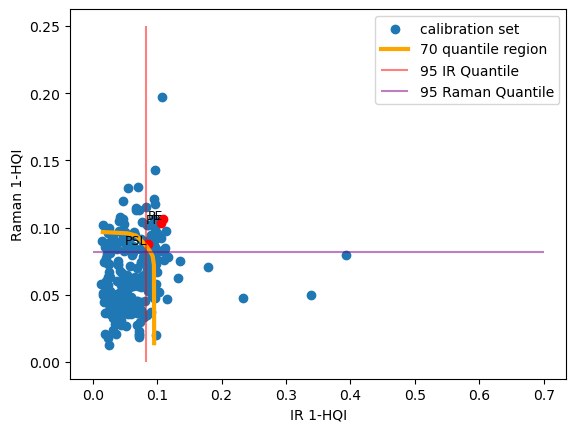

MVCP []
IR []
Raman []


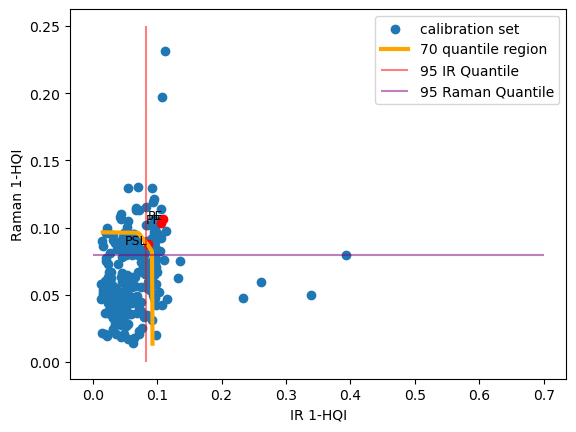

MVCP []
IR []
Raman []


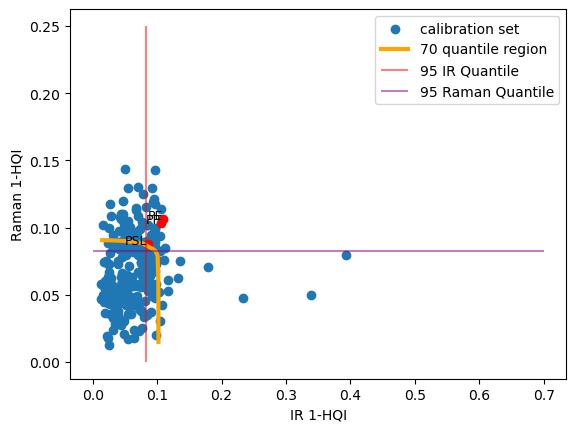

MVCP ['PSL']
IR []
Raman []


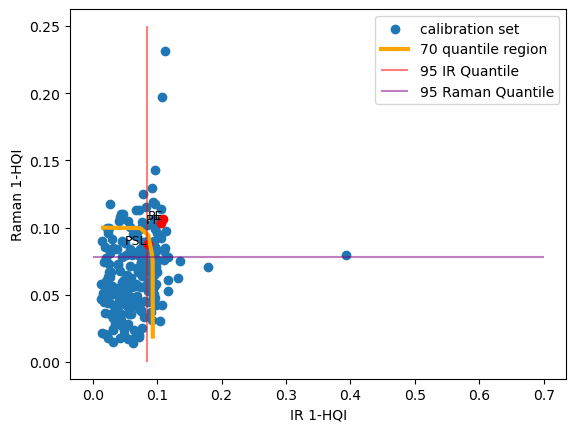

MVCP ['PSL']
IR []
Raman []


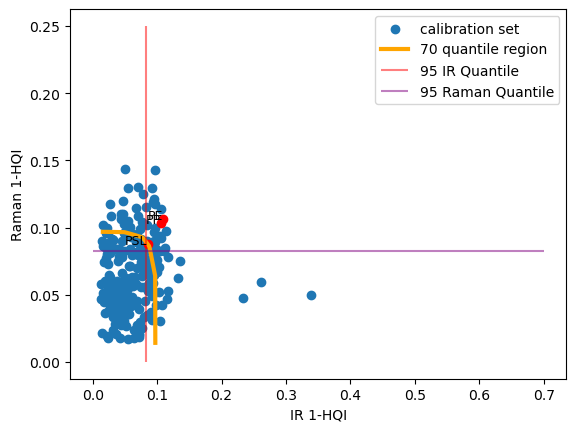

MVCP []
IR []
Raman []


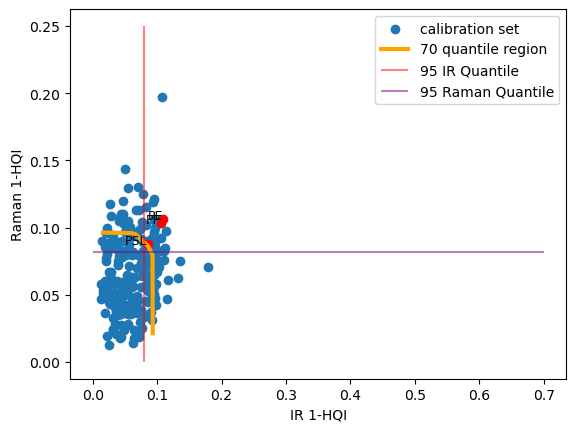

100%|█████████████████████████████████████████████| 1/1 [00:50<00:00, 50.45s/it]


In [102]:
(ps_list, 
         ps_ir_list, 
         ps_raman_list, 
         env_list, 
         cal_smx_arr, 
         cal_idx_list, 
         q_ir_list, 
         q_raman_list) = envelop(score_list, 
                                 label_ir, 
                                 score_example,
                                 alphas=[0.30],
                                 label_table=label_table,
                                 N_sim=100, 
                                 quant_prop=.2, 
                                 cal_prop=0.8, 
                                 seed_init=0)

In [74]:
len(env_list[30])

5

PE


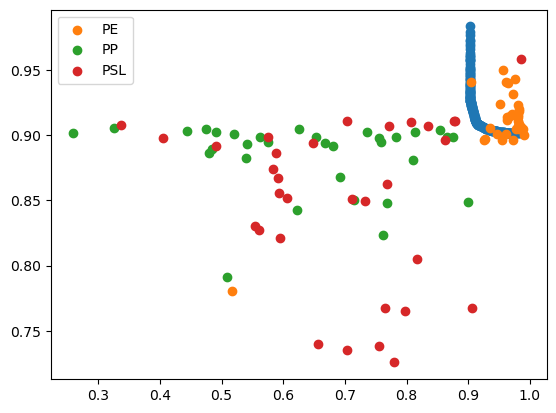

PP


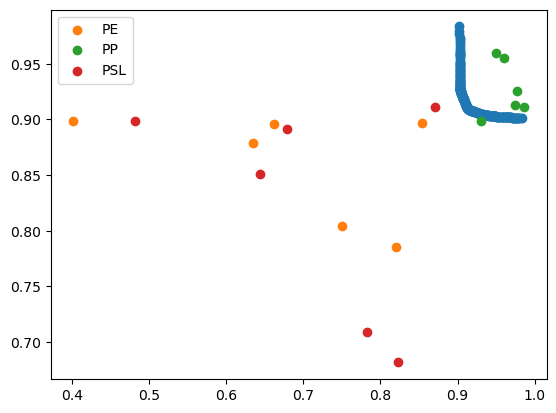

PSL


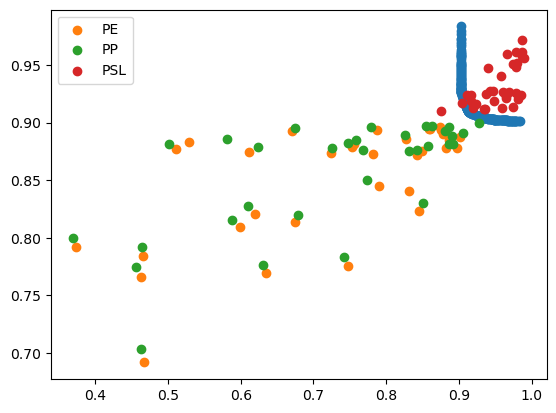

z_AMB


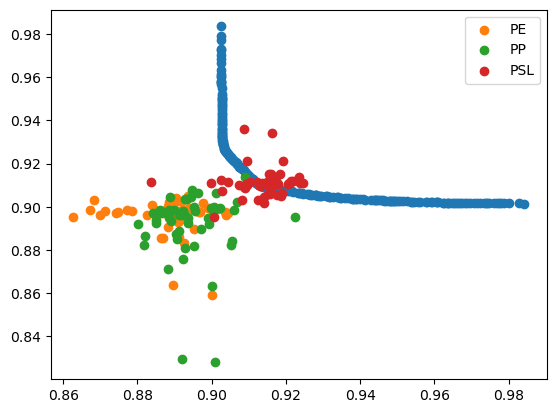

z_LOW


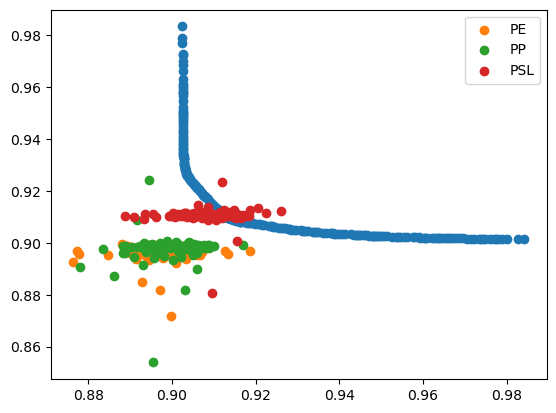

z_MIX


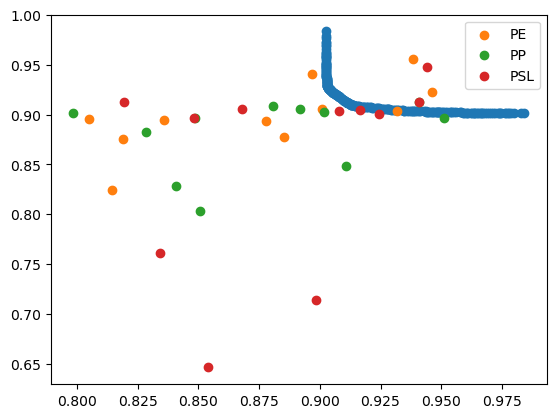

z_UNS


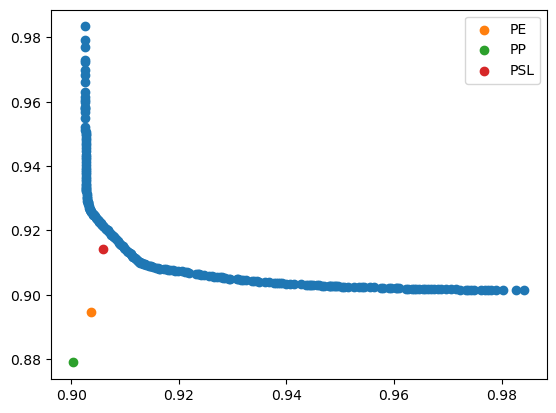

In [76]:
for p in np.unique(data_fig_5_top_hqi_values['polymer']):
    print(p)
    plt.scatter(
    1-np.mean([env_list[25][i][0] for i in range(5)], 0),
    1-np.mean([env_list[25][i][1] for i in range(5)], 0))

    for i in range(3):
        plt.scatter(data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i],
                    data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i+3], 
                    label=np.unique(data_fig_5_top_hqi_values['polymer'])[i])
    plt.legend()
    plt.show()
    
    

IndexError: list index out of range

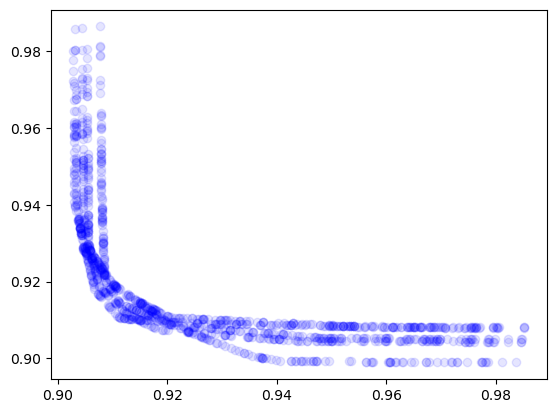

In [84]:
for i in range(100):    
    plt.scatter(1-env_list[30][i][0],
                    1-env_list[30][i][1],
                color='blue',
                alpha=.1)

In [91]:
len(env_list_list)

253

In [73]:
[[x, label_amb_table.iloc[y,1]] for x,y in zip(pred_set_list['IR'], label_amb_ir)]

[[['PSL'], 'PSL'],
 [['PSL'], 'z_AMB'],
 [[], 'z_LOW'],
 [[], 'z_UNS'],
 [['PE'], 'PE'],
 [[], 'z_AMB'],
 [['PSL'], 'z_AMB'],
 [[], 'z_AMB'],
 [['PE'], 'PE'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PSL'], 'PSL'],
 [['PE'], 'PE'],
 [[], 'z_AMB'],
 [[], 'PSL'],
 [['PSL'], 'PSL'],
 [[], 'z_LOW'],
 [['PSL'], 'z_AMB'],
 [[], 'z_LOW'],
 [['PE'], 'PE'],
 [['PSL'], 'PSL'],
 [[], 'z_AMB'],
 [[], 'PE'],
 [['PE'], 'z_MIX'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PP'], 'PP'],
 [['PP'], 'PP'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PSL'], 'PSL'],
 [[], 'z_LOW'],
 [['PSL'], 'PSL'],
 [[], 'z_AMB'],
 [[], 'z_AMB'],
 [['PE'], 'PE'],
 [['PSL'], 'PSL'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PSL'], 'z_MIX'],
 [[], 'z_LOW'],
 [['PSL'], 'z_LOW'],
 [[], 'z_LOW'],
 [['PSL'], 'z_AMB'],
 [['PSL'], 'z_MIX'],
 [['PSL'], 'z_LOW'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PE'], 'PE'],
 [['PSL'], 'z_AMB'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [['PE'], 'z_MIX'],
 [[], 'z_LOW'],
 [[], 'z_LOW'],
 [[], 'z_LO

In [74]:
(np.mean([label_amb_table.iloc[y,1] in x if y < 3 else len(x)==0 for x,y in zip(pred_set_list['mvcp'], label_amb_ir)]),
 np.mean([label_amb_table.iloc[y,1] in x for x,y in zip(pred_set_list['mvcp'], label_amb_ir) if y < 3]))

(0.8379446640316206, 0.8732394366197183)

In [75]:
(np.mean([label_amb_table.iloc[y,1] in x if y < 3 else len(x)==0 for x,y in zip(pred_set_list['IR'], label_amb_ir)]),
 np.mean([label_amb_table.iloc[y,1] in x for x,y in zip(pred_set_list['IR'], label_amb_ir) if y < 3]))


(0.8300395256916996, 0.9295774647887324)

In [76]:
np.mean([label_amb_table.iloc[y,1] in x if y < 3 else len(x)==0 for x,y in zip(pred_set_list['Raman'], label_amb_ir)])


0.8181818181818182

In [23]:
ps_list[40]

[['PSL']]

In [177]:
np.unique(data_fig_5_top_hqi_values['polymer'])

array(['PE', 'PP', 'PSL', 'z_AMB', 'z_LOW', 'z_MIX', 'z_UNS'],
      dtype=object)

PE


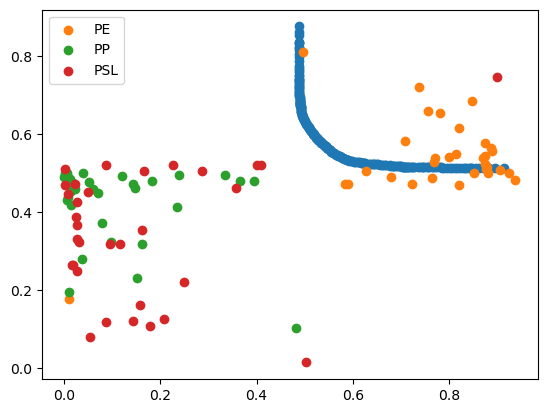

PP


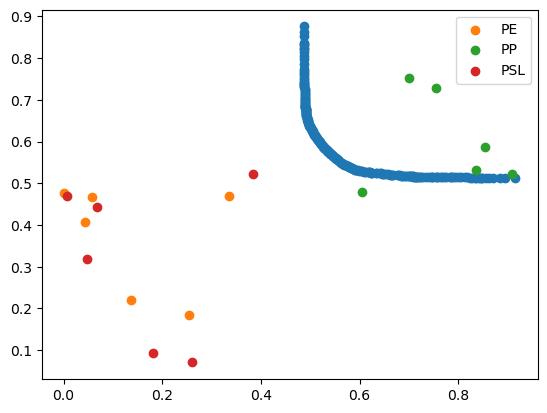

PSL


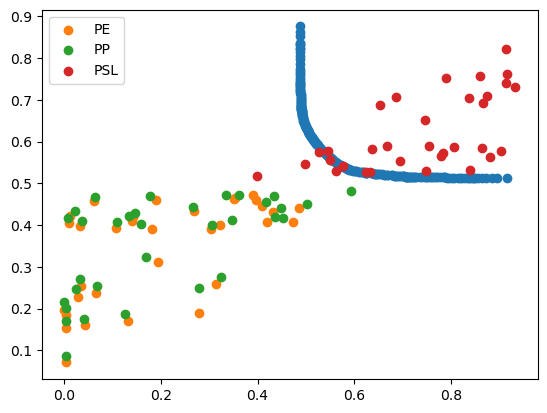

z_AMB


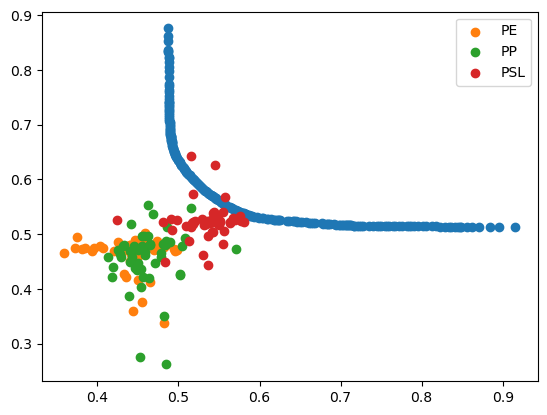

z_LOW


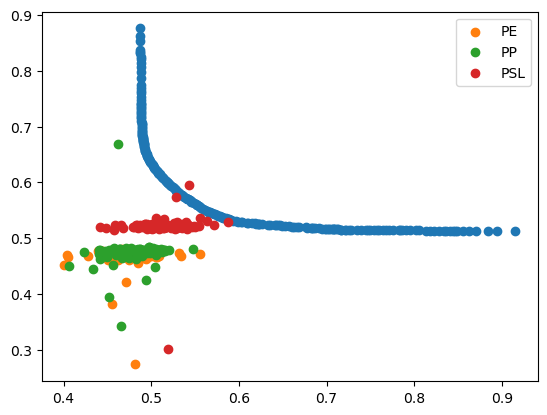

z_MIX


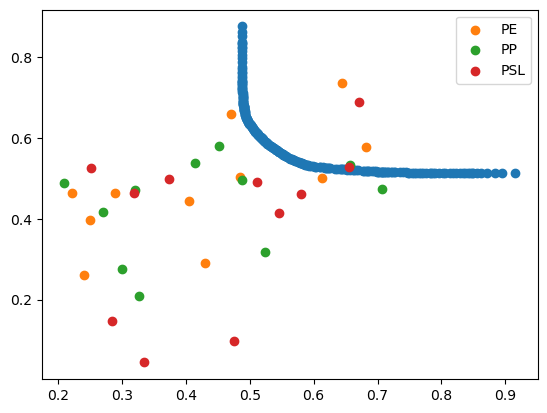

z_UNS


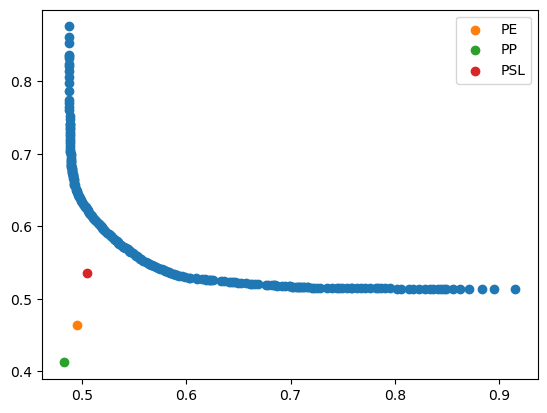

In [143]:
for p in np.unique(data_fig_5_top_hqi_values['polymer']):
    print(p)
    plt.scatter(data_fig_5_envelopes.loc[:,'x - 72 (mean)'],
                data_fig_5_envelopes.loc[:,'y - 72 (mean)'])

    for i in range(3):
        plt.scatter(data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i],
                    data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i+3], 
                    label=np.unique(data_fig_5_top_hqi_values['polymer'])[i])
    plt.legend()
    plt.show()

PE


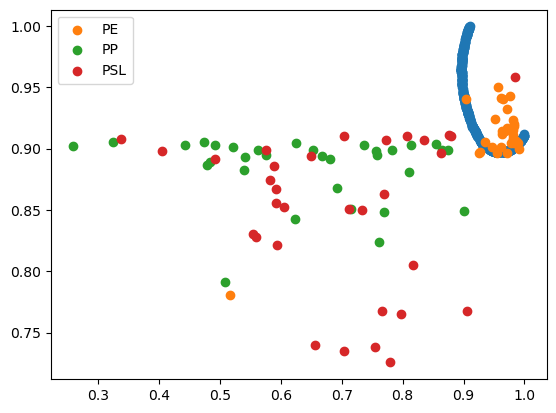

PP


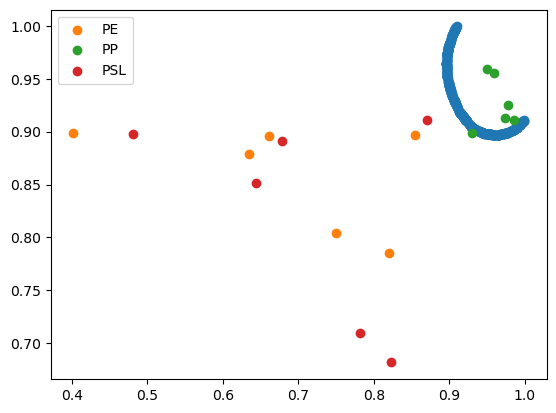

PSL


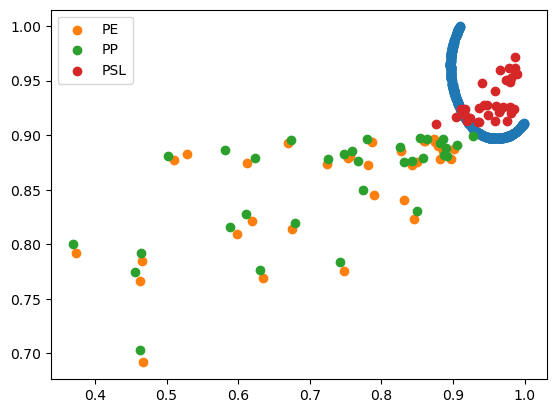

z_AMB


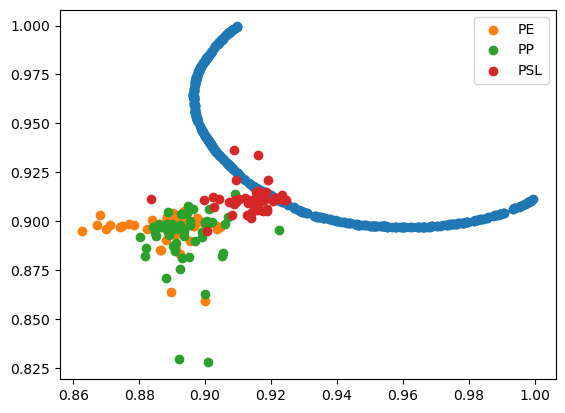

z_LOW


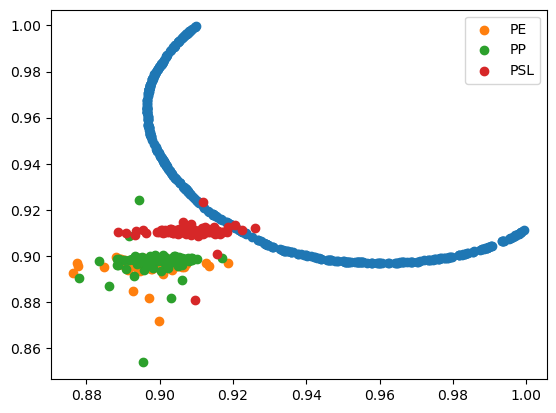

z_MIX


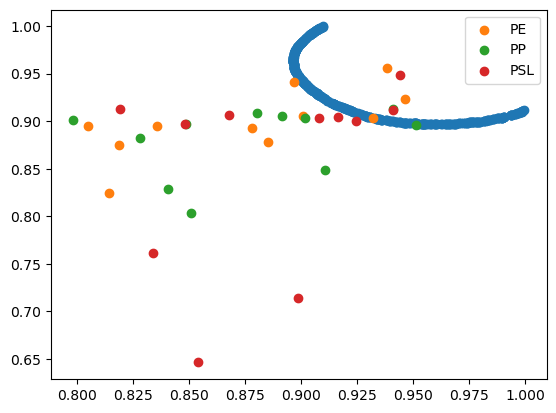

z_UNS


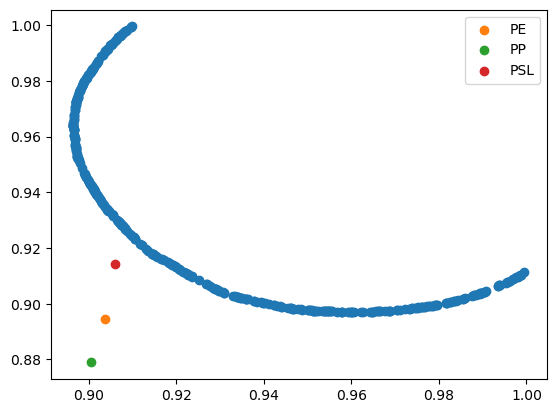

In [80]:
for p in np.unique(data_fig_5_top_hqi_values['polymer']):
    print(p)
    plt.scatter(data_fig_5_envelopes.loc[:,'x - 60 (mean)'],
                data_fig_5_envelopes.loc[:,'y - 60 (mean)'])

    for i in range(3):
        plt.scatter(data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i],
                    data_fig_5_top_hqi_values.query('polymer == @p').iloc[:, i+3], 
                    label=np.unique(data_fig_5_top_hqi_values['polymer'])[i])
    plt.legend()
    plt.show()

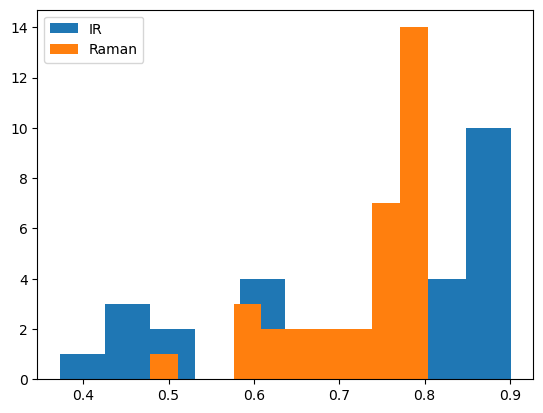

In [24]:
plt.hist(data_fig_5_top_hqi_values.query('polymer == "PSL"').iloc[:, 0], label='IR')
plt.hist((data_fig_5_top_hqi_values.query('polymer == "PSL"').iloc[:, 3])**2, label='Raman')
plt.legend()

In [15]:
np.exp(-.8/.4), np.exp(-.8/.4)

0.1353352832366127

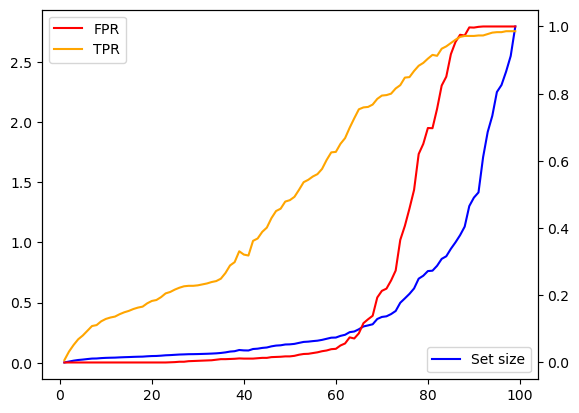

In [87]:
data_fig_5_TPR_FPR = pd.read_csv('results_final/older/data_fig_5_TPR_FPR.csv')
data_fig_5_TPR_FPR['Unnamed: 0'] = 100 - data_fig_5_TPR_FPR['Unnamed: 0']

data_fig_5_TPR_FPR = data_fig_5_TPR_FPR.rename({'Unnamed: 0':'coverage'}, axis=1).set_index('coverage')
data_fig_5_TPR_FPR

fig, ax1 = plt.subplots()

# Plot first dataset (left y-axis)
ax1.plot(data_fig_5_TPR_FPR['Set size (mean)'], color="blue", label='Set size')
ax1.legend(loc='lower right')
#ax1.set_xlabel("X")
#ax1.set_ylabel("sin(x)", color="blue")
#ax1.tick_params(axis="y", labelcolor="blue")

# Create second y-axis (right side)
ax2 = ax1.twinx()
ax2.plot(data_fig_5_TPR_FPR['FPR (mean)'], color="red", label='FPR')
ax2.plot(data_fig_5_TPR_FPR['TPR (mean)'], color="orange", label='TPR')
ax2.legend()

#plt.legend()

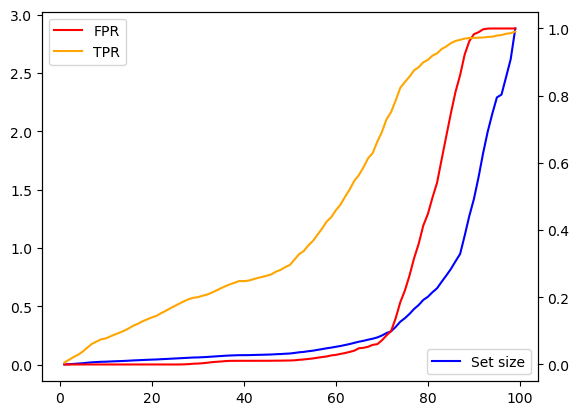

In [88]:
data_fig_5_TPR_FPR = pd.read_csv('results_final/20250921/data_fig_5_TPR_FPR.csv')
data_fig_5_TPR_FPR['Unnamed: 0'] = 100 - data_fig_5_TPR_FPR['Unnamed: 0']

data_fig_5_TPR_FPR = data_fig_5_TPR_FPR.rename({'Unnamed: 0':'coverage'}, axis=1).set_index('coverage')
data_fig_5_TPR_FPR

fig, ax1 = plt.subplots()

# Plot first dataset (left y-axis)
ax1.plot(data_fig_5_TPR_FPR['Set size (mean)'], color="blue", label='Set size')
ax1.legend(loc='lower right')
#ax1.set_xlabel("X")
#ax1.set_ylabel("sin(x)", color="blue")
#ax1.tick_params(axis="y", labelcolor="blue")

# Create second y-axis (right side)
ax2 = ax1.twinx()
ax2.plot(data_fig_5_TPR_FPR['FPR (mean)'], color="red", label='FPR')
ax2.plot(data_fig_5_TPR_FPR['TPR (mean)'], color="orange", label='TPR')
ax2.legend()

#plt.legend()

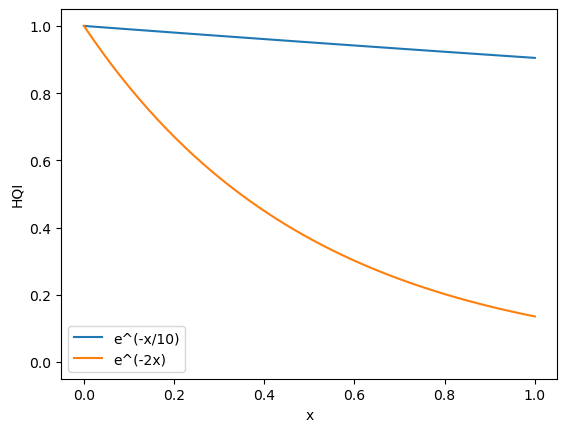

In [101]:
plt.plot(np.linspace(0,1),
         np.exp(-np.linspace(0,1)/10), label='e^(-x/10)')
plt.plot(np.linspace(0,1),
         np.exp(-2*np.linspace(0,1)), label='e^(-2x)')
plt.xlabel('x')
plt.ylabel('HQI')
plt.xlim(-.05,1.05)
plt.ylim(-.05,1.05)
plt.legend()